# S6E11 Fraud | LB 0.95095 | Shallow Digit Models

By [Georgy Mamarin](https://www.kaggle.com/georgymamarin)

Build a fraud submission with four-leaf LightGBM trees and encodings of observed values and decimal digits. The default model scored **0.95095 public AUC** and **0.9502590 out-of-fold (OOF) AUC**. This notebook shows which changes helped on the same validation folds and writes `submission.csv`. Changed settings do not inherit the recorded public score.

### Where to start

- To **build a submission**, change `CURRENT_CFG` in section 0 and inspect the export in section 17.
- To **understand the features**, start with the data in sections 1 to 5 and the encoding comparisons in sections 15 and 18.
- To **compare models**, read section 21 for the fixed logistic blend and section 22 for what happens when only 2% of transactions can be reviewed.

The task is [Playground S6E11: Predicting Credit Card Fraud](https://www.kaggle.com/competitions/playground-series-s6e11). You should be comfortable with pandas and cross-validation.

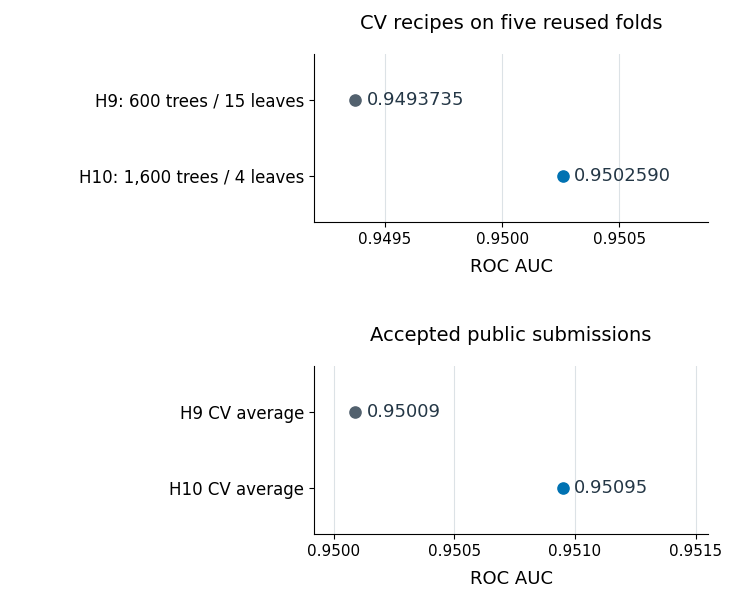

*The upper panel evaluates historical CV predictions; the lower panel evaluates accepted public submissions on hidden test rows. The two panels use different rows.*

### Run and replay details

`CURRENT_CFG` controls the current recipe and primary export. `CFG` controls the original reference and historical experiments. The standard `cv_average` route fits 31 models; `run_research=False` reduces it to ten. A `full_refit` export adds one fit, giving 32 or 11. The reference export cell times its part of the run; the current report times the additional current fit. The Kaggle sidebar reports the entire run.

Sections 11 to 16 and 18 to 22 display labelled recorded investigations. Their optional rerun switches are False by default; reading the findings needs no diagnostic rerun. Section 18 has a separate 50-fit replay, section 19 a 22-fit study with at most one conditional refit, section 20 a 15-fit seed replay, and section 21 a separate GLM audit described there. Section 22 audits frozen predictions without fitting a model. The primary CSV remains the export from section 17 unless you explicitly change its settings.

The current default followed a bounded public comparison; the validation-selected H9/H10 final slots remain pinned. The dated ranking and full admission history are retained in section 19.

### Contents

- [0. Run settings](#s0)
- [1. What is being predicted?](#s1)
- [2. The source is synthetic too](#s2)
- [3. Check every supplied predictor](#s3)
- [4. Where did the distributions move?](#s4)
- [5. Which subsets contain more fraud?](#s5)
- [6. Freeze validation before testing ideas](#s6)
- [7. Measure the baseline](#s7)
- [8. Test three hypotheses](#s8)
- [9. Export the reference and preserve its history](#s9)
- [10. Appendix: a shuffled score needs a scale](#s10)
- [11. Appendix: repeated shuffles and deliberate leaks](#s11)
- [12. Why the 600-tree recipe failed its first control](#s12)
- [13. Test a count of the six supplied flags](#s13)
- [14. Review the fixed recipe prospectively](#s14)
- [15. Test value encodings and digit keys](#s15)
- [16. Audit the selected digit recipe](#s16)
- [17. Fit the current recipe and export](#s17)
- [18. Separate representation groups from column sampling](#s18)
- [19. Compare shallow trees and test exports](#s19)
- [20. Average three fixed model seeds](#s20)
- [21. Test an additive model alongside shallow trees](#s21)
- [22. Does higher AUC catch more fraud at a fixed review budget?](#s22)

On Kaggle, use the notebook outline if an in-page link does not scroll. Portable anchors work in exported notebooks.

<a id="s0"></a>

## 0. Run settings

Use `CURRENT_CFG` to change the model that produces the primary `submission.csv`. Its `drop_predictors` removes a raw predictor and all model columns derived from it. Its parameters and split settings are live. The printed report describes the run you actually make; changed settings do not inherit a recorded public score.

`export_mode='cv_average'` averages five fold models for test. `export_mode='full_refit'` retains their OOF evaluation and additionally fits the same recipe on all training rows for the test export. The full refit has no separate OOF score. The default selection and its evidence are stated in the opening and section 19.

`CFG` controls the original reference and historical experiments. Changing its model or drop settings changes that reference, while the current fit uses `CURRENT_CFG`. Historical diagnostic replays use their own fixed protocols. Disable `run_current_recipe` only if you want the reference CSV restored as the primary export. No cell uploads predictions.

### Current model settings

In [ ]:
CURRENT_CFG = {'recipe_key': 'h10_small_trees',
 'view': 'digits',
 'model_params': {'n_estimators': 1600,
                  'num_leaves': 4,
                  'learning_rate': 0.03,
                  'random_state': 42,
                  'n_jobs': 4,
                  'min_child_samples': 100,
                  'reg_lambda': 1.0,
                  'subsample': 0.8,
                  'subsample_freq': 1,
                  'colsample_bytree': 0.5,
                  'verbosity': -1,
                  'deterministic': True,
                  'force_col_wise': True},
 'drop_predictors': [],
 'n_splits': 5,
 'split_seed': 42,
 'export_mode': 'cv_average'}

### Reference and historical experiment settings

In [ ]:
CFG = {'competition': 'playground-series-s6e11',
 'title': 'S6E11 Fraud | LB 0.95095 | Shallow Digit Models',
 'confirmed': True,
 'task': 'binary',
 'metric': 'auc',
 'target': 'is_fraud',
 'id_col': 'id',
 'positive_class': 1,
 'class_columns': None,
 'split': 'iid',
 'seed': 42,
 'n_splits': 5,
 'n_estimators': 300,
 'num_leaves': 31,
 'learning_rate': 0.05,
 'n_jobs': 4,
 'drop_features': [],
 'category_view': 'auth_method',
 'run_research': True,
 'run_repeated_frequency': False,
 'run_repeated_h4': False,
 'run_candidate_studies': False,
 'run_h5_diagnosis': False,
 'run_overlap_probe': False,
 'run_prospective_audit': False,
 'run_current_recipe': True,
 'run_digit_screen': False,
 'run_digit_audit': False,
 'run_representation_study': False,
 'run_shallow_refit_study': False,
 'run_seed_bag': False,
 'run_glm_study': False}

In [ ]:
import time
notebook_started = time.perf_counter()
import hashlib
import importlib.metadata
import json
import os
from pathlib import Path
import numpy as np
import pandas as pd
from IPython import get_ipython
_shell = get_ipython()
if _shell is not None and hasattr(_shell, "kernel"):
    _shell.run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({"figure.figsize": (7.4, 3.8), "figure.dpi": 98,
                     "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

def locate_data():
    override = os.environ.get("LOCAL_DATA")
    candidates = [Path(override)] if override else [
        Path("/kaggle/input/competitions") / CFG["competition"],
        Path("/kaggle/input") / CFG["competition"], Path("data")]
    for path in candidates:
        if all((path / name).is_file() for name in ("train.csv", "test.csv", "sample_submission.csv")):
            return path
    return None

DATA = locate_data()
ready = DATA is not None and CFG["confirmed"]
if not ready:
    raise FileNotFoundError("Attach the S6E11 competition files and set CFG['confirmed']=True. "
                            "For a local run, set LOCAL_DATA to their directory.")
else:
    from sklearn.preprocessing import LabelEncoder, OrdinalEncoder
    from sklearn.model_selection import KFold, StratifiedKFold
    from sklearn.metrics import (roc_auc_score, log_loss, mean_squared_error,
                                 mean_absolute_error, accuracy_score, balanced_accuracy_score)
    from lightgbm import LGBMClassifier, LGBMRegressor
    task, metric = CFG["task"], CFG["metric"]
    allowed = {"binary": {"auc", "logloss", "accuracy", "balanced_accuracy"},
               "multiclass": {"logloss", "accuracy", "balanced_accuracy", "map@3"},
               "regression": {"rmse", "mae", "rmsle"}}
    if task not in allowed or metric not in allowed[task]:
        raise ValueError("Set a supported official task/metric pair in CFG; do not infer the metric.")
    if CFG["split"] != "iid":
        raise ValueError("Replace the split with a group/time-aware design before running this task.")
    train = pd.read_csv(DATA / "train.csv")
    test = pd.read_csv(DATA / "test.csv")
    sample = pd.read_csv(DATA / "sample_submission.csv")
    id_col = CFG["id_col"] or sample.columns[0]
    targets = [c for c in train if c not in test]
    target = CFG["target"] or (targets[0] if len(targets) == 1 else None)
    if target is None or target not in train or target in test:
        raise ValueError(f"Confirm target explicitly; train-only columns: {targets}")
    if id_col not in train or id_col not in test or id_col not in sample:
        raise ValueError("Confirm the ID column in train, test and sample_submission.")
    for name, frame in [("train", train), ("test", test), ("sample", sample)]:
        if frame[id_col].isna().any() or not frame[id_col].is_unique:
            raise ValueError(f"{name} IDs must be nonmissing and unique.")
    if len(sample) != len(test) or set(sample[id_col]) != set(test[id_col]):
        raise ValueError("sample_submission and test must contain the same IDs.")
    if train[target].isna().any():
        raise ValueError("Target contains missing values.")
    schema_features = [c for c in train if c not in {id_col, target}]
    if not schema_features or set(schema_features) != set(test.columns) - {id_col}:
        raise ValueError("Train/test feature columns differ.")
    drop_features = CFG.get("drop_features", [])
    if set(drop_features) - set(schema_features):
        raise ValueError("drop_features contains an unknown column.")
    features = [c for c in schema_features if c not in drop_features]
    if not features:
        raise ValueError("At least one model feature is required.")
    categorical = [c for c in features if not pd.api.types.is_numeric_dtype(train[c])]
    numeric = [c for c in features if c not in categorical]
    print(json.dumps({"competition": CFG["competition"], "task": task, "metric": metric,
                      "target": target, "train_rows": len(train), "test_rows": len(test),
                      "features": len(features)}, indent=2))
    print("Excluded model features:", drop_features or "none")

In [ ]:
"""Presentation helpers only; experiment calculations stay in visible notebook cells."""
import base64
from html import escape
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import HTML, display


COLOURS = {"Original": "#D55E00", "S6E11 train": "#0072B2"}


def setup_style():
    """Apply a light, colourblind-safe style for the notebook's figures."""
    plt.rcParams.update({
        "figure.figsize": (7.3, 4.5), "figure.dpi": 110,
        "savefig.dpi": 150, "font.family": "DejaVu Sans", "font.size": 14,
        "axes.titlesize": 15, "axes.titleweight": "bold", "axes.titlepad": 16,
        "axes.labelsize": 14, "axes.labelpad": 10,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.edgecolor": "#B8C4CC", "axes.labelcolor": "#233441",
        "text.color": "#14212B", "xtick.color": "#52616E",
        "ytick.color": "#52616E", "xtick.labelsize": 14, "ytick.labelsize": 14,
        "axes.facecolor": "white", "figure.facecolor": "white",
        "grid.color": "#E4EAF0", "grid.linewidth": .7, "axes.axisbelow": True,
        "legend.frameon": False, "legend.fontsize": 14,
        "axes.prop_cycle": plt.cycler(color=["#0072B2", "#D55E00", "#009E73", "#CC79A7"]),
    })


def styled_table(frame, formats=None):
    """Return a compact 13px Styler without changing any table values."""
    styler = frame.style
    if formats:
        styler = styler.format(formats, na_rep="n/a")
    return (styler.set_properties(**{
        "font-size": "13px", "color": "#233441", "padding": "7px 9px",
        "border-bottom": "1px solid #E4EAF0", "background-color": "white",
        "white-space": "nowrap",
    }).set_table_styles([
        {"selector": "", "props": [("display", "block"), ("max-width", "100%"),
                                     ("overflow-x", "auto"), ("font-family", "Arial, sans-serif"),
                                     ("font-size", "13px"), ("border-collapse", "collapse")]},
        {"selector": "th", "props": [("font-size", "13px"), ("background-color", "#F5F8FA"),
                                      ("color", "#233441"), ("padding", "7px 9px"),
                                      ("border-bottom", "1px solid #D5DEE5"),
                                      ("text-align", "left")]},
        {"selector": "caption", "props": [("font-size", "13px"), ("text-align", "left"),
                                           ("color", "#52616E"), ("padding", "6px 0")]},
    ]))


def callout(text):
    """Return the shared information-callout treatment; text is plain text."""
    body = escape(str(text)).replace("\n", "<br/>")
    return HTML('<div class="alert alert-info" style="background:#EEF6FB;'
                'border:1px solid #D3E7F4;border-left:4px solid #0072B2;'
                'border-radius:5px;padding:12px 15px;margin:15px 0;'
                'color:#233441;font-size:14px;line-height:1.55;">' + body + '</div>')


def source_hero(source_summary, amount_quantiles):
    """Plot supplied summary values and amount quantiles; return an unsaved Figure."""
    labels = ("Original", "S6E11 train")
    summary = source_summary.set_index("dataset").loc[list(labels)]
    amounts = amount_quantiles.sort_values("quantile")
    if (amounts[list(labels)] <= 0).any().any():
        raise ValueError("Logarithmic amount display requires positive supplied quantiles.")

    fig, (rates, ecdf) = plt.subplots(2, 1, figsize=(7.3, 8.6))
    fig.subplots_adjust(left=.16, right=.97, top=.86, bottom=.12, hspace=.80)
    # Larger text than the ordinary EDA figures: the first-screen hero also fits a phone.
    fig.suptitle("Original source and S6E11 train", fontsize=18, weight="bold", x=.565)
    values = summary["fraud_rate"].to_numpy() * 100
    rates.bar(labels, values, color=[COLOURS[label] for label in labels], width=.48)
    for position, label in enumerate(labels):
        row = summary.loc[label]
        rates.annotate(f'{row.fraud_rate:.2%}\n{int(row.fraud):,} / {int(row.rows):,}',
                       (position, values[position]), xytext=(0, 9), textcoords="offset points",
                       ha="center", va="bottom", fontsize=15, color="#233441", linespacing=1.35)
    rates.set_ylim(0, max(values.max() * 1.65, .1))
    rates.set_ylabel("Fraud share (%)", fontsize=15)
    rates.set_title("Label prevalence", fontsize=16, loc="left", pad=17)
    rates.tick_params(axis="both", labelsize=15)
    rates.grid(axis="y")
    rates.set_xlim(-.65, 1.65)

    for label, linestyle in zip(labels, ("--", "-")):
        ecdf.plot(amounts[label], amounts["quantile"], label=label,
                  color=COLOURS[label], linestyle=linestyle, linewidth=2.5)
    ecdf.set_xscale("log")
    ecdf.set_ylim(0, 1)
    ecdf.yaxis.set_major_formatter(PercentFormatter(1))
    ecdf.set_xlabel("Transaction amount (USD, log scale)", fontsize=15)
    ecdf.set_ylabel("Cumulative share", fontsize=15)
    ecdf.set_title("Transaction amounts", fontsize=16, loc="left", pad=43)
    ecdf.tick_params(axis="both", labelsize=15)
    ecdf.legend(loc="lower left", bbox_to_anchor=(0, 1.015), ncol=2, fontsize=14,
                borderaxespad=0, handlelength=2.2, columnspacing=1.4)
    ecdf.grid(axis="both", which="major")
    return fig


def show_figure(fig, caption, filename):
    """Save and display a figure, place its caption below, and release it."""
    path = Path(filename)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, facecolor="white")
    encoded = base64.b64encode(path.read_bytes()).decode()
    display(HTML('<img src="data:image/png;base64,' + encoded + '" width="730" '
                 'style="max-width:100%;height:auto;" alt="' + escape(str(caption), quote=True) + '"/>'))
    display(HTML('<p style="font-size:13px;line-height:1.5;color:#52616E;'
                 'margin:5px 0 18px;">' + escape(str(caption)) + '</p>'))
    plt.close(fig)
    return None

setup_style()

<a id="s1"></a>

## 1. What is being predicted?

Each row is a transaction. The target is `is_fraud`, with **1 meaning fraud**. The competition scores ROC AUC: how often a positive transaction receives a higher score than a negative one, with half credit for ties. A 0.5 classification threshold is irrelevant to that ranking score.

The training file has 699,960 rows, and the test file has 299,984 rows. The target has 11,689 positive training rows (1.670%). `id` is an identifier and is excluded from modelling.

The dictionary groups all 24 supplied predictors. The supplied files do not establish how the generator computed its scores or when its flags became available.

In [ ]:
dictionary = [('Amounts', 'amount_usd; account_balance_usd', 'USD'),
 ('Timing and activity',
  'hours_since_last_txn; txn_count_last_24h; time_of_day_hour; day_of_week',
  'Hours, count, hour, coded day'),
 ('Customer and card',
  'distance_from_home_km; card_age_months; customer_age',
  'km, months, age'),
 ('Supplied scores and counts',
  'cvv_retry_count; velocity_score; merchant_risk_score; prior_disputes',
  'Counts or supplied scores'),
 ('Categories',
  'merchant_category; card_type; auth_method; channel; device_type',
  'Observed text levels'),
 ('Boolean flags',
  'is_foreign_transaction; is_new_merchant; used_vpn; ip_country_mismatch; '
  'billing_shipping_mismatch; is_ai_generated_scam_attempt',
  'False / True')]
display(styled_table(pd.DataFrame(dictionary, columns=["group", "columns", "units / coding"]).set_index("group")).set_properties(**{"white-space":"normal", "overflow-wrap":"anywhere"}).set_table_styles([{"selector":"th.row_heading", "props":[("white-space","normal"), ("max-width","130px")]}], overwrite=False))

The source does not establish whether the AI flag, risk scores or recent-activity aggregates were available when a transaction was classified. We use them as supplied for this competition and would need a provenance audit before using them in a live fraud system. Their names alone cannot establish leakage.

<a id="s2"></a>

## 2. The source is synthetic too

The organisers identify [Credit Card Fraud Detection 2026](https://www.kaggle.com/datasets/uditjain13/credit-card-fraud-detection-2026) as the source. Its author describes 20,000 NumPy-generated transactions, with no real customer records. The downloaded archive contains the CSV; it does not contain the advertised generator script, so its generation logic has not been independently reconstructed.

The files share the same 24 predictors. The original uses `transaction_id` instead of the competition's `id`; neither identifier is a model feature.

In [ ]:
from scipy.stats import ks_2samp
original_paths = [Path('original/credit_card_fraud_2026.csv'),
    Path('/kaggle/input/credit-card-fraud-detection-2026/credit_card_fraud_2026.csv'),
    Path('/kaggle/input/datasets/uditjain13/credit-card-fraud-detection-2026/credit_card_fraud_2026.csv')]
original_path = next((p for p in original_paths if p.is_file()), None)
if original_path is None:
    raise FileNotFoundError('Attach Credit Card Fraud Detection 2026 to reproduce the source comparison.')
original = pd.read_csv(original_path)
assert set(original[target].unique()) <= {0, 1}
assert set(schema_features) <= set(original.columns)
frames = {'Original': original, 'S6E11 train': train, 'S6E11 test': test}
source_summary = pd.DataFrame([
    dict(dataset=name, rows=len(frame), fraud=int(frame[target].sum()),
         fraud_rate=frame[target].mean(), median_amount=frame.amount_usd.median())
    for name, frame in list(frames.items())[:2]])
amount_quantiles = pd.DataFrame({'quantile': np.linspace(0, 1, 401)})
for name in ['Original', 'S6E11 train']:
    amount_quantiles[name] = frames[name].amount_usd.quantile(amount_quantiles['quantile']).to_numpy()
display(styled_table(source_summary.set_index('dataset'),
    {'rows': '{:,.0f}', 'fraud': '{:,.0f}', 'fraud_rate': '{:.3%}', 'median_amount': '${:.2f}'}))

Both datasets are synthetic. Their fraud shares are similar, but the median amount falls from **USD 57.51 to USD 27.25**.

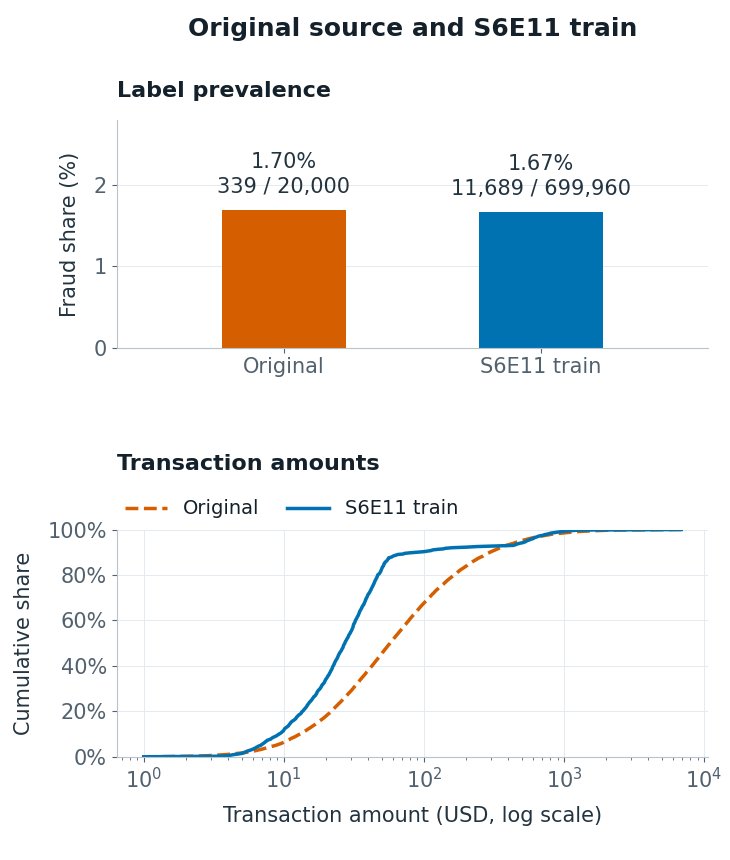

*This snapshot uses the files checked on 1 November 2026. The lower panel joins a 401-point quantile grid on a log amount axis. The calculations above reproduce the numbers from the attached CSVs.*

**Takeaway:** similar label prevalence does not imply matching feature distributions. The amount medians differ by more than a factor of two. We test source transfer in section 8 instead of assuming that more labelled rows must help.

<a id="s3"></a>

## 3. Check every supplied predictor

Check missingness, constants, duplicate feature rows, ID overlap and infinities before fitting. Duplicate checks below use full-row hashes as a screening tool. Zero matches do not prove that the datasets are independent.

In [ ]:
# Audit every supplied predictor, even when a model ablation excludes one.
audit_numeric = [c for c in schema_features if pd.api.types.is_numeric_dtype(train[c])
                 and not pd.api.types.is_bool_dtype(train[c])]
audit_categories = [c for c in schema_features if c not in audit_numeric]
quality = pd.DataFrame({'type': train[schema_features].dtypes.astype(str),
    'missing train': train[schema_features].isna().sum(),
    'missing test': test[schema_features].isna().sum(),
    'distinct train': train[schema_features].nunique(),
    'distinct test': test[schema_features].nunique()})
train_hash = pd.util.hash_pandas_object(train[schema_features], index=False)
test_hash = pd.util.hash_pandas_object(test[schema_features], index=False)
checks = {'duplicate_feature_rows_train': int(train_hash.duplicated().sum()),
    'duplicate_feature_rows_test': int(test_hash.duplicated().sum()),
    'test_rows_matching_train_features': int(test_hash.isin(train_hash).sum()),
    'shared_train_test_ids': len(set(train[id_col]) & set(test[id_col])),
    'constant_train_features': [c for c in schema_features if train[c].nunique(dropna=False) == 1],
    'numeric_infinities_train': int(np.isinf(train[audit_numeric].to_numpy(float)).sum()),
    'numeric_infinities_test': int(np.isinf(test[audit_numeric].to_numpy(float)).sum())}
assert not checks['numeric_infinities_train'] and not checks['numeric_infinities_test']
display(styled_table(quality))
display(styled_table(pd.DataFrame({'check': checks.keys(), 'result': [str(x) for x in checks.values()]}).set_index('check')))
display(callout(f"The training dataset contains {len(train):,} rows, of which "
                f"{int(train[target].sum()):,} are labelled as fraud ({train[target].mean():.3%}). "
                "No threshold is needed to calculate ROC AUC."))

**Takeaway:** the attached files have no missing predictors, constant predictors, numeric infinities or duplicate full feature rows. Train and test IDs are disjoint, and no test full-feature hash matches train. Feature availability needs a separate provenance audit.

<a id="s4"></a>

## 4. Where did the distributions move?

For a numeric predictor, its empirical cumulative distribution function (CDF) gives the fraction of rows at or below each value. The Kolmogorov-Smirnov (KS) distance is the largest vertical gap between two such curves. For text and boolean predictors, total variation is half the sum of the absolute differences in category shares. Both distances run from 0 to 1; compare features within each measure. These marginal checks leave interactions and the target relationship untested.

In [ ]:
# KS is a distance between empirical CDFs, including for tied/discrete values.
# We compare distances, not significance p-values from huge samples.
shift_rows = []
for column in audit_numeric:
    shift_rows.append({'feature': column,
        'source to train': ks_2samp(original[column], train[column]).statistic,
        'train to test': ks_2samp(train[column], test[column]).statistic,
        'source median': original[column].median(),
        'train median': train[column].median(), 'test median': test[column].median()})
numeric_shifts = pd.DataFrame(shift_rows).set_index('feature')
category_shifts = []
for column in audit_categories:
    frequencies = {name: f[column].astype('string').fillna('<missing>').value_counts(normalize=True)
                   for name, f in frames.items()}
    support = frequencies['Original'].index.union(frequencies['S6E11 train'].index).union(frequencies['S6E11 test'].index)
    values = {name: freq.reindex(support, fill_value=0) for name, freq in frequencies.items()}
    category_shifts.append({'feature': column,
        'source to train': float((values['Original'] - values['S6E11 train']).abs().sum()/2),
        'train to test': float((values['S6E11 train'] - values['S6E11 test']).abs().sum()/2)})
category_shifts = pd.DataFrame(category_shifts).set_index('feature')
display(styled_table(numeric_shifts.sort_values('source to train', ascending=False),
                    {c: '{:.4f}' for c in numeric_shifts.columns}))
display(styled_table(category_shifts.sort_values('source to train', ascending=False),
                    {c: '{:.4f}' for c in category_shifts.columns}))

In [ ]:
ordered = numeric_shifts.sort_values('source to train')
fig, ax = plt.subplots(figsize=(7.3, 6.4))
ax.barh([x.replace('_', ' ') for x in ordered.index], ordered['source to train'])
ax.set(xlabel='KS distance: original source to S6E11 train', title='The amount distribution moved most')
ax.grid(axis='x'); fig.tight_layout()
show_figure(fig, 'All 13 numeric predictors are shown. Amount has KS distance '
    f"{numeric_shifts.loc['amount_usd', 'source to train']:.3f}; the largest train-to-test distance is "
    f"{numeric_shifts['train to test'].max():.4f}. These are marginal comparisons, not a guarantee that CV will match the leaderboard.",
    'figures/numeric_shift.png')

**Takeaway:** amount is the clearest source shift (KS 0.3831), followed by account balance (0.1880) and distance from home (0.1593). The largest numeric train/test KS distance is only 0.0038. The competition data will be the main training distribution. Section 8 tests one way to use the original.

<a id="s5"></a>

## 5. Which subsets contain more fraud?

A high fraud rate in a rare subset can be based on few positives. Calculate both counts and 95% Wilson intervals. The saved `category_fraud_rates.csv` covers every level of all five text predictors and six boolean flags. The selected text table is controlled by `category_view`; the table and plot below cover all six flags.

These are exploratory, marginal associations. The intervals describe each subset and are not simultaneous intervals for a search over all features.

In [ ]:
def wilson(positives, count, z=1.959963984540054):
    p = positives / count
    centre = (p + z*z/(2*count)) / (1 + z*z/count)
    half = z*np.sqrt(p*(1-p)/count + z*z/(4*count*count)) / (1 + z*z/count)
    return centre-half, centre+half

strata_rows = []
for column in audit_categories:
    for level, subset in train.groupby(column, observed=True, dropna=False):
        count, positives = len(subset), int(subset[target].sum())
        low, high = wilson(positives, count)
        strata_rows.append(dict(feature=column, level=str(level), rows=count, fraud=positives,
            rate=positives/count, low=low, high=high))
strata = pd.DataFrame(strata_rows)
assert strata.groupby('feature').rows.sum().eq(len(train)).all()
assert strata.groupby('feature').fraud.sum().eq(int(train[target].sum())).all()
# All category/flag strata are saved; choose the displayed category in CFG.
strata.to_csv('category_fraud_rates.csv', index=False)
selected = CFG['category_view']
if selected not in audit_categories:
    raise ValueError('category_view must name a categorical or boolean predictor.')
selected_strata = strata[strata.feature.eq(selected)].copy()
display(styled_table(selected_strata.drop(columns='feature').set_index('level'),
    {'rows':'{:,.0f}', 'fraud':'{:,.0f}', 'rate':'{:.2%}', 'low':'{:.2%}', 'high':'{:.2%}'}))
flag_strata = strata[strata.feature.isin([c for c in audit_categories if pd.api.types.is_bool_dtype(train[c])])]
display(styled_table(flag_strata.set_index(['feature','level']),
    {'rows':'{:,.0f}', 'fraud':'{:,.0f}', 'rate':'{:.2%}', 'low':'{:.2%}', 'high':'{:.2%}'}))

In [ ]:
true_flags = flag_strata[flag_strata.level.eq('True')].sort_values('rate')
short_names = {'is_foreign_transaction':'Foreign transaction', 'is_new_merchant':'New merchant',
    'used_vpn':'Used VPN', 'ip_country_mismatch':'IP country mismatch',
    'billing_shipping_mismatch':'Billing / shipping mismatch',
    'is_ai_generated_scam_attempt':'AI scam flag'}
fig, ax = plt.subplots(figsize=(7.3, 4.7))
positions = np.arange(len(true_flags))
ax.errorbar(true_flags.rate*100, positions,
    xerr=np.vstack([(true_flags.rate-true_flags.low)*100, (true_flags.high-true_flags.rate)*100]),
    fmt='o', capsize=4, color='#0072B2')
ax.set_yticks(positions, [short_names[c] for c in true_flags.feature])
ax.axvline(train[target].mean()*100, color='#D55E00', ls='--', label='All training rows')
ax.set(xlabel='Fraud share when flag is True (%)', title='Several flags mark higher-risk subsets')
ax.grid(axis='x'); ax.legend(loc='lower right'); fig.tight_layout()
show_figure(fig, 'Points show marginal fraud rates; bars are 95% Wilson intervals for each subset. '
    'Counts and both flag states are in the table. AI=True contains 350 fraud labels among 2,299 rows (15.22%). '
    'Correlated features and selection can explain these associations; the chart does not establish causality.',
    'figures/flag_rates.png')

**Takeaway:** `ip_country_mismatch=True` contains 1,866 fraud labels among 11,312 rows (16.50%). The AI flag's true subset has 350 among 2,299 (15.22%, Wilson 13.81% to 16.75%). Neither rate tells us how much new information a flag adds after the other predictors. The ablation in section 8 addresses that narrower question.

In [ ]:
# ID order is not documented event time. Check it before inventing a temporal split.
id_auc = roc_auc_score(train[target], train[id_col])
id_bins = pd.qcut(train[id_col], 20, labels=False, duplicates='drop')
id_summary = train.groupby(id_bins, observed=True)[target].agg(['count', 'sum', 'mean'])
print(f'ID as a score: ROC AUC {id_auc:.5f}; 20 ordered-bin fraud shares '
      f"{id_summary['mean'].min():.3%} to {id_summary['mean'].max():.3%}.")

**Split check:** ID alone has AUC 0.49855, and fraud share across 20 ordered ID bins ranges from 1.563% to 1.814%. ID order is not documented transaction time. Without a documented time variable, shuffled stratified folds are the starting assumption.

<a id="s6"></a>

## 6. Freeze validation before testing ideas

Assign every row to one of five stratified folds, shuffled with seed 42. Every true-label recipe comparison in sections 7, 8, 12, 13, 15 and 18 uses these same held-out rows. Save a fingerprint of IDs, labels and assignments so a later run can verify the split.

There is no customer identifier for a group split and no documented event timestamp for a temporal split. The split treats rows as independent and identically distributed (IID). That is a competition assumption; it does not estimate performance on future bank transactions.

In [ ]:
if ready:
    encoder = None
    probability_order = None
    if task == "regression":
        y = train[target].to_numpy(dtype=float)
        if not np.isfinite(y).all() or (metric == "rmsle" and (y < 0).any()):
            raise ValueError("Invalid target for the configured regression metric.")
    else:
        encoder = LabelEncoder().fit(train[target])
        y = encoder.transform(train[target])
        if (task == "binary" and len(encoder.classes_) != 2) or (task == "multiclass" and len(encoder.classes_) < 3):
            raise ValueError("Task and observed class count disagree.")
        if task == "binary":
            if CFG["positive_class"] not in encoder.classes_:
                raise ValueError("Set positive_class explicitly, with the same type as the training labels.")
            y = (train[target].to_numpy() == CFG["positive_class"]).astype(int)
            probability_order = [next(c for c in encoder.classes_ if c != CFG["positive_class"]), CFG["positive_class"]]
        else:
            probability_order = encoder.classes_.tolist()
        if pd.Series(y).value_counts().min() < CFG["n_splits"]:
            raise ValueError("Too few examples of a class for n_splits.")
    splitter = (KFold(CFG["n_splits"], shuffle=True, random_state=CFG["seed"]) if task == "regression"
                else StratifiedKFold(CFG["n_splits"], shuffle=True, random_state=CFG["seed"]))
    folds = list(splitter.split(train, y))
    fold_ids = np.full(len(train), -1, dtype=np.int16)
    for fold, (_, validation) in enumerate(folds):
        fold_ids[validation] = fold
    data_fp = hashlib.sha256(pd.util.hash_pandas_object(train[[id_col, target]], index=False).values.tobytes()).hexdigest()
    split_fp = hashlib.sha256(data_fp.encode() + fold_ids.tobytes()).hexdigest()
    print("Split: IID", CFG["n_splits"], "folds, seed", CFG["seed"], "fingerprint", split_fp[:12])

    def score(actual, prediction):
        if metric == "auc": return float(roc_auc_score(actual, prediction[:, 1]))
        if metric == "logloss": return float(log_loss(actual, prediction, labels=np.arange(prediction.shape[1])))
        if metric == "accuracy": return float(accuracy_score(actual, prediction.argmax(axis=1)))
        if metric == "balanced_accuracy": return float(balanced_accuracy_score(actual, prediction.argmax(axis=1)))
        if metric == "map@3":
            top = np.argsort(-prediction, axis=1, kind="stable")[:, :3]
            return float(((top == actual[:, None]) / np.arange(1, top.shape[1] + 1)).sum(axis=1).mean())
        if metric == "mae": return float(mean_absolute_error(actual, prediction))
        if metric == "rmsle": return float(np.sqrt(mean_squared_error(np.log1p(actual), np.log1p(np.maximum(prediction, 0)))))
        return float(np.sqrt(mean_squared_error(actual, prediction)))

<a id="s7"></a>

## 7. Measure the baseline

Fit category encoders only on the training part of each fold. Unknown categories map to -1. LightGBM uses native categorical columns, 300 trees, 31 leaves and learning rate 0.05. There is no early stopping on outer validation labels.

Collect predictions only where a row was held out, then calculate pooled OOF AUC. Fold scores describe split variation; their standard deviation is not an improvement threshold.

In [ ]:
if ready:
    shape = () if task == "regression" else (len(np.unique(y)),)
    oof = np.full((len(train),) + shape, np.nan)
    test_prediction = np.zeros((len(test),) + shape)
    fold_scores = []
    cat_indices = list(range(len(numeric), len(features)))

    def matrix(frame, category_encoder=None, fit=False):
        numbers = frame[numeric].to_numpy(dtype=np.float32)
        if not categorical: return pd.DataFrame(numbers, columns=numeric, index=frame.index), None
        categories = frame[categorical].astype("string").fillna("<missing>").astype(str)
        if fit:
            category_encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
            codes = category_encoder.fit_transform(categories)
        else:
            codes = category_encoder.transform(categories)
        result = pd.DataFrame(np.column_stack([numbers, codes]).astype(np.float32),
                              columns=numeric + categorical, index=frame.index)
        return result, category_encoder

    for fold, (fitting, validation) in enumerate(folds):
        X_fit, category_encoder = matrix(train.iloc[fitting], fit=True)
        X_valid, _ = matrix(train.iloc[validation], category_encoder)
        X_test, _ = matrix(test, category_encoder)
        parameters = dict(n_estimators=CFG["n_estimators"], num_leaves=CFG["num_leaves"],
                          learning_rate=CFG["learning_rate"], random_state=CFG["seed"],
                          n_jobs=CFG["n_jobs"], verbosity=-1, deterministic=True, force_col_wise=True)
        if task == "regression":
            model = LGBMRegressor(**parameters, objective="regression_l1" if metric == "mae" else "regression")
            fit_y = np.log1p(y[fitting]) if metric == "rmsle" else y[fitting]
        else:
            model = LGBMClassifier(**parameters)
            fit_y = y[fitting]
        model.fit(X_fit, fit_y, categorical_feature=cat_indices)
        if task == "regression":
            valid_pred, test_pred = model.predict(X_valid), model.predict(X_test)
            if metric == "rmsle":
                valid_pred, test_pred = np.maximum(np.expm1(valid_pred), 0), np.maximum(np.expm1(test_pred), 0)
        else:
            valid_pred, test_pred = model.predict_proba(X_valid), model.predict_proba(X_test)
        oof[validation] = valid_pred
        test_prediction += test_pred / len(folds)
        fold_scores.append(score(y[validation], valid_pred))
        print(f"Fold {fold}: {metric} = {fold_scores[-1]:.7f}")
    if not np.isfinite(oof).all() or not np.isfinite(test_prediction).all():
        raise ValueError("Predictions are incomplete or nonfinite.")
    pooled_score = score(y, oof)
    print(f"Pooled OOF {metric}: {pooled_score:.7f}")
    print(f"Fold mean: {np.mean(fold_scores):.7f}; fold SD: {np.std(fold_scores, ddof=1):.7f}")
    print("Fold SD describes variation between folds. It is not a significance threshold for a model change.")

<a id="s8"></a>

## 8. Test three hypotheses

Write down the comparisons before interpreting their scores:

1. **Does the original add useful signal?** Add the probability from a source-only LightGBM teacher (100 trees, 15 leaves). Keep the same five folds and 300-tree student. Retain the feature only if the paired results support it.
2. **Does the AI flag contribute after the other inputs?** Remove only `is_ai_generated_scam_attempt`. Keep the same five folds and baseline settings. Interpret the difference as predictive contribution under this recipe.
3. **Do category frequencies work better than native categories?** Replace each of the five text columns with its frequency in the fitting rows. Map unseen values to 0. Keep boolean flags, all other inputs and the 300-tree budget unchanged. LightGBM treats these frequencies as numeric inputs. Validation and test rows never contribute to the frequency maps.

The teacher fits on the original source labels; competition labels train the student. Before fitting, exclude source rows whose full predictor hash matches either competition file. The competition was generated from this source, so the datasets may still be related even with no exact matches. Treat the result as source transfer within this competition, rather than validation on an independent dataset. The hash check says nothing about the generator's logic.

Frequency encoding uses no target labels, but it replaces category identity with a numeric frequency order. Equal frequencies merge categories. A difference from the baseline therefore measures this whole representation choice, rather than the isolated value of rarity. The [LightGBM categorical guide](https://lightgbm.readthedocs.io/en/stable/Advanced-Topics.html#categorical-feature-support) describes how native category splits differ from numeric thresholds.

These are exploratory comparisons on a shared development split. There is no nested model-selection estimate, and the five fold deltas are not five independent replications.

In [ ]:
"""Fixed-budget experiments on exactly the baseline's held-out folds."""
import time
research_started = time.perf_counter()
experiment_rows = [dict(recipe='Baseline', auc=pooled_score, delta=0.0)]
experiment_fold_deltas = {}
research_predictions = {}

def experiment_matrices(fitting_frame, other_frames, columns):
    cats = [c for c in columns if not pd.api.types.is_numeric_dtype(fitting_frame[c])]
    nums = [c for c in columns if c not in cats]
    enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
    if cats:
        enc.fit(fitting_frame[cats].astype('string').fillna('<missing>').astype(str))
    result = []
    for frame in [fitting_frame] + other_frames:
        values = frame[nums].to_numpy(dtype=np.float32)
        if cats:
            codes = enc.transform(frame[cats].astype('string').fillna('<missing>').astype(str))
            values = np.column_stack([values, codes]).astype(np.float32)
        result.append(pd.DataFrame(values, columns=nums+cats, index=frame.index))
    return result, list(range(len(nums), len(columns)))

def frequency_matrices(fitting_frame, other_frames, columns):
    # Only the fitting rows determine each map. No labels enter the encoding.
    cats = [c for c in columns if not pd.api.types.is_numeric_dtype(fitting_frame[c])]
    nums = [c for c in columns if c not in cats]
    maps = {c: fitting_frame[c].astype('string').fillna('<missing>')
              .value_counts(normalize=True) for c in cats}
    result = []
    for frame in [fitting_frame] + other_frames:
        values = frame[nums].to_numpy(dtype=np.float32)
        codes = np.column_stack([
            frame[c].astype('string').fillna('<missing>').map(maps[c])
                 .fillna(0.0).to_numpy(dtype=np.float32) for c in cats]) if cats else np.empty((len(frame), 0))
        result.append(pd.DataFrame(np.column_stack([values, codes]).astype(np.float32),
                                   columns=nums+cats, index=frame.index))
    # Frequencies are ordinary numeric inputs, with no native categorical columns.
    return result, []

def evaluate_variant(name, fitting_frame, test_frame, columns, representation='native'):
    variant_oof = np.full(len(train), np.nan)
    variant_test = np.zeros(len(test))
    deltas = []
    for fold, (fitting, validation) in enumerate(folds):
        transform = frequency_matrices if representation == 'frequency' else experiment_matrices
        (a, b, c), cat_idx = transform(
            fitting_frame.iloc[fitting], [fitting_frame.iloc[validation], test_frame], columns)
        fitted = LGBMClassifier(**parameters).fit(a, y[fitting], categorical_feature=cat_idx)
        variant_oof[validation] = fitted.predict_proba(b)[:, 1]
        variant_test += fitted.predict_proba(c)[:, 1] / len(folds)
        deltas.append(roc_auc_score(y[validation], variant_oof[validation])
                      - roc_auc_score(y[validation], oof[validation, 1]))
        print(f'{name}, fold {fold}: delta {deltas[-1]:+.6f}')
    assert np.isfinite(variant_oof).all() and np.isfinite(variant_test).all()
    auc = roc_auc_score(y, variant_oof)
    experiment_rows.append(dict(recipe=name, auc=auc, delta=auc-pooled_score))
    experiment_fold_deltas[name] = deltas
    research_predictions[name] = (variant_oof, variant_test)

if CFG['run_research']:
    # No competition labels enter this teacher. Exact feature-row matches are excluded.
    source_hash = pd.util.hash_pandas_object(original[schema_features], index=False)
    competition_hash = pd.util.hash_pandas_object(
        pd.concat([train[schema_features], test[schema_features]], ignore_index=True), index=False)
    source_overlap = source_hash.isin(competition_hash)
    source_fit = original.loc[~source_overlap]
    print('Source rows excluded by full-feature hash match:', int(source_overlap.sum()))
    (a, b, c), cat_idx = experiment_matrices(source_fit, [train, test], features)
    teacher_parameters = {**parameters, 'n_estimators': 100, 'num_leaves': 15}
    teacher = LGBMClassifier(**teacher_parameters).fit(
        a, source_fit[target].astype(int), categorical_feature=cat_idx)
    teacher_train, teacher_test = teacher.predict_proba(b)[:, 1], teacher.predict_proba(c)[:, 1]
    teacher_auc = roc_auc_score(y, teacher_train)
    print(f'Source-only teacher AUC: {teacher_auc:.7f}')
    evaluate_variant('Add source teacher',
        train.assign(source_teacher_probability=teacher_train),
        test.assign(source_teacher_probability=teacher_test),
        features + ['source_teacher_probability'])
    flag = 'is_ai_generated_scam_attempt'
    if flag in features:
        evaluate_variant('Drop AI flag', train, test, [c for c in features if c != flag])
    else:
        print('AI flag already excluded in CFG; its ablation is skipped.')
    print('Frequency-encoded columns:', categorical)
    evaluate_variant('Frequency encoding', train, test, features, representation='frequency')
else:
    print('Research disabled in CFG. The baseline still runs and exports predictions.')
experiment_results = pd.DataFrame(experiment_rows).set_index('recipe')
display(styled_table(experiment_results, {'auc':'{:.7f}', 'delta':'{:+.7f}'}))
if experiment_fold_deltas:
    display(styled_table(pd.DataFrame(experiment_fold_deltas).rename_axis('fold'),
                         {name:'{:+.6f}' for name in experiment_fold_deltas}))
print(f'Research cells: {time.perf_counter()-research_started:.1f} seconds on this machine.')

In [ ]:
"""Plot measured comparisons; this cell does not fit or select a model."""
if experiment_fold_deltas:
    names = list(experiment_fold_deltas)
    labels = {'Add source teacher': 'Source teacher', 'Drop AI flag': 'Drop AI flag',
              'Frequency encoding': 'Frequency encoding'}
    fig, ax = plt.subplots(figsize=(7.3, 4.4))
    for row, name in enumerate(names):
        values = np.asarray(experiment_fold_deltas[name])
        ax.scatter(values, row + np.linspace(-.11, .11, len(values)),
                   s=37, color='#0072B2', alpha=.8,
                   label='Individual folds' if row == 0 else None)
        ax.scatter(experiment_results.loc[name, 'delta'], row, marker='D',
                   s=65, color='#14212B', zorder=4,
                   label='Pooled OOF' if row == 0 else None)
    ax.axvline(0, color='#52616E', linewidth=1, linestyle='--')
    ax.set_yticks(range(len(names)), [labels.get(name, name) for name in names])
    ax.set_ylim(-.5, len(names)-.5)
    ax.invert_yaxis()
    ax.set(title='Change from the native-category baseline', xlabel='AUC difference')
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:+.3f}'))
    ax.grid(axis='x')
    ax.legend(loc='upper center', bbox_to_anchor=(.5, -.30), ncol=2, fontsize=14)
    fig.subplots_adjust(left=.32, right=.97, top=.82, bottom=.35)
    show_figure(fig,
        'Small circles show each fold difference; black diamonds show pooled OOF differences. '
        'Positive values favour the variant. Pooled AUC compares all held-out rows together, '
        'so its difference is not the mean of the five fold differences. '
        'The folds share training rows and are not independent replications.',
        'experiment_comparisons.png')

### Check the frequency pipeline with shuffled labels

Permute the labels once with seed 0, then rebuild the complete frequency pipeline. This control constructs new stratified folds from the shuffled labels. The three true-label comparisons above retain their frozen original folds. Frequencies still use fitting rows only, and the model still fits all 300 trees.

The diagnostic rule remains an absolute AUC distance below 0.003 from 0.5. A single pass cannot certify a clean pipeline; section 10 explains the scale of that cutoff. This control also cannot establish when the supplied predictors became available.

In [ ]:
"""Repeat the complete frequency pipeline after shuffling labels."""
frequency_control = None
if CFG['run_research']:
    shuffled_y = np.random.RandomState(0).permutation(y)
    # This control re-stratifies after shuffling, like the earlier LightGBM control.
    # The true-label folds used for the three model comparisons stay unchanged.
    control_folds = list(StratifiedKFold(CFG['n_splits'], shuffle=True,
                                       random_state=CFG['seed']).split(train, shuffled_y))
    control_oof = np.full(len(train), np.nan)
    control_fold_ids = np.full(len(train), -1, dtype=np.int16)
    control_scores = []
    for k, (fitting, validation) in enumerate(control_folds):
        (a, b), cats = frequency_matrices(train.iloc[fitting],
                                         [train.iloc[validation]], features)
        fitted = LGBMClassifier(**parameters).fit(a, shuffled_y[fitting],
                                                categorical_feature=cats)
        control_oof[validation] = fitted.predict_proba(b)[:, 1]
        control_fold_ids[validation] = k
        control_scores.append(roc_auc_score(shuffled_y[validation], control_oof[validation]))
        print(f'Frequency control, fold {k}: AUC {control_scores[-1]:.7f}')
    assert np.isfinite(control_oof).all() and (control_fold_ids >= 0).all()
    frequency_control = {'auc': float(roc_auc_score(shuffled_y, control_oof)),
                         'fold_auc': [float(v) for v in control_scores],
                         'permutation_seed': 0, 're_stratified_after_shuffle': True}
    print(f"The shuffled-label frequency pipeline has pooled AUC {frequency_control['auc']:.7f}.")
    print('This single control cannot certify absence of leakage or event-time feature availability.')
else:
    print('The frequency control is skipped because run_research is False.')

**Recorded result with the default settings:** baseline OOF AUC is **0.9450912**. The source teacher alone scores 0.9276153, but adding its probability reduces student AUC to **0.9414197** (delta **-0.0036715**). All five fold deltas are negative. This 100-tree teacher is rejected for this baseline; the result does not rule out other uses of the source.

Removing the AI flag gives **0.9437649** (delta **-0.0013263**), also lower on every fold. Keep the supplied flag in this competition baseline. This result says nothing by itself about causality or availability before a transaction is classified.

Frequency encoding scores **0.9452147** (delta **+0.0001236**), with 3 positive and 2 negative fold differences. The full shuffled-label frequency control scores **0.5058717**, outside the unchanged +/-0.003 diagnostic band. The variant stays on hold and receives no submission. That single result does not establish leakage. This comparison leaves the reference export unchanged. Section 11 records five additional full controls for this frequency recipe. Those runs have not calibrated the diagnostic or cleared the candidate. If the diagnostic is resolved in a separate study, a second predeclared true-label split can test whether the small gain persists. This exploratory comparison does not establish a reliable improvement.

If you change the configuration, use the computed tables above as your run's results. The paragraph records the default recipe, not every possible fork.

<a id="s9"></a>

## 9. Export the reference and preserve its history

Align the reference predictions to `sample_submission.csv` by ID. Preserve them as `reference_submission.csv`, with reference OOF/test arrays, folds, fingerprint, versions and metrics. Section 17 later replaces the primary `submission.csv` with the current recipe after its checks. The current report and final manifest identify the primary model; the reference arrays keep their historical meaning.

In [ ]:
if ready:
    submission = sample.copy()
    prediction_columns = [c for c in sample if c != id_col]
    order = pd.Index(test[id_col]).get_indexer(sample[id_col])
    aligned = test_prediction[order]
    if task == "regression":
        if len(prediction_columns) != 1: raise ValueError("Expected one regression prediction column.")
        submission[prediction_columns[0]] = aligned
    elif task == "binary" and metric in {"auc", "logloss"} and len(prediction_columns) == 1:
        submission[prediction_columns[0]] = aligned[:, 1]
    elif metric in {"accuracy", "balanced_accuracy", "map@3"} and len(prediction_columns) == 1:
        if task == "binary":
            negative = next(c for c in encoder.classes_ if c != CFG["positive_class"])
            labels = np.array([negative, CFG["positive_class"]])
        else: labels = encoder.classes_
        if metric == "map@3":
            indices = np.argsort(-aligned, axis=1, kind="stable")[:, :3]
            submission[prediction_columns[0]] = [" ".join(map(str, labels[row])) for row in indices]
        else: submission[prediction_columns[0]] = labels[aligned.argmax(axis=1)]
    else:
        mapping = CFG["class_columns"]
        if task != "multiclass" or not mapping or set(mapping) != set(prediction_columns):
            raise ValueError("Set class_columns as {submission_column: class_label} for class probabilities.")
        if set(mapping.values()) != set(encoder.classes_):
            raise ValueError("class_columns must cover each class exactly once.")
        for column in prediction_columns:
            submission[column] = aligned[:, int(encoder.transform([mapping[column]])[0])]
    if submission[prediction_columns].isna().any().any(): raise ValueError("Submission contains missing predictions.")
    output = Path(os.environ.get("S6E11_OUTPUT", "/kaggle/working" if Path("/kaggle/working").is_dir() else "artifacts/baseline"))
    output.mkdir(parents=True, exist_ok=True)
    submission.to_csv(output / "submission.csv", index=False)
    pd.DataFrame({id_col: train[id_col], "fold": fold_ids}).to_csv(output / "folds.csv", index=False)
    np.save(output / "oof.npy", oof)
    np.save(output / "test.npy", test_prediction)
    report = {"config": CFG, "data_fp": data_fp, "split_fp": split_fp, "pooled_oof": pooled_score,
              "fold_scores": fold_scores, "features": features, "checks": checks,
              "classes": None if encoder is None else encoder.classes_.tolist(),
              "probability_order": None if probability_order is None else [str(c) for c in probability_order],
              "libraries": {name: importlib.metadata.version(name)
                            for name in ("numpy", "pandas", "scikit-learn", "lightgbm", "matplotlib")}}
    (output / "metrics.json").write_text(json.dumps(report, indent=2, ensure_ascii=False))
    print("Saved artifacts:", output.resolve())
    display(submission.head())

In [ ]:
import shutil
shutil.copyfile(output/'submission.csv',output/'reference_submission.csv')
s10_reference_metrics=json.loads((output/'metrics.json').read_text())
s10_reference_metrics['artifact_scope']='Reference model only; submission_manifest.json identifies the final primary CSV and its model report.'
(output/'metrics.json').write_text(json.dumps(s10_reference_metrics,indent=2))
(output/'reference_metrics.json').write_text(json.dumps(s10_reference_metrics,indent=2))
print('Reference export preserved as reference_submission.csv. Section 17 writes the primary current-model file.')

In [ ]:
for name, (variant_oof, variant_test) in research_predictions.items():
    stem = name.lower().replace(' ', '_')
    np.save(output / (stem + '_oof.npy'), variant_oof)
    np.save(output / (stem + '_test.npy'), variant_test)
if frequency_control is not None:
    np.save(output / 'frequency_control_oof.npy', control_oof)
    np.save(output / 'frequency_control_labels.npy', shuffled_y)
    np.save(output / 'frequency_control_fold_ids.npy', control_fold_ids)
    (output / 'frequency_control.json').write_text(json.dumps(frequency_control, indent=2))
experiment_results.to_csv(output / 'experiment_results.csv')
pd.DataFrame(experiment_fold_deltas).to_csv(output / 'experiment_fold_deltas.csv', index_label='fold')
print(f'Elapsed time through the reference export: {time.perf_counter()-notebook_started:.1f} seconds.')

### Record the first submission and the later result

The first baseline has OOF AUC **0.9450912**. Kaggle accepted its first submission (reference 57859978) with a public AUC of **0.94587**. In the [public leaderboard](https://www.kaggle.com/competitions/playground-series-s6e11/leaderboard) snapshot taken on **1 November 2026 at 05:37 UTC**, it ranked **27th of 32 teams**. The separate organiser benchmark scored 0.94241 and is excluded from that team count; the leader scored 0.94945. Our score was 0.00346 above the benchmark and 0.00358 below the leader. This is an initial reference with room to improve.

The public board uses about 20% of test; the remaining 80% determines the private standings. This early position will change as teams submit. Research variants are evaluated on the frozen folds before any submission decision; their OOF scores are not leaderboard scores. This notebook records the snapshot without refreshing it.

A second accepted submission, reference **57876877**, uses the fixed H5 recipe from section 12 and scores **0.94709**. At **15:57 UTC on 1 November**, the archived public board placed it **94th of 166 ranked teams**, excluding the organiser benchmark. That is a different field from the early snapshot above. Section 14 records the separate review, its limitations and the exact submitted file. H6 was not included. The preserved reference export above provides the reproducible 300-tree predictions. Section 17 produces the primary current-model CSV. Section 16 records the third accepted submission, from H9.

Further work should preserve the frozen comparisons, investigate feature availability and test specific hypotheses before viewing new public scores. The frequency and historical XGBoost candidates remain held. The historical H5 operational decision neither clears those recipes nor resolves all possible leakage.

The source is synthetic, event-time availability is unresolved, and the public board covers only part of test. These limits remain even when a CV comparison looks consistent.

<a id="s10"></a>

## 10. Appendix: a shuffled score needs a scale

A recorded full-pipeline label-shuffled LightGBM control scored 0.5004586. A separate XGBoost candidate scored 0.5040066 under one shuffled run. Our diagnostic rule requires the shuffled AUC to be within 0.003 of 0.5, so we have kept that candidate on hold. This notebook records these earlier controls; it does not refit them. The LightGBM control re-stratified the folds after shuffling labels; the XGBoost control retained its original true-label folds. They are different protocols. Neither single score settles whether the pipeline leaks.

Even a fixed score varies when we randomly assign 11,689 positive labels among these rows. The calculation below gives an **untied-rank, fixed-score reference**. Shared training across OOF predictions makes it unsuitable as the null distribution of a refitted OOF pipeline.

In [ ]:
# A fixed score under random assignment of n1 positive labels has the Mann-Whitney
# null SD below (untied ranks). This is a reference, not a refitted-OOF null law.
n1 = int(y.sum()); n0 = len(y)-n1
fixed_score_null_sd = np.sqrt((n0+n1+1)/(12*n0*n1))
print(f'Fixed-score, untied-rank reference SD: {fixed_score_null_sd:.5f}')
print(f'A +/-0.003 band is only {0.003/fixed_score_null_sd:.2f} reference SDs wide.')

A +/-0.003 band is only about 1.11 reference standard deviations wide. The historical failure under that cutoff remains recorded. Section 11 records the completed full-pipeline label permutations with seeds 11, 23, 47, 101 and 211, plus deliberately contaminated controls for two separate recipes. Five permutations can reveal gross problems; they cannot estimate a 5% tail accurately.

The control is aimed at accidental pipeline leakage. It cannot establish that a supplied feature would exist at prediction time.

<a id="s11"></a>

## 11. Appendix: repeated shuffles and deliberate leaks

These are **recorded measurements from 1 November 2026**, independently recalculated from saved OOF probabilities, labels and fold assignments. The default notebook displays that snapshot. The optional code below can repeat the original protocols; editing the main baseline settings does not alter the recorded results.

**Frequency recipe (CPU).** Use the same fitting-row-only frequencies, numeric boolean flags and LightGBM300/31/0.05 settings as section 8. For each shuffled label vector, rebuild five stratified folds with split seed 42. The positive control adds a numeric predictor equal to every row's shuffled target, including held-out rows. That deliberately gives the model access to the answer.

**Historical XGBoost recipe (GPU).** Keep the five original true-label folds fixed under every permutation. Use 1,200 trees at learning rate 0.02, depth 6, minimum child weight 5, row sampling 0.8, column sampling 0.4, L1 0.1, L2 2 and max_bin 1,024. Numeric bins and feature-only frequencies are built from train plus test. That transductive preprocessing differs from the fitting-only frequency recipe above and is reproduced here to diagnose the historical pipeline. It is not adopted as a new training recommendation.

For historical XGBoost, training target encodings use inner five-fold cross-fitting with smoothing `auto` and 10; ordinary validation encodings use only outer-fitting labels. Its deliberate positive control instead fits the validation encoder on the union of outer fitting and validation rows, including validation labels, while retaining the cross-fitted training encodings. Both recipes use all fixed trees, without outer early stopping.

The two protocols used the same five predeclared permutation seeds, but different encodings, fold assignments and devices. Their ten null AUCs are not pooled. The earlier seed-0 scores remain separate from these five-repeat summaries. The XGBoost measurements used a Tesla T4, XGBoost 3.4.1 and scikit-learn 1.6.1; library versions and data hashes are saved in the recorded output. Hardware and software differences can prevent bitwise reproduction.

In [ ]:
recorded_controls = {'recorded_date': '1 November 2026',
 'scope': 'Two separately measured protocols; default display does not refit them.',
 'seeds': [11, 23, 47, 101, 211],
 'rule': 'abs(AUC-.5)<.003, unchanged',
 'pipelines': {'frequency': {'label': 'LightGBM with fitting-fold frequencies',
                             'fold_protocol': 'Re-stratify each permuted label vector, 5 '
                                              'folds, split seed42',
                             'device': 'CPU',
                             'model': {'n_estimators': 300,
                                       'num_leaves': 31,
                                       'learning_rate': 0.05,
                                       'random_state': 42,
                                       'n_jobs': 4,
                                       'verbosity': -1,
                                       'deterministic': True,
                                       'force_col_wise': True},
                             'libraries': {'lightgbm': '4.6.0',
                                           'numpy': '2.2.6',
                                           'pandas': '2.2.3',
                                           'scikit-learn': '1.6.1'},
                             'train_sha256': '87eaa10b8d17a7e4f657b8da1c66242431338bdd8b6ad45861521ac0c0e9fbd5',
                             'private_report_sha256': '0445fcd3b678a8357f94e9b05e7154d124d83241cfcbbb9d86335f13977098d9',
                             'arms': [{'seed': 11,
                                       'control': 'shuffle',
                                       'auc': 0.49925097751324077,
                                       'fold_auc': [0.501899894322263,
                                                    0.5044101411303079,
                                                    0.4964144784950273,
                                                    0.49194702229016374,
                                                    0.502051737360168]},
                                      {'seed': 23,
                                       'control': 'shuffle',
                                       'auc': 0.4999769529649386,
                                       'fold_auc': [0.49882136987150455,
                                                    0.502196044202171,
                                                    0.5033258263615114,
                                                    0.5022828200204867,
                                                    0.4941099299525646]},
                                      {'seed': 47,
                                       'control': 'shuffle',
                                       'auc': 0.4903986519044923,
                                       'fold_auc': [0.49056051600415523,
                                                    0.4856697057348496,
                                                    0.49274912261576775,
                                                    0.49152356313258255,
                                                    0.4914487453032307]},
                                      {'seed': 101,
                                       'control': 'shuffle',
                                       'auc': 0.5025771868597659,
                                       'fold_auc': [0.49919775812062767,
                                                    0.5058995997738618,
                                                    0.5061098146015494,
                                                    0.4927213552860613,
                                                    0.5096328957356702]},
                                      {'seed': 211,
                                       'control': 'shuffle',
                                       'auc': 0.5002233806571335,
                                       'fold_auc': [0.5000682282190876,
                                                    0.5066768628421493,
                                                    0.4878527557029431,
                                                    0.500113528653181,
                                                    0.5064020434915212]},
                                      {'seed': 11,
                                       'control': 'target copy leak',
                                       'auc': 1.0,
                                       'fold_auc': [1.0000000000000002,
                                                    1.0,
                                                    1.0,
                                                    0.9999999999999999,
                                                    1.0]}]},
               'xgboost': {'label': 'Historical XGBoost with cross-fitted target '
                                    'encoding',
                           'fold_protocol': 'Original true-label stratified folds held '
                                            'fixed under all permutations',
                           'device': 'cuda',
                           'model': {'n_estimators': 1200,
                                     'learning_rate': 0.02,
                                     'max_depth': 6,
                                     'min_child_weight': 5,
                                     'subsample': 0.8,
                                     'colsample_bytree': 0.4,
                                     'reg_lambda': 2.0,
                                     'reg_alpha': 0.1,
                                     'max_bin': 1024,
                                     'tree_method': 'hist',
                                     'device': 'cuda',
                                     'eval_metric': 'auc',
                                     'random_state': 42,
                                     'n_jobs': 4},
                           'libraries': {'xgboost': '3.4.1',
                                         'scikit-learn': '1.6.1',
                                         'numpy': '2.1.3',
                                         'pandas': '2.3.3',
                                         'scipy': '1.16.3'},
                           'train_sha256': '87eaa10b8d17a7e4f657b8da1c66242431338bdd8b6ad45861521ac0c0e9fbd5',
                           'private_report_sha256': 'b2f48efe7417be7cb0464214e91667cd3aae810988289a883712c90234c83c4f',
                           'arms': [{'seed': 11,
                                     'control': 'shuffle',
                                     'auc': 0.5037117612418591,
                                     'fold_auc': [0.5035042044399397,
                                                  0.493227635673,
                                                  0.5070754373127241,
                                                  0.5013884384815226,
                                                  0.5137934035202791]},
                                    {'seed': 23,
                                     'control': 'shuffle',
                                     'auc': 0.497128319394553,
                                     'fold_auc': [0.49459901243225535,
                                                  0.49919826637860687,
                                                  0.4959514887384038,
                                                  0.5013210764845434,
                                                  0.4942300724195321]},
                                    {'seed': 47,
                                     'control': 'shuffle',
                                     'auc': 0.5015362399233932,
                                     'fold_auc': [0.49948773636567756,
                                                  0.49596461972823336,
                                                  0.49795944227273914,
                                                  0.507017367748154,
                                                  0.5082105925711986]},
                                    {'seed': 101,
                                     'control': 'shuffle',
                                     'auc': 0.4980984725010778,
                                     'fold_auc': [0.4918950479329962,
                                                  0.49862399546903435,
                                                  0.501241118926723,
                                                  0.50017661782656,
                                                  0.49932298401953795]},
                                    {'seed': 211,
                                     'control': 'shuffle',
                                     'auc': 0.49955263372871894,
                                     'fold_auc': [0.5084871062239789,
                                                  0.4978568428342482,
                                                  0.49929143904082895,
                                                  0.4977667052346681,
                                                  0.4951262233909697]},
                                    {'seed': 11,
                                     'control': 'validation TE leak',
                                     'auc': 0.46792899579725156,
                                     'fold_auc': [0.46599409814133413,
                                                  0.4648408749621926,
                                                  0.4769919818727415,
                                                  0.461641852915222,
                                                  0.4684302383620612]}]}}}
reproduction_sources = {'run_frequency_controls.py': '"""Optional S6E11 frequency-control reproduction. No submission is uploaded.\n\nThis file contains the same fold-fitted frequency_matrices function as section 8.\nCall run_repeated_frequency(data_directory, output_directory) to run six arms.\nThe default notebook displays a recorded snapshot and leaves this rerun disabled.\n"""\nfrom pathlib import Path\nfrom datetime import datetime, timezone\nimport hashlib, json, time, importlib.metadata\nimport numpy as np\nimport pandas as pd\nfrom lightgbm import LGBMClassifier\nfrom sklearn.metrics import roc_auc_score\nfrom sklearn.model_selection import StratifiedKFold\n\n# The builder inserts the exact frequency_matrices definition at this marker.\ndef frequency_matrices(fitting_frame, other_frames, columns):\n    # Only the fitting rows determine each map. No labels enter the encoding.\n    cats = [c for c in columns if not pd.api.types.is_numeric_dtype(fitting_frame[c])]\n    nums = [c for c in columns if c not in cats]\n    maps = {c: fitting_frame[c].astype(\'string\').fillna(\'<missing>\')\n              .value_counts(normalize=True) for c in cats}\n    result = []\n    for frame in [fitting_frame] + other_frames:\n        values = frame[nums].to_numpy(dtype=np.float32)\n        codes = np.column_stack([\n            frame[c].astype(\'string\').fillna(\'<missing>\').map(maps[c])\n                 .fillna(0.0).to_numpy(dtype=np.float32) for c in cats]) if cats else np.empty((len(frame), 0))\n        result.append(pd.DataFrame(np.column_stack([values, codes]).astype(np.float32),\n                                   columns=nums+cats, index=frame.index))\n    # Frequencies are ordinary numeric inputs, with no native categorical columns.\n    return result, []\n\ndef run_repeated_frequency(data, output_directory):\n    output_directory = Path(output_directory)\n    output_directory.mkdir(parents=True, exist_ok=True)\n    parameters = dict(n_estimators=300, num_leaves=31, learning_rate=.05,\n                      random_state=42, n_jobs=4, verbosity=-1,\n                      deterministic=True, force_col_wise=True)\n    seeds = [11, 23, 47, 101, 211]\n    protocol = {\'created_utc\': datetime.now(timezone.utc).isoformat(), \'seeds\': seeds,\n        \'model\': parameters, \'folds\': \'Re-stratify each shuffled label vector, five folds, seed42\',\n        \'encoding\': \'Fitting-row-only text frequencies; unknown0; boolean inputs unchanged\',\n        \'positive_control\': \'Seed11: add a numeric input equal to the shuffled target, including held-out rows\',\n        \'gate\': \'abs(AUC-.5)<.003 unchanged; no admission or calibration from five repeats\',\n        \'train_file_sha256\': hashlib.sha256((Path(data)/\'train.csv\').read_bytes()).hexdigest(),\n        \'libraries\': {p: importlib.metadata.version(p) for p in [\'lightgbm\', \'numpy\', \'pandas\', \'scikit-learn\']}}\n    (output_directory/\'protocol.json\').write_text(json.dumps(protocol, indent=2))\n    train = pd.read_csv(Path(data)/\'train.csv\')\n    true_y = train.is_fraud.to_numpy()\n    assert len(train) == 699960 and true_y.sum() == 11689\n    features = [c for c in train if c not in {\'id\', \'is_fraud\'}]\n    report = {\'status\': \'running\', \'protocol\': protocol, \'arms\': []}\n    for seed, leak in [(s, False) for s in seeds] + [(11, True)]:\n        started = time.perf_counter()\n        name = (\'target_copy_\' if leak else \'null_\') + str(seed)\n        frame = train.copy() if leak else train\n        labels = np.random.RandomState(seed).permutation(true_y)\n        columns = features\n        if leak:\n            frame[\'deliberately_leaked_shuffled_target\'] = labels\n            columns = features + [\'deliberately_leaked_shuffled_target\']\n        oof = np.full(len(frame), np.nan)\n        fold_ids = np.full(len(frame), -1, np.int16)\n        fold_scores = []\n        for k, (fit, valid) in enumerate(StratifiedKFold(5, shuffle=True, random_state=42).split(frame, labels)):\n            (a, b), cats = frequency_matrices(frame.iloc[fit], [frame.iloc[valid]], columns)\n            model = LGBMClassifier(**parameters).fit(a, labels[fit], categorical_feature=cats)\n            oof[valid] = model.predict_proba(b)[:, 1]\n            fold_ids[valid] = k\n            fold_scores.append(float(roc_auc_score(labels[valid], oof[valid])))\n            print(f\'{name}, fold {k}: AUC {fold_scores[-1]:.7f}\', flush=True)\n        assert np.isfinite(oof).all() and (fold_ids >= 0).all()\n        np.savez_compressed(output_directory/(name+\'.npz\'), oof=oof, labels=labels, fold_ids=fold_ids)\n        auc = float(roc_auc_score(labels, oof))\n        report[\'arms\'].append({\'name\': name, \'seed\': seed, \'deliberate_leak\': leak, \'auc\': auc,\n            \'fold_auc\': fold_scores, \'old_gate_pass\': bool(abs(auc-.5) < .003),\n            \'seconds\': time.perf_counter()-started,\n            \'fold_ids_sha256\': hashlib.sha256(fold_ids.tobytes()).hexdigest(),\n            \'labels_sha256\': hashlib.sha256(labels.tobytes()).hexdigest()})\n        (output_directory/\'report.json\').write_text(json.dumps(report, indent=2))\n    report[\'status\'] = \'complete\'\n    (output_directory/\'report.json\').write_text(json.dumps(report, indent=2))\n    return report\n', 'run_h4_controls.py': '# Optional H4 reproduction: historical transductive pipeline diagnostics.\n# Global train+test feature-only statistics differ from the fold-only H3 recipe.\n"""Optional H4 controls for the historical transductive XGBoost pipeline.\nThis source defines run_controls and leaves expensive refits disabled by default.\nStandalone use after saving as run_h4_controls.py:\n    import run_h4_controls\n    run_h4_controls.run_controls(data=\'DATA_DIR\', out=\'OUTPUT_DIR\', device=\'cuda\')\nNotebook use: execute this source in an isolated namespace, then explicitly call\nthat namespace\'s run_controls function. Do not execute it in the baseline\'s\nnamespace: the historical adapter deliberately owns y, FOLDS and model settings.\nChanging RUN_REPEATED_NULL to True also runs all 30 costly fits in a dedicated\nnotebook cell. No command-line argument parser is provided by this adapter.\n"""\nimport os, glob, json, time, hashlib, platform, importlib.metadata, gc\nfrom pathlib import Path\nfrom datetime import datetime, timezone\nimport numpy as np, pandas as pd\nimport xgboost as xgb\nfrom sklearn.model_selection import StratifiedKFold, KFold\nfrom sklearn.preprocessing import TargetEncoder\nRUN_REPEATED_NULL = False\nTASK = \'binary\'\n_TE_TYPE = \'binary\'\nMETRICS = {\'auc\': (lambda y, p: __import__(\'sklearn.metrics\', fromlist=[\'roc_auc_score\']).roc_auc_score(y, p), True)}\n\ndef build_y(train, comp):\n    """Construct the target according to the binary task contract."""\n    s = train[comp[\'target\']]\n    if comp[\'task\'] == \'binary\':\n        pos = comp.get(\'positive\')\n        return (s == pos).astype(int).to_numpy() if pos is not None else s.astype(int).to_numpy()\n    if comp[\'task\'] == \'multiclass\':\n        idx = {c: i for i, c in enumerate(comp[\'classes\'])}\n        yy = s.map(lambda v: idx.get(v, idx.get(str(v))))\n        assert yy.notna().all(), \'Training data contain a class absent from the task contract.\'\n        return yy.astype(int).to_numpy()\n    return s.astype(float).to_numpy()\n\ndef make_folds(y, comp, n_splits=None, seed=None):\n    """Construct frozen folds: stratified for classification, KFold for regression."""\n    k = n_splits or comp.get(\'n_splits\', 5)\n    sd = comp.get(\'seed\', 42) if seed is None else seed\n    if comp[\'task\'] == \'regression\':\n        cv = KFold(k, shuffle=True, random_state=sd)\n    else:\n        cv = StratifiedKFold(k, shuffle=True, random_state=sd)\n    return list(cv.split(np.zeros(len(y)), y))\n\ndef fingerprint(folds, n):\n    ids = np.empty(n, np.int8)\n    for i, (_, va) in enumerate(folds):\n        ids[va] = i\n    return hashlib.md5(ids.tobytes()).hexdigest()[:12]\n\ndef _auc(y, p):\n    from sklearn.metrics import roc_auc_score\n    return roc_auc_score(y, p)\n\ndef score(y, p, comp):\n    return float(METRICS[comp[\'metric\']][0](y, p))\n\ndef pred_shape(comp, n):\n    return (n, len(comp[\'classes\'])) if comp[\'task\'] == \'multiclass\' else (n,)\nPROTOCOL = json.loads(\'{"experiment": "H4 repeated full-pipeline shuffled XGBoost controls", "seeds": [11, 23, 47, 101, 211], "positive_control": {"permutation_seed": 11, "mechanism": "historical encode_fold(leak_yB=y[outer_valid]): validation target encoder fit on A union B; training encodings remain inner-cross-fitted", "expected_detection": "absolute pooled AUC deviation >= .003; failure would limit sensitivity claims, not trigger another control tuned after viewing"}, "frozen_folds": "StratifiedKFold(5,shuffle=True,random_state=42) constructed once from original true labels before any permutation", "expected_factory_split_fp": "c7358c075703", "permutation": "np.random.RandomState(seed).permutation(n); permute both train[TARGET] and y identically, never re-stratify afterwards", "model_random_state": 42, "params": {"n_estimators": 1200, "learning_rate": 0.02, "max_depth": 6, "min_child_weight": 5, "subsample": 0.8, "colsample_bytree": 0.4, "reg_lambda": 2.0, "reg_alpha": 0.1, "max_bin": 1024, "tree_method": "hist", "device": "cuda", "eval_metric": "auc", "random_state": 42, "n_jobs": 4}, "feature_recipe": "verbatim historical build_matrix and encode_fold; global train+test feature-only frequency/ladder construction; target dropped before build; inner 5-fold TargetEncoder for fitting, outer fitting-label-only encoder for validation in honest arms", "early_stopping": false, "n_jobs": 4, "sequential_arms": true, "gate": "retain abs(AUC-.5)<.003 unchanged; no candidate admission or submission", "analysis": "Report each pooled/fold AUC, signed deviations, descriptive mean/SD/range, exceedance count and positive control; five repeats do not calibrate a 5% tail or certify no leakage. Fixed historical tree budget; no seed or cutoff selection after viewing.", "input_file_sha256": {"data/train.csv": "87eaa10b8d17a7e4f657b8da1c66242431338bdd8b6ad45861521ac0c0e9fbd5", "data/test.csv": "10f516959020357b565abaaa4fd25baae97fc2f536d0805695bb7cc15c1660f0"}, "source_sha256": {"core.py": "c914308f1832d87620d8c23b9c5bd3ea53a53b04938e9a4103ffecc4e8aae349", "header.py": "987fd2a4a0f0c502d3540ea1d784844115b057d33440370d28f01ae26779f8f4", "lib_gbdt.py": "30a020012df59ddecf5173e46c065117a6e922acb33d9a64e7d07a2e3cb5ba33", "base_xgb_1200.py": "d838e2c7da96e769823a5784c4ab45dab0228e335af4659c0351c018314fde3a", "base_xgb_1200_shuf.py": "85383cb2dd0c20b41646a16670ca71cf20893053d60f52922d3e7f06a9902543", "comp.json": "b514c06dd6923ab8dfa65dcf169cf25278a09c0f5171c19d76e81219349b94d4", "meta.json": "7ea40c3d50ce0d5accc5b9d577078b41b5e25279f6338c095ad83003f1236e23"}, "provenance": "Frozen historical factory implementation; diagnostic adapter for the historical transductive pipeline, not an endorsed model recipe. All measurements are recreated from attached competition CSVs; no workshop arrays are loaded."}\')\nCOMP = json.loads(\'{"competition": "playground-series-s6e11", "task": "binary", "target": "is_fraud", "id_col": "id", "positive": null, "metric": "auc", "n_splits": 5, "seed": 42, "split_fp": "c7358c075703", "n_train": 699960, "n_test": 299984}\')\nTARGET = COMP[\'target\']\n\ndef build_matrix(train, test, extra=None, drop=(), flags=None, steps=(0.1, 1, 10, 100, 1000, 10000), lo=8, hi=20000):\n    """Build feature-only numeric ladder keys and transductive train+test frequencies."""\n    comb = pd.concat([train.assign(_tr=1), test.assign(_tr=0)], ignore_index=True)\n    comb.drop(columns=[TARGET], inplace=True, errors=\'ignore\')\n    added = extra(comb) if extra else []\n    comb.drop(columns=list(drop), inplace=True, errors=\'ignore\')\n    idc = COMP.get(\'id_col\', \'id\')\n    CAT = comb.select_dtypes(include=[\'object\', \'string\', \'category\']).columns.tolist()\n    NUM = [c for c in comb.columns if c not in CAT + [idc, \'_tr\'] + added]\n    LADDER = []\n    for c in NUM:\n        v = comb[c]\n        span = float(v.max()) - float(v.min())\n        for st in steps:\n            k = int(np.floor(v / st).nunique())\n            if lo <= k <= hi and st <= max(span, 1):\n                comb[f\'L_{c}_{st}\'] = np.floor(v / st).astype(str)\n                LADDER.append(f\'L_{c}_{st}\')\n    KEYS = CAT + LADDER\n    for c in KEYS:\n        comb[f\'{c}_fe\'] = comb[c].map(comb[c].value_counts(normalize=True).to_dict()).astype(float)\n    if flags:\n        flags(comb)\n    tr = comb[comb._tr == 1].drop(columns=[\'_tr\']).reset_index(drop=True)\n    te = comb[comb._tr == 0].drop(columns=[\'_tr\']).reset_index(drop=True)\n    const = [c for c in tr.columns if tr[c].nunique() == 1]\n    tr.drop(columns=const, inplace=True)\n    te.drop(columns=const, inplace=True)\n    FEATS = [c for c in te.columns if c != idc]\n    TEC = [c for c in KEYS if c in FEATS]\n    print(f\'Features: {len(FEATS)}, target-encoding keys: {len(TEC)}, added: {added}\', flush=True)\n    return (tr, te, FEATS, TEC)\n\ndef _te_put(X, col, tag, E, i, K):\n    if K == 1:\n        X[f\'{col}_TE_{tag}\'] = E[:, i].astype(\'float32\')\n    else:\n        for j in range(K):\n            X[f\'{col}_TE_{tag}_{j}\'] = E[:, i * K + j].astype(\'float32\')\n\ndef encode_fold(A, B, C, TEC, yA, leak_yB=None):\n    """Cross-fit training encodings; transform held-out rows using fitting labels only, unless explicitly injecting the leaky control."""\n    K = len(COMP[\'classes\']) if TASK == \'multiclass\' else 1\n    for tag, sm in ((\'auto\', \'auto\'), (\'10\', 10.0)):\n        e = TargetEncoder(target_type=_TE_TYPE, shuffle=True, cv=5, smooth=sm, random_state=42)\n        ea = e.fit_transform(A[TEC], yA)\n        ec = e.transform(C[TEC])\n        if len(B) == 0:\n            eb = np.zeros((0, ea.shape[1]))\n        elif leak_yB is None:\n            eb = e.transform(B[TEC])\n        else:\n            eL = TargetEncoder(target_type=_TE_TYPE, smooth=sm).fit(pd.concat([A[TEC], B[TEC]]), np.r_[yA, leak_yB])\n            eb = eL.transform(B[TEC])\n        for i, col in enumerate(TEC):\n            for X_, E_ in ((A, ea), (B, eb), (C, ec)):\n                _te_put(X_, col, tag, E_, i, K)\n    for X_ in (A, B, C):\n        X_.drop(columns=TEC, inplace=True)\n\ndef _link(z):\n    """Convert a raw model margin to a prediction in the metric contract."""\n    if TASK == \'binary\':\n        return 1 / (1 + np.exp(-z))\n    if TASK == \'multiclass\':\n        z = z - z.max(1, keepdims=True)\n        e = np.exp(z)\n        return e / e.sum(1, keepdims=True)\n    return z\n\ndef _xgb_model(P):\n    return xgb.XGBRegressor(**P) if TASK == \'regression\' else xgb.XGBClassifier(**P)\n\ndef _xgb_raw(m, X, margin):\n    kw = dict(base_margin=margin) if margin is not None else {}\n    z = m.predict(X, output_margin=True, **kw)\n    if TASK == \'multiclass\':\n        z = np.asarray(z).reshape(len(X), -1)\n    return z\n\ndef run_xgb(tr, te, FEATS, TEC, margin=None, P=None, note=\'\', fixed_iter=None, leak=False):\n    if globals().get(\'REFIT_MODE\'):\n        return _refit(tr, te, FEATS, TEC, \'xgb\', margin, P)\n    P = dict(XGB_P, **P or {})\n    if fixed_iter:\n        P.update(n_estimators=int(fixed_iter))\n        P.pop(\'early_stopping_rounds\', None)\n    oof = np.zeros(pred_shape(COMP, len(tr)))\n    tp = np.zeros(pred_shape(COMP, len(te)))\n    iters = []\n    for k, (i1, i2) in enumerate(FOLDS, 1):\n        A, B, C = (tr.iloc[i1][FEATS].copy(), tr.iloc[i2][FEATS].copy(), te[FEATS].copy())\n        encode_fold(A, B, C, TEC, y[i1], leak_yB=y[i2] if leak else None)\n        m = _xgb_model(P)\n        ma, mb, mc = margin(i1, i2) if margin is not None else (None, None, None)\n        kw = dict(base_margin=ma) if margin is not None else {}\n        if not fixed_iter:\n            kw.update(eval_set=[(B, y[i2])])\n            if margin is not None:\n                kw.update(base_margin_eval_set=[mb])\n        m.fit(A, y[i1], verbose=False, **kw)\n        oof[i2] = _link(_xgb_raw(m, B, mb))\n        tp += _link(_xgb_raw(m, C, mc)) / len(FOLDS)\n        it = int(fixed_iter) if fixed_iter else int(m.best_iteration)\n        iters.append(it)\n        print(f\'  fold {k}: #{it} {COMP[\'metric\']} {score(y[i2], oof[i2], COMP):.5f} {time.time() - T0:.0f}s\', flush=True)\n    save(oof, tp, note=note, params=P, iters=iters, n_features=A.shape[1], fixed_iter=fixed_iter, leak=leak)\n\ndef digest(a):\n    return hashlib.sha256(np.ascontiguousarray(a).tobytes()).hexdigest()\n\ndef file_sha(path):\n    h = hashlib.sha256()\n    with open(path, \'rb\') as f:\n        for block in iter(lambda: f.read(1 << 20), b\'\'):\n            h.update(block)\n    return h.hexdigest()\n\ndef write_json(path, value):\n    path = Path(path)\n    tmp = path.with_suffix(\'.tmp\')\n    tmp.write_text(json.dumps(value, indent=2, default=str) + \'\\n\')\n    tmp.replace(path)\n\ndef run_controls(data=None, out=\'repeated_null_outputs\', device=None, benchmark=False):\n    global train, test, y, FOLDS, SPLIT_FP, T0, XGB_P\n    import shutil\n    data = Path(data) if data else next((Path(p) for p in [\'/kaggle/input/competitions/playground-series-s6e11\', \'/kaggle/input/playground-series-s6e11\', \'data\'] if (Path(p) / \'train.csv\').is_file()), None)\n    if data is None:\n        raise FileNotFoundError(\'Attach S6E11 train.csv and test.csv.\')\n    out = Path(out)\n    out.mkdir(parents=True, exist_ok=True)\n    device = device or (\'cuda\' if shutil.which(\'nvidia-smi\') else \'cpu\')\n    train = pd.read_csv(data / \'train.csv\')\n    test = pd.read_csv(data / \'test.csv\')\n    true_y = build_y(train, COMP)\n    all_folds = make_folds(true_y, COMP)\n    SPLIT_FP = fingerprint(all_folds, len(train))\n    assert SPLIT_FP == \'c7358c075703\'\n    assert len(train) == 699960 and len(test) == 299984 and (true_y.sum() == 11689)\n    fold_ids = np.empty(len(train), np.int8)\n    for k, (_, v) in enumerate(all_folds):\n        fold_ids[v] = k\n    np.save(out / \'frozen_fold_ids.npy\', fold_ids)\n    np.save(out / \'true_y.npy\', true_y)\n    environment = {\'utc\': datetime.now(timezone.utc).isoformat(), \'platform\': platform.platform(), \'packages\': {p: importlib.metadata.version(p) for p in [\'xgboost\', \'scikit-learn\', \'numpy\', \'pandas\', \'scipy\']}, \'device\': device, \'n_jobs\': 4, \'OMP_NUM_THREADS\': os.environ.get(\'OMP_NUM_THREADS\'), \'fold_md5_12\': SPLIT_FP, \'fold_ids_sha256\': digest(fold_ids), \'true_y_sha256\': digest(true_y), \'train_id_sha256\': digest(train[COMP[\'id_col\']].to_numpy()), \'input_file_sha256\': {p.name: file_sha(p) for p in [data / \'train.csv\', data / \'test.csv\']}, \'run_source_sha256\': file_sha(__file__) if \'__file__\' in globals() else None, \'historical_device\': \'cuda\', \'bitwise_reproduction_claim\': False, \'benchmark_only\': benchmark}\n    if device == \'cuda\':\n        import subprocess\n        environment[\'nvidia_smi\'] = subprocess.check_output([\'nvidia-smi\'], text=True)\n    write_json(out / \'environment.json\', environment)\n    write_json(out / \'protocol.json\', PROTOCOL)\n    for p in [\'train.csv\', \'test.csv\']:\n        assert environment[\'input_file_sha256\'][p] == PROTOCOL[\'input_file_sha256\'][\'data/\' + p], \'Raw input differs\'\n    tr, te, feats, tec = build_matrix(train, test)\n    assert len(feats) == 85 and len(tec) == 33\n    write_json(out / \'feature_manifest.json\', {\'before_TE\': feats, \'TE_keys\': tec, \'post_TE_count\': 118, \'dtypes\': {c: str(tr[c].dtype) for c in tr}})\n    XGB_P = dict(PROTOCOL[\'params\'])\n    XGB_P[\'device\'] = device\n    assert \'early_stopping_rounds\' not in XGB_P\n    summary = {\'status\': \'running\', \'environment\': environment, \'arms\': []}\n    arms = [(s, False) for s in PROTOCOL[\'seeds\']] + [(11, True)]\n    if benchmark:\n        arms = arms[:1]\n    for seed, leak in arms:\n        name = (\'positive_control_seed_\' if leak else \'null_seed_\') + str(seed)\n        arm = out / name\n        arm.mkdir(exist_ok=True)\n        perm = np.random.RandomState(seed).permutation(len(train))\n        y = true_y[perm].copy()\n        train[TARGET] = train[TARGET].to_numpy()\n        train[TARGET] = true_y[perm]\n        assert np.array_equal(build_y(train, COMP), y) and y.sum() == true_y.sum()\n        FOLDS = all_folds[:1] if benchmark else all_folds\n        T0 = time.time()\n\n        def save_arm(oof, tp, **meta):\n            oof = np.asarray(oof, np.float64)\n            tp = np.asarray(tp, np.float64)\n            from sklearn.metrics import roc_auc_score\n            assert oof.shape == (len(train),) and tp.shape == (len(test),)\n            assert np.isfinite(oof).all() and np.isfinite(tp).all()\n            fs = [float(roc_auc_score(y[v], oof[v])) for _, v in FOLDS]\n            a = float(roc_auc_score(y, oof)) if not benchmark else None\n            np.save(arm / \'oof.npy\', oof)\n            np.save(arm / \'test.npy\', tp)\n            np.save(arm / \'shuffled_y.npy\', y)\n            meta.update(name=name, seed=seed, status=\'benchmark_one_fold\' if benchmark else \'complete\', pooled_auc=a, fold_auc=fs, fold_positive_counts=[int(y[v].sum()) for _, v in FOLDS], original_fold_fp=SPLIT_FP, fold_ids_sha256=digest(fold_ids), shuffled_y_sha256=digest(y), permutation_sha256=digest(perm), oof_sha256=file_sha(arm / \'oof.npy\'), test_sha256=file_sha(arm / \'test.npy\'), elapsed_seconds=time.time() - T0, model_seed=42, device=device, abs_deviation=None if a is None else abs(a - 0.5), old_gate_pass=None if a is None else bool(abs(a - 0.5) < 0.003), leakage=\'validation TE fit on A union B\' if leak else \'outer-fitting-label-only TE\')\n            write_json(arm / \'meta.json\', meta)\n            summary[\'arms\'].append(meta)\n            write_json(out / \'report.json\', summary)\n        globals()[\'save\'] = save_arm\n        print(\'START\', name, \'device\', device, \'positive counts\', [int(y[v].sum()) for _, v in FOLDS], flush=True)\n        run_xgb(tr, te, feats, tec, fixed_iter=1200, P={\'n_jobs\': 4, \'device\': device}, leak=leak, note=\'H4 predeclared \' + name)\n        gc.collect()\n    summary[\'status\'] = \'benchmark_complete\' if benchmark else \'complete\'\n    summary[\'interpretation\'] = \'Five full refits describe repeated null behavior; no 5% tail calibration, no automatic gate/candidate change. Positive control assesses one intentional validation-TE leak only.\'\n    if not benchmark:\n        vals = np.array([a[\'pooled_auc\'] for a in summary[\'arms\'] if not a[\'leak\']])\n        summary[\'descriptive_null_summary\'] = {\'mean\': float(vals.mean()), \'sample_sd\': float(vals.std(ddof=1)), \'min\': float(vals.min()), \'max\': float(vals.max()), \'old_gate_exceedances\': int((np.abs(vals - 0.5) >= 0.003).sum()), \'n\': len(vals)}\n    write_json(out / \'report.json\', summary)\n    print(json.dumps(summary, indent=2), flush=True)\n    return summary\nif __name__ == \'__main__\' and RUN_REPEATED_NULL:\n    repeated_null_results = run_controls()\n'}
for filename, source in reproduction_sources.items():
    (output/filename).write_text(source)

In [ ]:
"""Summarise complete recorded refits; these tables do not refit the pipelines."""
recorded_null_tables = {}
for key, pipeline in recorded_controls['pipelines'].items():
    print(pipeline['label'])
    frame = pd.DataFrame(pipeline['arms'])
    frame['outside band'] = (frame['auc']-.5).abs() >= .003
    table = frame[['seed', 'control', 'auc', 'outside band']].rename(columns={'auc':'OOF AUC'})
    table = table.set_index(['seed', 'control'])
    assert table.index.is_unique
    display(styled_table(table, {'OOF AUC':'{:.7f}'}))
    honest = frame.loc[frame.control.eq('shuffle')].copy()
    assert len(honest) == 5 and honest.seed.tolist() == [11, 23, 47, 101, 211]
    recorded_null_tables[key] = honest
    print(f"The five predeclared null refits range from {honest.auc.min():.7f} "
          f"to {honest.auc.max():.7f}; {int(honest['outside band'].sum())} of 5 "
          'are outside the unchanged diagnostic band.')
    print('This count describes these five refits; it does not estimate a false-positive rate.')
(output/'recorded_repeated_controls.json').write_text(json.dumps(recorded_controls, indent=2))
print('The recorded results and optional reproduction scripts are saved with the notebook outputs.')

In [ ]:
"""Display the two diagnostic protocols separately on a common AUC scale."""
all_null = np.concatenate([frame.auc.to_numpy() for frame in recorded_null_tables.values()])
low, high = min(float(all_null.min()), .497), max(float(all_null.max()), .503)
padding = max((high-low)*.12, .001)
fig, axes = plt.subplots(2, 1, figsize=(7.3, 7.6), sharex=True)
titles = {'frequency':'Frequency encoding: folds rebuilt after shuffling',
          'xgboost':'Historical XGBoost: original folds held fixed'}
for ax, (key, frame) in zip(axes, recorded_null_tables.items()):
    ax.axvspan(.497, .503, color='#E8EDF1', zorder=0)
    ax.axvline(.5, color='#52616E', linestyle='--', linewidth=1)
    ax.scatter(frame.auc, np.arange(len(frame)), color='#0072B2', s=55, zorder=3)
    ax.set_yticks(np.arange(len(frame)), [f'Seed {seed}' for seed in frame.seed])
    ax.invert_yaxis()
    ax.set_ylim(4.6, -.6)
    ax.set_xlim(low-padding, high+padding)
    ax.set_title(titles[key], loc='left', fontsize=14, pad=16)
    ax.grid(axis='x')
    ax.tick_params(axis='x', labelbottom=True)
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.3f}'))
axes[-1].set_xlabel('Shuffled-label OOF AUC')
fig.subplots_adjust(left=.18, right=.97, top=.91, bottom=.12, hspace=.65)
show_figure(fig,
    'Each point is the pooled AUC from a complete five-fold refit on one label permutation. '
    'The shaded 0.497 to 0.503 band is the existing diagnostic rule, not a confidence interval. '
    'The deliberately contaminated controls are reported in the tables. '
    'The protocols differ in preprocessing, fold assignments and device.',
    'repeated_null_controls.png')

The frequency recipe's five null AUCs range from **0.4903987 to 0.5025772**; 1 is outside the old band. The historical XGBoost range is **0.4971283 to 0.5037118**, also with 1 outside. These counts describe the prescribed runs. Five repeats cannot calibrate a 5% tail or estimate a false-positive rate reliably, and they do not establish a persistent bias.

The copied-target positive control scored **1.0000000**. The contaminated validation-encoding control scored **0.4679290**, below chance, and also triggered the absolute-deviation rule. A positive control deliberately includes a known violation; its name does not mean the AUC must increase. The experiment does not isolate why its ranking fell. These controls check two specified failures and leave sensitivity to other leaks unmeasured.

The preserved reference and the frequency and historical XGBoost holds remain unchanged. A pass would not establish event-time feature availability, and a failure alone would not prove leakage. The repeated results do not establish that the small true-label frequency gain is reliable.

### Reproduce a recorded diagnostic

The notebook outputs contain `recorded_repeated_controls.json`, `run_frequency_controls.py` and `run_h4_controls.py`. Both scripts are self-contained and perform no fits when imported. The frequency function contains the same encoder shown in section 8; the historical script preserves its full feature-building and cross-fitting logic.

Set `run_repeated_frequency=True` to repeat its six arms on CPU. To reproduce the historical XGBoost device, enable a Kaggle GPU session and set `run_repeated_h4=True`. Each switch runs five shuffled-label arms and one specified positive control, with five fits per arm. The modules write fresh predictions and reports into separate output folders, preserving the baseline arrays. The tables above remain labelled as the recorded snapshot; a rerun writes its own report.

In [ ]:
"""Optional reproduction runs in separate modules with their own output folders."""
import importlib.util

def load_reproducer(filename):
    path = output/filename
    spec = importlib.util.spec_from_file_location(path.stem, path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module

if CFG.get('run_repeated_frequency', False):
    frequency_module = load_reproducer('run_frequency_controls.py')
    recomputed_frequency = frequency_module.run_repeated_frequency(DATA, output/'recomputed_frequency')
else:
    print('The frequency table is a recorded snapshot. Its six-arm reproduction is disabled.')
if CFG.get('run_repeated_h4', False):
    h4_module = load_reproducer('run_h4_controls.py')
    recomputed_h4 = h4_module.run_controls(data=DATA, out=output/'recomputed_h4', device='cuda')
else:
    print('The historical XGBoost table is a recorded GPU snapshot. Its six-arm reproduction is disabled.')
print('Optional refits use the original recorded protocols, independently of edited baseline settings.')

In [ ]:
import base64 as s15_h5_b64, zlib as s15_h5_zlib
h5_payload=json.loads(s15_h5_zlib.decompress(s15_h5_b64.b64decode('...')))
recorded_h5_study=h5_payload["record"]
h5_reproduction_sources=h5_payload["sources"]
for filename, source in h5_reproduction_sources.items():
    (output/filename).write_text(source)

In [ ]:
def h5_gate_figure(study):
    fig,ax=plt.subplots(figsize=(7.3,4.0))
    fig.subplots_adjust(left=.36,right=.96,top=.82,bottom=.22)
    values=[.5,study['raw_flag']['auc_no_fit'],study['h5']['control_auc']]
    labels=['Constant score','Raw new-merchant flag','H5 shuffled-label model']
    ax.axvspan(.497,.503,color='#E8EDF1',zorder=0)
    ax.axvline(.5,color='#52616E',linestyle='--',linewidth=1)
    for row,(value,colour) in enumerate(zip(values,['#52616E','#0072B2','#D55E00'])):
        ax.scatter(value,row,s=60,color=colour,zorder=3)
        ax.annotate(f'{value:.7f}',(value,row),xytext=(9,0),textcoords='offset points',va='center',fontsize=14)
    ax.set_yticks(range(3),labels);ax.set_ylim(2.6,-.6);ax.set_xlim(.496,.510)
    ax.set(title='One shuffled label vector, three scores',xlabel='AUC on the seed-0 shuffled labels')
    ax.xaxis.set_major_locator(plt.MaxNLocator(4));ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_:f'{x:.3f}'))
    ax.grid(axis='x')
    return fig


fig=h5_gate_figure(recorded_h5_study)
fig.savefig('h5_gate_snapshot.png',dpi=100,facecolor='white');plt.close(fig)

<a id="s12"></a>

## 12. Why the 600-tree recipe failed its first control

The 600-tree native-category recipe, called H5 here, improved OOF AUC to **0.9464870**, a gain of **0.0013958** over the reference. All five paired fold differences were positive. The original selection rule also required an absolute shuffled-label AUC distance below 0.003 from 0.5. H5 scored **0.5064052**, so it failed that rule and was held. That original **FAIL/HOLD remains recorded**.

The rule came from our working playbook. It was an operational filter, not a Kaggle requirement or a calibrated significance test. A failure identified a score that needed investigation; it did not establish leakage.

H5 uses 600 trees, 15 leaves, learning rate 0.03, minimum child count 40, L2 penalty 12, row sampling 0.85 on every tree and column sampling 0.85. The model seed is 42, with four threads and deterministic column-wise construction. It retains the 24 raw predictors, fitting-only category encoders and five original true-label folds. No outer-validation early stopping is used. This changes a complete training recipe, so its gain cannot be attributed to one parameter.

Will Guesdon's [refined LightGBM notebook](https://www.kaggle.com/code/wguesdon/s6e11-refined-lightgbm) informed this 15-leaf regularised recipe. That source uses 1,200 trees; our 600-tree experiment is an adaptation, not an exact reproduction. These are exploratory comparisons on reused development data, and the five folds are dependent.

In [ ]:
study = recorded_h5_study
recipe_table = pd.DataFrame({
    'Reference':[study['h5']['baseline_auc'],0.0,study['d1']['seed0_reproductions']['baseline']['new_auc']],
    'H5':[study['h5']['auc'],study['h5']['delta'],study['h5']['control_auc']]},
    index=['OOF AUC','Delta vs reference','First shuffled AUC'])
display(styled_table(recipe_table,{'Reference':'{:.7f}','H5':'{:.7f}'}))
distance = abs(study['h5']['control_auc']-.5)
display(callout(f"The original H5 control is {distance:.7f} from 0.5, beyond the old 0.003 filter. "
                "This reproduces its recorded failure. The filter was an operational rule without a calibrated significance level."))

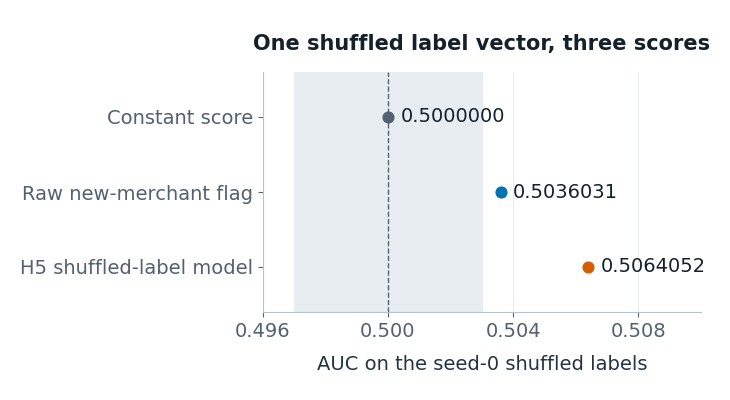

*This historical snapshot uses the same seed-0 shuffled labels. The grey band is the old operational filter, not a confidence interval. The raw flag was noticed post hoc; the three points do not decompose the fitted model's score.*

The following function shows the complete H5/H6 fitting path. Defining it performs no fits. The optional switch at the end loads the same code from an isolated reproduction module, using the original fixed protocol and a checked default reference.

In [ ]:
"""Optional H5/H6 reproduction. Importing this module performs no fits or submissions.

Call run_candidates(data, baseline_output, output_directory). The baseline folder
must contain oof.npy, folds.csv and metrics.json from the default five-fold run:
300 trees, 31 leaves, learning_rate=.05 and all 24 raw predictors. Presentation and
optional flags may vary.
"""
from pathlib import Path
from datetime import datetime,timezone
import hashlib,json,time,importlib.metadata
import numpy as np,pandas as pd
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from lightgbm import LGBMClassifier

def experiment_matrices(fitting_frame, other_frames, columns):
    cats = [c for c in columns if not pd.api.types.is_numeric_dtype(fitting_frame[c])]
    nums = [c for c in columns if c not in cats]
    enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
    if cats:
        enc.fit(fitting_frame[cats].astype('string').fillna('<missing>').astype(str))
    result = []
    for frame in [fitting_frame] + other_frames:
        values = frame[nums].to_numpy(dtype=np.float32)
        if cats:
            codes = enc.transform(frame[cats].astype('string').fillna('<missing>').astype(str))
            values = np.column_stack([values, codes]).astype(np.float32)
        result.append(pd.DataFrame(values, columns=nums+cats, index=frame.index))
    return result, list(range(len(nums), len(columns)))

PARAMS=dict(n_estimators=600,num_leaves=15,learning_rate=.03,random_state=42,n_jobs=4,
    min_child_samples=40,reg_lambda=12,subsample=.85,subsample_freq=1,colsample_bytree=.85,
    verbosity=-1,deterministic=True,force_col_wise=True)
FLAGS=['is_foreign_transaction','is_new_merchant','used_vpn','ip_country_mismatch',
       'billing_shipping_mismatch','is_ai_generated_scam_attempt']

def run_candidates(data,baseline_output,output_directory):
    data=Path(data);baseline_output=Path(baseline_output);output_directory=Path(output_directory)
    output_directory.mkdir(parents=True,exist_ok=True)
    train=pd.read_csv(data/'train.csv');test=pd.read_csv(data/'test.csv');sample=pd.read_csv(data/'sample_submission.csv')
    y=train.is_fraud.to_numpy();features=[c for c in test if c!='id']
    assert len(train)==699960 and len(test)==299984 and y.sum()==11689 and len(features)==24
    # The reference must be the default native300/31 baseline, not an edited fork.
    baseline_metrics=json.loads((baseline_output/'metrics.json').read_text())
    config=baseline_metrics['config']
    required_config={'competition':'playground-series-s6e11','task':'binary','metric':'auc',
        'target':'is_fraud','id_col':'id','positive_class':1,'split':'iid',
        'n_estimators':300,'num_leaves':31,'learning_rate':.05,'seed':42,'n_splits':5}
    for key,value in required_config.items():
        if config.get(key)!=value:
            raise ValueError(f'Default baseline required: {key} must be {value!r}, got {config.get(key)!r}.')
    if config.get('drop_features',[])!=[] or baseline_metrics.get('features')!=features:
        raise ValueError('Default baseline must use exactly the same ordered 24 raw predictors, with no dropped features.')
    reference=np.load(baseline_output/'oof.npy')
    if reference.ndim==2:
        if reference.shape!=(len(train),2):
            raise ValueError('Default binary baseline must have two probability columns.')
        reference=reference[:,1]
    assert reference.shape==y.shape
    if not np.isfinite(reference).all() or not ((reference>=0)&(reference<=1)).all():
        raise ValueError('Baseline OOF must contain finite probabilities in [0,1].')
    reference_auc=float(roc_auc_score(y,reference))
    if abs(reference_auc-float(baseline_metrics['pooled_oof']))>1e-12:
        raise ValueError('Baseline OOF and metrics do not describe these training labels.')
    folds=list(StratifiedKFold(5,shuffle=True,random_state=42).split(train,y))
    ids=np.full(len(train),-1,np.int16)
    for k,(_,v) in enumerate(folds):ids[v]=k
    saved=pd.read_csv(baseline_output/'folds.csv')
    np.testing.assert_array_equal(saved.id,train.id);np.testing.assert_array_equal(saved.fold,ids)
    protocol={'created_utc':datetime.now(timezone.utc).isoformat(),'params':PARAMS,'flags':FLAGS,
        'scope':'Fixed original H5/H6 protocols. Paired OOF gains are exploratory; no automatic admission or submission.',
        'input_sha256':{p:hashlib.sha256((data/p).read_bytes()).hexdigest() for p in ['train.csv','test.csv']},
        'libraries':{p:importlib.metadata.version(p) for p in ['lightgbm','numpy','pandas','scikit-learn']}}
    (output_directory/'protocol.json').write_text(json.dumps(protocol,indent=2))
    report={}
    for name in ['h5','h6']:
        tr,te=train,test
        columns=features
        if name=='h6':
            tr,te=train.copy(),test.copy()
            for frame in [tr,te]:
                assert not frame[FLAGS].isna().any().any() and frame[FLAGS].isin([True,False]).all().all()
                frame['supplied_flag_count']=frame[FLAGS].astype(np.uint8).sum(axis=1).astype(np.uint8)
            columns=features+['supplied_flag_count']
        destination=output_directory/name;destination.mkdir(exist_ok=True)
        pred=np.zeros(len(test));oof=np.full(len(train),np.nan);deltas=[]
        compare=reference if name=='h5' else report['h5']['oof']
        for k,(fit,valid) in enumerate(folds):
            (a,b,c),cats=experiment_matrices(tr.iloc[fit],[tr.iloc[valid],te],columns)
            model=LGBMClassifier(**PARAMS).fit(a,y[fit],categorical_feature=cats)
            oof[valid]=model.predict_proba(b)[:,1];pred+=model.predict_proba(c)[:,1]/5
            deltas.append(float(roc_auc_score(y[valid],oof[valid])-roc_auc_score(y[valid],compare[valid])))
            print(name,'true fold',k,'delta',deltas[-1],flush=True)
        assert np.isfinite(oof).all() and np.isfinite(pred).all()
        np.save(destination/'oof.npy',oof);np.save(destination/'test.npy',pred)
        pd.DataFrame({'id':train.id,'fold':ids}).to_csv(destination/'folds.csv',index=False)
        labels=np.random.RandomState(0).permutation(y);control=np.full(len(y),np.nan);control_ids=np.full(len(y),-1,np.int16);scores=[]
        for k,(fit,valid) in enumerate(StratifiedKFold(5,shuffle=True,random_state=42).split(tr,labels)):
            (a,b),cats=experiment_matrices(tr.iloc[fit],[tr.iloc[valid]],columns)
            model=LGBMClassifier(**PARAMS).fit(a,labels[fit],categorical_feature=cats)
            control[valid]=model.predict_proba(b)[:,1];control_ids[valid]=k
            scores.append(float(roc_auc_score(labels[valid],control[valid])))
            print(name,'null fold',k,'AUC',scores[-1],flush=True)
        assert np.isfinite(control).all()
        np.savez_compressed(destination/'control.npz',oof=control,labels=labels,fold_ids=control_ids)
        auc=float(roc_auc_score(y,oof));null_auc=float(roc_auc_score(labels,control))
        measured={'auc':auc,'reference_auc':float(roc_auc_score(y,compare)),
            'delta':auc-float(roc_auc_score(y,compare)),'fold_deltas':deltas,
            'control_auc':null_auc,'control_fold_auc':scores,'old_single_control_pass':bool(abs(null_auc-.5)<.003),
            'disposition':'Research output only; no automatic admission or submission'}
        (destination/'report.json').write_text(json.dumps(measured,indent=2))
        order=pd.Index(test.id).get_indexer(sample.id);assert (order>=0).all()
        candidate=sample.copy();candidate.is_fraud=pred[order];candidate.to_csv(destination/'submission.csv',index=False)
        report[name]={**measured,'oof':oof}
    return {name:{k:v for k,v in value.items() if k!='oof'} for name,value in report.items()}

### Audit the failed control before changing the model

We reconstructed the seed-0 permutation and its re-stratified folds exactly. A CSV round trip preserved every numeric value, category and native model matrix. Replaying both recipes reproduced their original null AUCs; maximum prediction differences were below 1.4e-17. The earlier two-thread reference run and the four-thread H5 run therefore do not explain the discrepancy.

Changing the held-out target column left the ordinary encoded predictor matrices unchanged. A deliberately copied-target input changed under the same poisoning check. This audits the feature path we inspected; it does not certify the absence of every possible leak.

Ranking predictions within each fold before pooling gives AUC **0.5064290**, close to the raw 0.5064052. The excess is therefore not explained solely by offsets between folds. More directly, the raw `is_new_merchant` flag already scores **0.5036031** on these shuffled labels, without any fitting. We noticed that feature after seeing the failed result, so it is a post-hoc observation, not a selected-feature significance test or a decomposition of H5's score.

In [ ]:
raw_auc = roc_auc_score(np.random.RandomState(0).permutation(train[target].to_numpy()),
                        train['is_new_merchant'].astype(int))
print(f'The fixed raw new-merchant flag scores {raw_auc:.7f} on the seed-0 shuffled labels, without fitting.')
assert abs(raw_auc-study['raw_flag']['auc_no_fit']) < 1e-12
audit_rows = [
    ['Saved labels and fold assignments', 'Reconstructed exactly'],
    ['CSV round trip and native matrices', 'Identical model inputs'],
    ['Held-out target-column poisoning', 'Ordinary matrices unchanged; copied-target canary detected'],
    ['AUC after ranking within each fold', f"{study['no_fit_audit']['within_fold_rank_normalised_auc']:.7f}"],
    ['Raw new-merchant flag without fitting', f'{raw_auc:.7f}']]
display(styled_table(pd.DataFrame(audit_rows,columns=['check','recorded result']).set_index('check'))
        .set_properties(**{'white-space':'normal','overflow-wrap':'anywhere'}))

### Refit the whole pipeline on new permutations

Before further fitting, we fixed 10 new seeds: 307, 419, 521, 631, 743, 857, 971, 1087, 1201 and 1327. Each produces one shuffled label vector shared by H5 and the 300-tree reference. Both rebuild five stratified folds with split seed 42 and refit their complete pipelines. The earlier seed 0 is a separate reproduction, excluded from this ten-run summary.

The diagnostic study used **122 fits**: 100 for these paired refits, 10 to reproduce seed 0, 10 for two H5 probes retaining the original true-label folds, and two single fits on a label-independent holdout. Predictions were saved before held-out scoring, and held-out labels were not passed to the fitting API. The labels still existed in the process; this was not a physically blinded evaluation.

In [ ]:
paired = pd.DataFrame(study['d1']['paired_new_seed_results'])
display(styled_table(paired[['seed','baseline_auc','h5_auc','h5_minus_baseline']].set_index('seed')
        .rename(columns={'baseline_auc':'Reference','h5_auc':'H5','h5_minus_baseline':'H5 minus reference'}),
        {'Reference':'{:.7f}','H5':'{:.7f}','H5 minus reference':'{:+.7f}'}))
summary = study['d1']['descriptive_summary']
for key,label in [('baseline','Reference'),('h5','H5')]:
    row=summary[key]
    display(callout(f"{label}: the 10 prescribed null AUCs range from {row['min']:.7f} to {row['max']:.7f}. "
                    f"The old filter excludes {row['outside_old_band_count']} of these 10 runs. "
                    "These are descriptive counts, not an estimated false-positive rate."))
holdout_summary = {}
for row in study['d1']['holdouts']:
    holdout_summary[f"Seed {row['seed']}"]={
        'Held-out rows':f"{row['rows']:,}",'Positive labels':f"{row['positives']:,}",
        'AUC':f"{row['auc']:.7f}",'Conditional MC p':f"{row['conditional_MC_p_two_sided']:.4f}",
        'Bonferroni p (2)':f"{row['Bonferroni_2_p']:.4f}"}
display(styled_table(pd.DataFrame(holdout_summary)))

In [ ]:
fig,ax=plt.subplots(figsize=(7.3,6.0))
rows=pd.DataFrame(recorded_h5_study['d1']['paired_new_seed_results'])
for k,row in rows.iterrows():
    ax.plot([row.baseline_auc,row.h5_auc],[k,k],color='#C5CDD3',linewidth=1,zorder=1)
ax.axvspan(.497,.503,color='#E8EDF1',zorder=0)
ax.axvline(.5,color='#52616E',linestyle='--',linewidth=1)
ax.scatter(rows.baseline_auc,np.arange(len(rows)),color='#0072B2',s=45,label='300-tree reference',zorder=3)
ax.scatter(rows.h5_auc,np.arange(len(rows)),color='#D55E00',marker='D',s=45,label='H5 recipe',zorder=3)
values=np.r_[rows.baseline_auc,rows.h5_auc,.497,.503]
ax.set_xlim(values.min()-.001,values.max()+.001)
ax.set_yticks(np.arange(len(rows)),[str(int(seed)) for seed in rows.seed]);ax.set_ylim(len(rows)-.4,-.6)
ax.set(title='Complete null refits on 10 new permutations',xlabel='Pooled shuffled-label OOF AUC',ylabel='Permutation seed')
ax.xaxis.set_major_locator(plt.MaxNLocator(5));ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_:f'{x:.3f}'))
ax.grid(axis='x');ax.legend(loc='upper center',bbox_to_anchor=(.5,-.23),ncol=2,fontsize=14)
fig.subplots_adjust(left=.16,right=.97,top=.88,bottom=.22)
show_figure(fig,
    'Each pair uses the same shuffled labels and rebuilt folds for the reference and H5. '
    'Every point summarises a complete five-fold refit. The shaded band is the old operational rule, '
    'not a confidence interval. These 10 permutations do not calibrate a 5% tail or establish a false-positive rate.',
    'paired_null_diagnosis.png')

H5 ranges from **0.4901968 to 0.5022446**, with 2 of 10 runs outside the old band. The reference ranges from **0.4942211 to 0.5053625**, with 4 outside. These counts show how the operational filter behaved on the prescribed runs. They do not calibrate its tail probability or estimate a general false-positive rate.

For the two label-independent holdouts, we separately compared each fixed score vector with 4,999 random assignments of its held-out positive count. The two-sided statistic was the absolute AUC distance from 0.5, counting ties as extreme. Monte Carlo p-values used `(extreme + 1) / 5000`, with a Bonferroni correction for these two checks. The resulting adjusted p-values were both 1. These tests concern the two holdout score vectors. They are not p-values for pooled OOF AUC and do not clear H5 for submission.

### Test the overlap explanation

The shuffled positives overlap the original fraud labels on 239 rows, versus an expectation of 195.2. This is compatible with a correctly generated permutation; class imbalance also makes raw label agreement misleading. We nevertheless tested whether reducing that overlap explained the high seed-0 AUC.

This was a **post-hoc sensitivity study**, fixed before its own fits. For each of two seeds, both arms edit 104 row labels through 52 swaps and preserve every original control fold's positive count. One arm reduces the overlap to 195; the other retains 239 with the same edit count. Both refit H5 on the frozen control folds, requiring 20 fits in total. The arms differ in the original class strata being edited, so they are not feature-matched randomisation controls.

In [ ]:
probe = pd.DataFrame(study['d2']['arms'])
probe['arm'] = probe.name.map({'balanced_overlap':'Overlap 195','edit_count_matched':'Overlap 239'})
display(styled_table(probe[['seed','arm','relabel_only_auc','combined_auc']].set_index(['seed','arm'])
        .rename(columns={'relabel_only_auc':'Original score / edited labels','combined_auc':'Refit score / edited labels'}),
        {'Original score / edited labels':'{:.7f}','Refit score / edited labels':'{:.7f}'}))

Reducing the overlap produces refitted AUCs **0.5049888** and **0.5077912**. The edit-count-matched arms score **0.5042660** and **0.5061140**. The balanced-overlap arm is higher in both pairs, and its change from the original score goes in opposite directions across seeds. Removing the excess overlap therefore does not consistently remove the high AUC. Two seeds also cannot establish the opposite general relationship. The saved JSON contains all four score/label cross-comparisons; their arithmetic differences are not causal shares.

The original rejection followed directly from a score that violated an uncalibrated single-permutation filter. Audits found finite-permutation associations and substantial refitted null variation, without identifying direct validation-target access in the inspected native pipeline. They did not isolate a complete cause of the 0.5064052 result. The overlap hypothesis did not explain it consistently. We retain that uncertainty and the original failure rather than recasting it as a pass.

<a id="s13"></a>

## 13. Test a count of the six supplied flags

H6 adds one predictor to H5: the row-local count of the six supplied boolean flags. It uses no targets or other rows. It introduces no new raw information, but a count may offer a useful representation to a 15-leaf model. Adding a column also changes feature subsampling at `colsample_bytree=0.85`, so this tests the complete input recipe rather than isolating a mechanism.

The flag-count exploratory analysis in [Aphoristic Artist's EDA and blend notebook](https://www.kaggle.com/code/aphoristicartist/s6e11-fraud-eda-3-gbdts-blend-lb-0-9468) motivated this test. We retain all original predictors and test the count as a model input.

Before fitting, we required a pooled gain of at least **0.0005 over H5** and improvement in at least four of five original folds. The five true-label and five seed-0 null fits were fixed in advance. Passing these conditions would not by itself remove the outstanding H5 hold.

In [ ]:
feature_comparison=pd.DataFrame({'value':[
    f"{study['h5']['auc']:.7f}",f"{study['h6']['auc']:.7f}",
    f"{study['h6']['delta_vs_h5']:+.7f}",f"{study['h6']['control_auc']:.7f}"]},
    index=['H5 OOF AUC','H6 OOF AUC','H6 minus H5','H6 shuffled AUC'])
display(styled_table(feature_comparison))
display(styled_table(pd.DataFrame({'H5 minus reference':study['h5']['fold_deltas'],
                                  'H6 minus H5':study['h6']['fold_deltas']}).rename_axis('fold'),
                    {'H5 minus reference':'{:+.7f}','H6 minus H5':'{:+.7f}'}))

In [ ]:
fig,ax=plt.subplots(figsize=(7.3,3.8))
values=[recorded_h5_study['h5']['baseline_auc'],recorded_h5_study['h5']['auc'],recorded_h5_study['h6']['auc']]
names=['300-tree reference','H5 regularised recipe','H6 adds a flag count']
for row,(value,colour) in enumerate(zip(values,['#52616E','#0072B2','#D55E00'])):
    ax.scatter(value,row,s=60,color=colour,zorder=3)
    ax.annotate(f'{value:.7f}',(value,row),xytext=(7,0),textcoords='offset points',va='center',fontsize=14)
ax.set_yticks(range(3),names);ax.set_ylim(2.6,-.6)
ax.set_xlim(min(values)-.0005,max(values)+.0007)
ax.set(title='Recorded recipe scores on the same folds',xlabel='Pooled true-label OOF AUC')
ax.xaxis.set_major_locator(plt.MaxNLocator(3));ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_:f'{x:.4f}'))
ax.grid(axis='x');fig.subplots_adjust(left=.32,right=.97,top=.82,bottom=.24)
show_figure(fig,
    'All three scores use the same five true-label folds. H5 changes a complete training recipe. '
    'H6 adds one row-local flag count to H5 and also changes column-subsampling behaviour. '
    'Its small extra gain did not meet the predeclared selection criterion. '
    'OOF scores are exploratory development measurements, not private-leaderboard guarantees.',
    'recorded_recipe_scores.png')

H6 scores **0.9466801**, a gain of **0.0001930** over H5, with four positive fold differences. The gain misses the predeclared 0.0005 threshold. Its shuffled AUC, **0.5030781**, also falls outside the old band. **H6 is not selected and was not submitted.** The extra feature is not included in the accepted H5 file.

<a id="s14"></a>

## 14. Review the fixed recipe prospectively

After seeing the original H5 failure, we designed a separate operational review, V2. Its policy is therefore post-hoc relative to H5's selection history. Before V2 fitting, we froze its new split seeds, permutation seeds, budgets, decision rules and the exact existing H5 test-prediction file. This provides a prospective check of those V2 decisions, not a confirmatory account of the entire research history.

V2 uses the first 20% fold from two label-independent five-way partitions, with split seeds 20261103 and 20261104. These partitions reuse and overlap the same competition training data. They are not two independent datasets or external validation samples.

Each partition receives a true-label reference fit and H5 fit, three full-budget H5 fits with freshly shuffled labels (seeds 1543, 1663 and 1789), and one copied-target canary. This totals **12 fits**. The true-label gains had to be at least 0.0005 on both partitions. That is a descriptive operational criterion, not an independent significance test.

### Use a defined holdout test and disclose its sensitivity

For each of the six negative controls, we saved predictions before scoring and generated **4,999** conditional random label assignments with the held-out positive count fixed. The statistic is the absolute AUC distance from 0.5. Tied scores receive midranks; equal statistics count as extreme. Fixed PCG64 seeds and `(extreme + 1) / 5000` give p-value resolution 0.0002. This is a Monte Carlo test, not an exhaustive exact enumeration. The module records its seeds and uses integer rank sums for the tail comparisons.

The six negative checks form one Bonferroni family, with a predeclared family threshold of **0.01**. The two copied-target canaries form a separate family of two. All adjusted negative p-values had to be at least 0.01, and both adjusted canary p-values had to be below 0.01. Held-out labels were excluded from the fitting API but remained in process memory.

This changes the statistical object and sensitivity from the old pooled-OOF filter. It is a less sensitive screen for small deviations and does not certify freedom from weak leakage. A successful copied-target canary measures detection of that strong, specified violation only. Non-rejection is not evidence that an association is absent.

In [ ]:
v2=study['v2']
true_comparison=pd.DataFrame(v2['true_comparisons'])
true_comparison['partition']=['A','B']
display(styled_table(true_comparison[['partition','baseline','h5','delta']].set_index('partition')
      .rename(columns={'baseline':'Reference AUC','h5':'H5 AUC','delta':'H5 minus reference'}),
      {'Reference AUC':'{:.7f}','H5 AUC':'{:.7f}','H5 minus reference':'{:+.7f}'}))
for split_seed,label in zip(study['v2_protocol']['splits'],['A','B']):
    display(callout(f'Partition {label}: the following three negative controls form part of the single six-test family.'))
    rows=pd.DataFrame([r for r in v2['negative_controls'] if r['split_seed']==split_seed])
    display(styled_table(rows[['label_seed','auc','p','bonferroni_p']].set_index('label_seed')
          .rename(columns={'auc':'AUC','p':'Raw MC p','bonferroni_p':'Bonferroni p (6)'}),
          {'AUC':'{:.7f}','Raw MC p':'{:.4f}','Bonferroni p (6)':'{:.4f}'}))
canaries=pd.DataFrame(v2['canaries'])
canaries['partition']=['A','B']
display(styled_table(canaries[['partition','auc','p','bonferroni_p']].set_index('partition')
      .rename(columns={'auc':'Copied-target AUC','p':'Raw MC p','bonferroni_p':'Bonferroni p (2)'}),
      {'Copied-target AUC':'{:.7f}','Raw MC p':'{:.4f}','Bonferroni p (2)':'{:.4f}'}))
(output/'recorded_h5_studies.json').write_text(json.dumps(study,indent=2));

Both true-label gains meet the 0.0005 criterion: **+0.0011929** on partition A and **+0.0009970** on B. One negative control deserves attention: partition A, label seed 1789, scores **0.4837033**, with raw Monte Carlo **p=0.0052** and six-test Bonferroni **p=0.0312**. It is not rejected at the predeclared family threshold of 0.01. The raw result and the power limitation remain part of the decision; they are not evidence of an absent association. Both copied-target canaries score 1.0, with adjusted p=0.0004.

Passing the numeric V2 conditions made the fixed file eligible for review, not automatically eligible for upload. Separate numerical recalculation and code review supported a decision to send **one exploratory submission** of the already frozen H5 file. The reasons were the consistent measured gains, the inspected simple native-category path and the bounded information from one external probe. Non-rejection alone was not the basis. The original FAIL/HOLD remains in the history; V2 supports a separate, explicitly qualified operational decision.

### Record the single external result

Kaggle accepted submission **57876877** on **1 November 2026 at 15:52 UTC**. It uses the original H5 averaged test predictions, file SHA-256 `79f4ddce4ad857f98eb23292bf8bf1be3562a2eb6b3c5c5d9739ed948f914a68`. Its public AUC is **0.94709**, compared with the first baseline's **0.94587**, a gain of **0.00122**. At this recorded H5 stage, there were two accepted submissions in total. Section 16 records the later study. H6 and the diagnostic fits contributed no test predictions to this file.

The public leaderboard archive at **15:57 UTC** places us **94th of 166 ranked teams**. The organiser benchmark is 0.94241 and the leader is 0.95140. This is a modest position in a growing field. The earlier 27th-of-32 snapshot describes a different field at a different time and is not a comparable rank improvement. The public portion of test is not the final private leaderboard. No further recipe or blend was selected using this public score.

### Reproduce the work without automatic submission

The reference part of the notebook recomputes its original baseline and three comparisons under the default settings, then displays the labelled recorded investigations above. Section 17 adds the current recipe and its primary export. The output includes `recorded_h5_studies.json` and four self-contained Python modules. Importing them performs no fits. Their fixed historical protocols do not inherit edits to the main baseline configuration.

- `run_candidate_studies=True` refits H5 and H6 with their seed-0 controls: **20 fits**. It writes separate candidate CSVs, OOF arrays and reports under `recomputed_candidates`, leaving the primary `submission.csv` from section 17 intact.
- `run_h5_diagnosis=True` repeats D1: **122 fits**, including the paired nulls, reproductions, fold probes and two label-independent holdout evaluations.
- `run_overlap_probe=True` repeats D2: **20 fits**. It requires the H5 control archive produced by `run_candidate_studies` in the same output folder.
- `run_prospective_audit=True` repeats V2's **12 fits** and Monte Carlo calculations. A replay cannot recreate the pre-fit binding to our historical submitted file. Its report therefore keeps review eligibility false even when its numeric checks pass.

These switches are False by default and no module submits anything. Compare a rerun's reports with the snapshot; do not treat recorded tables as its new results. Software and hardware differences can affect exact predictions. The available scripts preserve fixed budgets and decision history; they do not grant automatic admission to a different candidate.

In [ ]:
if CFG.get('run_candidate_studies', False):
    module = load_reproducer('run_candidate_studies.py')
    candidate_replay = module.run_candidates(DATA, output, output/'recomputed_candidates')
    print(candidate_replay)
if CFG.get('run_h5_diagnosis', False):
    module = load_reproducer('run_h5_diagnosis.py')
    module.run('all', data=DATA, out=output/'recomputed_h5_diagnosis')
if CFG.get('run_overlap_probe', False):
    control_path = output/'recomputed_candidates'/'h5'/'control.npz'
    if not control_path.exists():
        raise FileNotFoundError('Run candidate studies first to create the H5 control archive.')
    module = load_reproducer('run_overlap_probe.py')
    module.run_overlap_probe(DATA, control_path, output/'recomputed_overlap_probe')
if CFG.get('run_prospective_audit', False):
    module = load_reproducer('run_prospective_audit.py')
    module.run_prospective_audit(DATA, output/'recomputed_prospective_audit')
print('Recorded investigations are displayed above. Optional reruns write separate reports; no file is uploaded.')

<a id="s15"></a>

## 15. Test value encodings and digit keys

A numeric magnitude and a repeated numeric value offer different predictors. A tree threshold divides a column into ranges. A value encoder instead estimates the fraud share associated with each distinct value, with smoothing. We test that representation on our fixed folds, then test decimal and leading-digit keys.

The idea comes from [goodpjw2008's value and digit study](https://www.kaggle.com/code/goodpjw2008/s6e11-part-3-digits-leak-the-label-lb-0-95113) and [Alex Chilton's shallow-tree experiments](https://www.kaggle.com/code/alexchilton/credit-card-fraud-lb-0-9496-shallow-tree-stack). Their published ensembles and outer-validation early stopping are not reproduced here. Our fixed-budget ablations use the official scikit-learn encoder and report their own measurements. Associations with decimal representations do not establish how the synthetic generator works or whether a feature existed before a transaction.

Before the first fit, we fixed four recipes, their budgets, all folds and control rules. H5 is the study comparator at OOF AUC 0.9464870. The preserved reference export elsewhere in the notebook is the original 300-tree baseline.

- H7 adds six numeric cent keys to H5, giving 30 inputs.
- H8 adds 24 target encodings of the raw predictors to H5, giving 48 inputs.
- H9 combines those 24 encodings with six numeric cent keys and 42 encoded digit keys, giving 96 inputs.
- H10 keeps H9's exact input matrices and changes the complete training recipe to 1,600 trees with a maximum of four leaves per tree. The parameter table below records the other changes.

All four recipes retain the 24 original predictors. Adding columns also changes column-subsampling behaviour, so H9 versus H8 measures the complete digit bundle and H10 versus H9 measures a complete model recipe. Neither comparison isolates one causal mechanism. We did not add source rows, the rejected H6 flag count or another author's predictions.

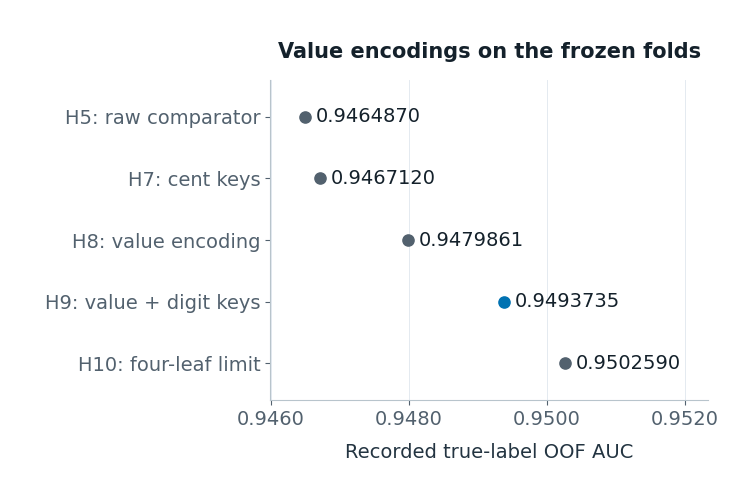

These are recorded OOF AUCs on the same five folds. Blue marks H9, selected for the separate audit; the colour alone does not imply admission. H10 has a higher true-label score but failed its full shuffled-label filter. H9 versus H8 changes the whole digit bundle, including column-subsampling paths.

In [ ]:
recorded_digit_study = {'publication_ready': True,
 'stage': 'Value and digit encodings, recorded 2 November 2026 local time',
 'protocol': {'created_utc': '2026-11-01T20:24:03.210438+00:00',
              'study': 'Prospective S6E11 value and digit ablations; no candidate fit yet',
              'input_sha256': {'train.csv': '87eaa10b8d17a7e4f657b8da1c66242431338bdd8b6ad45861521ac0c0e9fbd5',
                               'test.csv': '10f516959020357b565abaaa4fd25baae97fc2f536d0805695bb7cc15c1660f0',
                               'sample_submission.csv': '13fc6ed8b73de5329884ec490f2a0b750cf29a7cda772b78cfa0cf486f6f35fa'},
              'features': ['amount_usd',
                           'hours_since_last_txn',
                           'txn_count_last_24h',
                           'distance_from_home_km',
                           'card_age_months',
                           'customer_age',
                           'account_balance_usd',
                           'cvv_retry_count',
                           'velocity_score',
                           'time_of_day_hour',
                           'day_of_week',
                           'merchant_risk_score',
                           'prior_disputes',
                           'merchant_category',
                           'card_type',
                           'auth_method',
                           'channel',
                           'device_type',
                           'is_foreign_transaction',
                           'is_new_merchant',
                           'used_vpn',
                           'ip_country_mismatch',
                           'billing_shipping_mismatch',
                           'is_ai_generated_scam_attempt'],
              'reference': {'name': 'H5',
                            'auc': 0.9464870105109693,
                            'oof_sha256': 'f94d5389f99524f8f901411b9f040f73bee822dd0b46b518c598d7e722b14d1e',
                            'fold_ids_sha256': '946567353f68c167ea4f9aa037aad048769d78f4dcc0069791cd3ca0731eca45'},
              'h5_params': {'n_estimators': 600,
                            'num_leaves': 15,
                            'learning_rate': 0.03,
                            'random_state': 42,
                            'n_jobs': 4,
                            'min_child_samples': 40,
                            'reg_lambda': 12,
                            'subsample': 0.85,
                            'subsample_freq': 1,
                            'colsample_bytree': 0.85,
                            'verbosity': -1,
                            'deterministic': True,
                            'force_col_wise': True},
              'recipes': {'h7_cents': {'view': 'cents',
                                       'params': {'n_estimators': 600,
                                                  'num_leaves': 15,
                                                  'learning_rate': 0.03,
                                                  'random_state': 42,
                                                  'n_jobs': 4,
                                                  'min_child_samples': 40,
                                                  'reg_lambda': 12,
                                                  'subsample': 0.85,
                                                  'subsample_freq': 1,
                                                  'colsample_bytree': 0.85,
                                                  'verbosity': -1,
                                                  'deterministic': True,
                                                  'force_col_wise': True},
                                       'feature_count': 30},
                          'h8_per_value': {'view': 'per_value',
                                           'params': {'n_estimators': 600,
                                                      'num_leaves': 15,
                                                      'learning_rate': 0.03,
                                                      'random_state': 42,
                                                      'n_jobs': 4,
                                                      'min_child_samples': 40,
                                                      'reg_lambda': 12,
                                                      'subsample': 0.85,
                                                      'subsample_freq': 1,
                                                      'colsample_bytree': 0.85,
                                                      'verbosity': -1,
                                                      'deterministic': True,
                                                      'force_col_wise': True},
                                           'feature_count': 48},
                          'h9_digits': {'view': 'digits',
                                        'params': {'n_estimators': 600,
                                                   'num_leaves': 15,
                                                   'learning_rate': 0.03,
                                                   'random_state': 42,
                                                   'n_jobs': 4,
                                                   'min_child_samples': 40,
                                                   'reg_lambda': 12,
                                                   'subsample': 0.85,
                                                   'subsample_freq': 1,
                                                   'colsample_bytree': 0.85,
                                                   'verbosity': -1,
                                                   'deterministic': True,
                                                   'force_col_wise': True},
                                        'feature_count': 96},
                          'h10_small_trees': {'view': 'digits',
                                              'params': {'n_estimators': 1600,
                                                         'num_leaves': 4,
                                                         'learning_rate': 0.03,
                                                         'random_state': 42,
                                                         'n_jobs': 4,
                                                         'min_child_samples': 100,
                                                         'reg_lambda': 1.0,
                                                         'subsample': 0.8,
                                                         'subsample_freq': 1,
                                                         'colsample_bytree': 0.5,
                                                         'verbosity': -1,
                                                         'deterministic': True,
                                                         'force_col_wise': True},
                                              'feature_count': 96}},
              'digit_definition': 'Six nonnegative float columns. k=np.rint(100*x), '
                                  'cent=k%100,integer=k//100,tens=k//1000,tenths=k//10,leading1/leading2/length '
                                  'of integer; zero has leading0,length1. Quantisation '
                                  'affects derived keys ONLY. The test exception id962974 '
                                  'amount9.982 remains unchanged in raw inputs/raw-value TE; '
                                  'record it, never infer its label.',
              'encoding': 'Official sklearn1.6.1 TargetEncoder '
                          'binary/smooth20/cv5/shuffleTrue/RS0; per-column fit_transform on '
                          'outer-fitting keys and labels for inner cross-fitting; transform '
                          'outervalidation/test using allouterfitting labels. No source rows, '
                          'H6 flagcount, outer eval_set/early stopping, outside predictions, '
                          'or ID/target inputs.',
              'fixed_cv': 'Original true-label SKFold5 shuffle42; exact H5foldIDs. Complete '
                          'RandomState0 label permutation independently re-stratified5x42 for '
                          'each same-budget negative pipeline. H9/H10 share identical '
                          'prepared matrices on each fold.',
              'cv_fit_budget': 40,
              'selection': 'Evaluate all4 recipes and all4 full seed0 controls. Eligible only '
                           'gainH5>=.0005, >=4of5positive pairedfold deltas, and unchanged '
                           'oldabs(nullAUC-.5)<.003. Choose highesteligiblepooledOOFonce '
                           '(ties favour earlierlisted recipe). If noneeligible, no '
                           'holdoutaudit/no submission. Selection is exploratory on '
                           'reuseddata, not unbiased performance.',
              'final_audit': {'splits': [20261105, 20261106],
                              'label_seeds': [2027, 2137, 2267],
                              'mc_seeds': {'20261105_2027': 202611051,
                                           '20261105_2137': 202611052,
                                           '20261105_2267': 202611053,
                                           '20261106_2027': 202611061,
                                           '20261106_2137': 202611062,
                                           '20261106_2267': 202611063},
                              'canary_mc_seeds': {'20261105': 202611059,
                                                  '20261106': 202611069},
                              'fit_budget': 12,
                              'criteria': 'Bothcandidate-minusH5trueholdoutgains>=.0005; '
                                          'all6Bonferroni-adjustednegativeMCp>=.05, '
                                          'both2test-adjustedcopiedtargetcanaryp<.01; '
                                          'inputtargetpoisonanddisjointnessaudits pass.',
                              'test': 'Singlefixedlabel-independent20%KFoldpartitioneachsplit. '
                                      'PCG64MC4999 fixedcountlabelassignments, absAUC-.5 with '
                                      'midrank ties/equalityextreme, p=(extreme+1)/5000. '
                                      'Bonferronifamilies6negative/2canary, '
                                      'dependenciesallowed. Alpha.05chosenbeforefits, '
                                      'strongerrejectionthresholdthan historicalV2.01; old '
                                      'fullCVbandalso required.',
                              'limits': 'Reused/overlappingcompetitiondata and '
                                        'modelselectionhistory. Not externalvalidation, '
                                        'pooledOOFp, calibratedweakleak detection, '
                                        'featureavailabilityaudit, or safetycertificate. '
                                        'Labels existinprocess; excludeheldlabelsfromfitAPI '
                                        'and savepredictionbeforemetrics. Canaries '
                                        'teststrongdirectcopy only.'},
              'submission_budget': 1,
              'submission_reading_rule': 'Bind exactlychosen5foldCV CSV hash before '
                                         'holdoutfits. Require '
                                         'numericpass+independentsciencereview+rootdecision. '
                                         'If auditfails do notfallback toanotherrecipe, '
                                         'changecriteria/seed/budget, or addmodels/blends. '
                                         'Atmost1acceptednewsubmission, '
                                         'reportpublicoutcomeeitherdirection againstH5.94709. '
                                         'No tuning/selection usingthe newpublicscore.',
              'history': 'OriginalH5FAIL and V2decision remain unchanged. Newstudy '
                         'retainsoldfullnullfilter and adds stronger '
                         'freshholdoutfamilythreshold; it does not retrospectively admit H6 '
                         'or H3/H4.',
              'credits': {'goodpjw2008': 'https://www.kaggle.com/code/goodpjw2008/s6e11-part-3-digits-leak-the-label-lb-0-95113',
                          'alexchilton': 'https://www.kaggle.com/code/alexchilton/credit-card-fraud-lb-0-9496-shallow-tree-stack',
                          'sklearn': 'https://scikit-learn.org/1.6/modules/generated/sklearn.preprocessing.TargetEncoder.html'},
              'adaptation': 'Own bounded ablations with official inner-fold TE, '
                            'fixed1600trees/noouterES. Not exactreproductionofthe '
                            'publishedensembles or evidenceoftheirclaimedgeneratormechanism.',
              'field_sources_sha256': {'checks/stage10/field_digits/s6e11-part-3-digits-leak-the-label-lb-0-95113.ipynb': 'e498b85f828f1979643908cbd33df7f64f9e23a4ff1c7b47d655ff4e5db9f28a',
                                       'checks/stage10/field_eda/s6e11-deep-eda-original-data-artifacts.ipynb': '550117bec14d075b41fad0b6f07fc2a298eb2c6e53b35faec5a24fb6d9ad2291',
                                       'checks/stage10/field_stack/credit-card-fraud-lb-0-9496-shallow-tree-stack.ipynb': 'bd1ef11fc60c7de08ce31ea95e1d3e41ca128a9dae7c6e13e6ae3c966cdef380'},
              'runner_sha256': '7db01282d41372109e0da87e8abb70f166f5dc3762c492ced219a2a2e3ae2577',
              'resource_policy': '8GB localhost: prepare cents, per_value and digits '
                                 'viewgroups sequentially; H9/H10 reuse exactly the same '
                                 'digit matrices. FourLightGBMthreads, no '
                                 'parallelmodelworkers. Drop group matrices before nextview.',
              'additional_analyses': 'Save six outer-heldout raw-value target encodings from '
                                     'H8 for single-feature AUC plots against the signed raw '
                                     'magnitude AUC. Allsixspecifiedfloats are reported; no '
                                     'max(AUC,1-AUC), selecteddirection, newmodel or '
                                     'outcome-guided featurechoice. '
                                     'Quantization/non-centexceptions/unseenkeycounts are '
                                     'descriptive target-free input audits.'},
 'screen': {'status': 'complete',
            'started_utc': '2026-11-01T20:29:55.846402+00:00',
            'runner_sha256': '7db01282d41372109e0da87e8abb70f166f5dc3762c492ced219a2a2e3ae2577',
            'reference_auc': 0.9464870105109693,
            'libraries': {'lightgbm': '4.6.0',
                          'numpy': '2.2.6',
                          'pandas': '2.2.3',
                          'scikit-learn': '1.6.1',
                          'scipy': '1.18.0'},
            'recipes': {'h7_cents': {'true_folds': [{'fold': 0,
                                                     'auc': 0.9451728674877523,
                                                     'trees': 600,
                                                     'features': 30,
                                                     'seconds': 48.741409749985905,
                                                     'delta_vs_h5': 0.0003782253659612156},
                                                    {'fold': 1,
                                                     'auc': 0.9481143806548455,
                                                     'trees': 600,
                                                     'features': 30,
                                                     'seconds': 40.956476333987666,
                                                     'delta_vs_h5': -0.00017274998374006145},
                                                    {'fold': 2,
                                                     'auc': 0.9518239828022212,
                                                     'trees': 600,
                                                     'features': 30,
                                                     'seconds': 46.65528083301615,
                                                     'delta_vs_h5': 0.0006630819069388671},
                                                    {'fold': 3,
                                                     'auc': 0.9471281860249329,
                                                     'trees': 600,
                                                     'features': 30,
                                                     'seconds': 45.48120137499063,
                                                     'delta_vs_h5': 1.7207572529875925e-05},
                                                    {'fold': 4,
                                                     'auc': 0.9415367316795562,
                                                     'trees': 600,
                                                     'features': 30,
                                                     'seconds': 40.691937790979864,
                                                     'delta_vs_h5': 0.00019029623908095594}],
                                     'null_folds': [{'fold': 0,
                                                     'auc': 0.5056935499185289,
                                                     'trees': 600,
                                                     'features': 30,
                                                     'seconds': 29.768925083015347},
                                                    {'fold': 1,
                                                     'auc': 0.5056728904718557,
                                                     'trees': 600,
                                                     'features': 30,
                                                     'seconds': 30.20872049999889},
                                                    {'fold': 2,
                                                     'auc': 0.5107297075894642,
                                                     'trees': 600,
                                                     'features': 30,
                                                     'seconds': 31.499634750012774},
                                                    {'fold': 3,
                                                     'auc': 0.502284642382583,
                                                     'trees': 600,
                                                     'features': 30,
                                                     'seconds': 25.136768291005865},
                                                    {'fold': 4,
                                                     'auc': 0.5018511594566772,
                                                     'trees': 600,
                                                     'features': 30,
                                                     'seconds': 26.621390749991406}],
                                     'auc': 0.9467119892639174,
                                     'delta_vs_h5': 0.00022497875294813507,
                                     'control_auc': 0.5052004689704832,
                                     'positive_folds': 4,
                                     'fold_deltas': [0.0003782253659612156,
                                                     -0.00017274998374006145,
                                                     0.0006630819069388671,
                                                     1.7207572529875925e-05,
                                                     0.00019029623908095594],
                                     'old_null_pass': False,
                                     'eligible_for_final_audit': False,
                                     'submission_sha256': '62471528ed606bbffd4b35bb764a2651756cdc9d798642a4329c237cb38c6932'},
                        'h8_per_value': {'true_folds': [{'fold': 0,
                                                         'auc': 0.9463510251259609,
                                                         'trees': 600,
                                                         'features': 48,
                                                         'seconds': 54.11144887498813,
                                                         'delta_vs_h5': 0.0015563830041698257},
                                                        {'fold': 1,
                                                         'auc': 0.9496216216995531,
                                                         'trees': 600,
                                                         'features': 48,
                                                         'seconds': 55.38850020899554,
                                                         'delta_vs_h5': 0.001334491060967502},
                                                        {'fold': 2,
                                                         'auc': 0.9531933146921486,
                                                         'trees': 600,
                                                         'features': 48,
                                                         'seconds': 52.880937791022006,
                                                         'delta_vs_h5': 0.0020324137968662503},
                                                        {'fold': 3,
                                                         'auc': 0.9487017560784522,
                                                         'trees': 600,
                                                         'features': 48,
                                                         'seconds': 54.120016833010595,
                                                         'delta_vs_h5': 0.0015907776260492001},
                                                        {'fold': 4,
                                                         'auc': 0.9423239641404878,
                                                         'trees': 600,
                                                         'features': 48,
                                                         'seconds': 56.50397766599781,
                                                         'delta_vs_h5': 0.0009775287000125532}],
                                         'null_folds': [{'fold': 0,
                                                         'auc': 0.49663188873935504,
                                                         'trees': 600,
                                                         'features': 48,
                                                         'seconds': 39.10618129200884},
                                                        {'fold': 1,
                                                         'auc': 0.5017397949555849,
                                                         'trees': 600,
                                                         'features': 48,
                                                         'seconds': 43.291664458985906},
                                                        {'fold': 2,
                                                         'auc': 0.5002074199177037,
                                                         'trees': 600,
                                                         'features': 48,
                                                         'seconds': 39.511896750016604},
                                                        {'fold': 3,
                                                         'auc': 0.5024576564767719,
                                                         'trees': 600,
                                                         'features': 48,
                                                         'seconds': 38.7089896670077},
                                                        {'fold': 4,
                                                         'auc': 0.5024005185115759,
                                                         'trees': 600,
                                                         'features': 48,
                                                         'seconds': 42.665814834006596}],
                                         'auc': 0.9479860747258101,
                                         'delta_vs_h5': 0.0014990642148408062,
                                         'control_auc': 0.500608985938339,
                                         'positive_folds': 5,
                                         'fold_deltas': [0.0015563830041698257,
                                                         0.001334491060967502,
                                                         0.0020324137968662503,
                                                         0.0015907776260492001,
                                                         0.0009775287000125532],
                                         'old_null_pass': True,
                                         'eligible_for_final_audit': True,
                                         'submission_sha256': 'e40462419cdf5813af270089c78665a8a0131fc2ba78fb99652f83690c2f31b6'},
                        'h9_digits': {'true_folds': [{'fold': 0,
                                                      'auc': 0.9482684715298259,
                                                      'trees': 600,
                                                      'features': 96,
                                                      'seconds': 85.5125023330038,
                                                      'delta_vs_h5': 0.0034738294080347565},
                                                     {'fold': 1,
                                                      'auc': 0.9502944943361856,
                                                      'trees': 600,
                                                      'features': 96,
                                                      'seconds': 89.06737333300407,
                                                      'delta_vs_h5': 0.0020073636976000175},
                                                     {'fold': 2,
                                                      'auc': 0.9547848939710893,
                                                      'trees': 600,
                                                      'features': 96,
                                                      'seconds': 91.07966524999938,
                                                      'delta_vs_h5': 0.003623993075806964},
                                                     {'fold': 3,
                                                      'auc': 0.9505676156119874,
                                                      'trees': 600,
                                                      'features': 96,
                                                      'seconds': 93.11391362501308,
                                                      'delta_vs_h5': 0.0034566371595844414},
                                                     {'fold': 4,
                                                      'auc': 0.9432289525753708,
                                                      'trees': 600,
                                                      'features': 96,
                                                      'seconds': 80.743474124989,
                                                      'delta_vs_h5': 0.0018825171348955116}],
                                      'null_folds': [{'fold': 0,
                                                      'auc': 0.5017286010509148,
                                                      'trees': 600,
                                                      'features': 96,
                                                      'seconds': 66.70533545897342},
                                                     {'fold': 1,
                                                      'auc': 0.5014285143807145,
                                                      'trees': 600,
                                                      'features': 96,
                                                      'seconds': 74.04323700000532},
                                                     {'fold': 2,
                                                      'auc': 0.5026494379487292,
                                                      'trees': 600,
                                                      'features': 96,
                                                      'seconds': 68.23133395801415},
                                                     {'fold': 3,
                                                      'auc': 0.5045855042538996,
                                                      'trees': 600,
                                                      'features': 96,
                                                      'seconds': 58.32654629199533},
                                                     {'fold': 4,
                                                      'auc': 0.498072705268909,
                                                      'trees': 600,
                                                      'features': 96,
                                                      'seconds': 58.8947643339925}],
                                      'auc': 0.9493735374849556,
                                      'delta_vs_h5': 0.002886526973986281,
                                      'control_auc': 0.5017606892301936,
                                      'positive_folds': 5,
                                      'fold_deltas': [0.0034738294080347565,
                                                      0.0020073636976000175,
                                                      0.003623993075806964,
                                                      0.0034566371595844414,
                                                      0.0018825171348955116],
                                      'old_null_pass': True,
                                      'eligible_for_final_audit': True,
                                      'submission_sha256': '9405c5036ee8f94cf4b6e539beb43a71385c222812ce47b51df906fb719d3b7d'},
                        'h10_small_trees': {'true_folds': [{'fold': 0,
                                                            'auc': 0.94936233938769,
                                                            'trees': 1600,
                                                            'features': 96,
                                                            'seconds': 101.65111679199617,
                                                            'delta_vs_h5': 0.004567697265898896},
                                                           {'fold': 1,
                                                            'auc': 0.9507428544483091,
                                                            'trees': 1600,
                                                            'features': 96,
                                                            'seconds': 104.69645058401511,
                                                            'delta_vs_h5': 0.0024557238097234757},
                                                           {'fold': 2,
                                                            'auc': 0.9552754185395567,
                                                            'trees': 1600,
                                                            'features': 96,
                                                            'seconds': 104.17506191600114,
                                                            'delta_vs_h5': 0.004114517644274285},
                                                           {'fold': 3,
                                                            'auc': 0.9515709587779767,
                                                            'trees': 1600,
                                                            'features': 96,
                                                            'seconds': 102.42628612500266,
                                                            'delta_vs_h5': 0.004459980325573709},
                                                           {'fold': 4,
                                                            'auc': 0.9445551816400657,
                                                            'trees': 1600,
                                                            'features': 96,
                                                            'seconds': 96.51645512500545,
                                                            'delta_vs_h5': 0.00320874619959044}],
                                            'null_folds': [{'fold': 0,
                                                            'auc': 0.5020911378742665,
                                                            'trees': 1600,
                                                            'features': 96,
                                                            'seconds': 92.60956670800806},
                                                           {'fold': 1,
                                                            'auc': 0.500887954864531,
                                                            'trees': 1600,
                                                            'features': 96,
                                                            'seconds': 100.39043016699725},
                                                           {'fold': 2,
                                                            'auc': 0.5086066852655937,
                                                            'trees': 1600,
                                                            'features': 96,
                                                            'seconds': 83.02113895898219},
                                                           {'fold': 3,
                                                            'auc': 0.5022687118617521,
                                                            'trees': 1600,
                                                            'features': 96,
                                                            'seconds': 77.6317667500116},
                                                           {'fold': 4,
                                                            'auc': 0.5028767407224494,
                                                            'trees': 1600,
                                                            'features': 96,
                                                            'seconds': 77.14073779198225}],
                                            'auc': 0.9502590175536698,
                                            'delta_vs_h5': 0.0037720070427005314,
                                            'control_auc': 0.5034035799553033,
                                            'positive_folds': 5,
                                            'fold_deltas': [0.004567697265898896,
                                                            0.0024557238097234757,
                                                            0.004114517644274285,
                                                            0.004459980325573709,
                                                            0.00320874619959044],
                                            'old_null_pass': False,
                                            'eligible_for_final_audit': False,
                                            'submission_sha256': 'e70bc1c4818482b78de38e90b13a3e4d5693dd8e4b0faf2f5071b9d0c7bcd499'}},
            'univariate_numeric': [{'column': 'amount_usd',
                                    'raw_auc': 0.5448494958612227,
                                    'heldout_per_value_te_auc': 0.5465696918145085},
                                   {'column': 'hours_since_last_txn',
                                    'raw_auc': 0.4317779424786956,
                                    'heldout_per_value_te_auc': 0.5849897734527576},
                                   {'column': 'distance_from_home_km',
                                    'raw_auc': 0.5038733190708004,
                                    'heldout_per_value_te_auc': 0.5108501971422594},
                                   {'column': 'account_balance_usd',
                                    'raw_auc': 0.5062529019486234,
                                    'heldout_per_value_te_auc': 0.5357721086550941},
                                   {'column': 'velocity_score',
                                    'raw_auc': 0.7107927599976092,
                                    'heldout_per_value_te_auc': 0.7064406682879019},
                                   {'column': 'merchant_risk_score',
                                    'raw_auc': 0.7489359267576935,
                                    'heldout_per_value_te_auc': 0.7493992870383831}],
            'selected_for_final_audit': 'h9_digits',
            'submission_decision': 'No upload: final audit, independent review and a separate '
                                   'root decision are still required.',
            'completed_utc': '2026-11-01T21:18:29.968445+00:00'},
 'input_audit': [{'file': 'train',
                  'column': 'amount_usd',
                  'non_cent_aligned_rows': 0,
                  'max_cent_residual': 5.820766091346741e-11,
                  'exceptions': [],
                  'zero_count': 0},
                 {'file': 'train',
                  'column': 'hours_since_last_txn',
                  'non_cent_aligned_rows': 0,
                  'max_cent_residual': 4.547473508864641e-13,
                  'exceptions': [],
                  'zero_count': 0},
                 {'file': 'train',
                  'column': 'distance_from_home_km',
                  'non_cent_aligned_rows': 0,
                  'max_cent_residual': 4.547473508864641e-13,
                  'exceptions': [],
                  'zero_count': 12},
                 {'file': 'train',
                  'column': 'account_balance_usd',
                  'non_cent_aligned_rows': 0,
                  'max_cent_residual': 9.313225746154785e-10,
                  'exceptions': [],
                  'zero_count': 0},
                 {'file': 'train',
                  'column': 'velocity_score',
                  'non_cent_aligned_rows': 0,
                  'max_cent_residual': 9.094947017729282e-13,
                  'exceptions': [],
                  'zero_count': 48499},
                 {'file': 'train',
                  'column': 'merchant_risk_score',
                  'non_cent_aligned_rows': 0,
                  'max_cent_residual': 9.094947017729282e-13,
                  'exceptions': [],
                  'zero_count': 1631},
                 {'file': 'test',
                  'column': 'amount_usd',
                  'non_cent_aligned_rows': 1,
                  'max_cent_residual': 0.1999999999999318,
                  'exceptions': [{'id': 962974, 'raw': 9.982}],
                  'zero_count': 0},
                 {'file': 'test',
                  'column': 'hours_since_last_txn',
                  'non_cent_aligned_rows': 0,
                  'max_cent_residual': 4.547473508864641e-13,
                  'exceptions': [],
                  'zero_count': 0},
                 {'file': 'test',
                  'column': 'distance_from_home_km',
                  'non_cent_aligned_rows': 0,
                  'max_cent_residual': 4.547473508864641e-13,
                  'exceptions': [],
                  'zero_count': 4},
                 {'file': 'test',
                  'column': 'account_balance_usd',
                  'non_cent_aligned_rows': 0,
                  'max_cent_residual': 9.313225746154785e-10,
                  'exceptions': [],
                  'zero_count': 0},
                 {'file': 'test',
                  'column': 'velocity_score',
                  'non_cent_aligned_rows': 0,
                  'max_cent_residual': 9.094947017729282e-13,
                  'exceptions': [],
                  'zero_count': 20927},
                 {'file': 'test',
                  'column': 'merchant_risk_score',
                  'non_cent_aligned_rows': 0,
                  'max_cent_residual': 9.094947017729282e-13,
                  'exceptions': [],
                  'zero_count': 671}],
 'audit': {'status': 'complete',
           'recipe': 'h9_digits',
           'true_comparisons': [{'split_seed': 20261105,
                                 'h5': 0.9443534995440844,
                                 'h9_digits': 0.9472359102190997,
                                 'delta': 0.002882410675015268},
                                {'split_seed': 20261106,
                                 'h5': 0.9421700058833905,
                                 'h9_digits': 0.9459635582990402,
                                 'delta': 0.0037935524156497147}],
           'negative_controls': [{'name': 'negative_20261105_2027',
                                  'split_seed': 20261105,
                                  'label_seed': 2027,
                                  'prediction_sha256_before_scoring': 'af3d21d21e614f351dc359cfd5e77d8296cec728f6e68ee66d8e748a2c35e5a3',
                                  'auc': 0.4900267836339812,
                                  'p': 0.0884,
                                  'extreme': 441,
                                  'draws': 4999,
                                  'mc_seed': 202611051,
                                  'rows': 139992,
                                  'positives': 2397,
                                  'bonferroni_p': 0.5304},
                                 {'name': 'negative_20261105_2137',
                                  'split_seed': 20261105,
                                  'label_seed': 2137,
                                  'prediction_sha256_before_scoring': '2e87eaa08bffee479033c1f06e648ef8dd71e8d574831cae26fb555802c568d5',
                                  'auc': 0.5043375655380173,
                                  'p': 0.4644,
                                  'extreme': 2321,
                                  'draws': 4999,
                                  'mc_seed': 202611052,
                                  'rows': 139992,
                                  'positives': 2359,
                                  'bonferroni_p': 1.0},
                                 {'name': 'negative_20261105_2267',
                                  'split_seed': 20261105,
                                  'label_seed': 2267,
                                  'prediction_sha256_before_scoring': '384c5d8db58e022c54172835778732e7c1d8e6731d0fb735f639f80133aa36ea',
                                  'auc': 0.496530721097783,
                                  'p': 0.563,
                                  'extreme': 2814,
                                  'draws': 4999,
                                  'mc_seed': 202611053,
                                  'rows': 139992,
                                  'positives': 2316,
                                  'bonferroni_p': 1.0},
                                 {'name': 'negative_20261106_2027',
                                  'split_seed': 20261106,
                                  'label_seed': 2027,
                                  'prediction_sha256_before_scoring': '5e1b1e52e984ee8f5ec0d7438e3ca51e54401aff2f54ad6438855f8e5550e36d',
                                  'auc': 0.5014914449945069,
                                  'p': 0.7944,
                                  'extreme': 3971,
                                  'draws': 4999,
                                  'mc_seed': 202611061,
                                  'rows': 139992,
                                  'positives': 2438,
                                  'bonferroni_p': 1.0},
                                 {'name': 'negative_20261106_2137',
                                  'split_seed': 20261106,
                                  'label_seed': 2137,
                                  'prediction_sha256_before_scoring': 'bf33d1732844a5fbfa38fad123b680f6bb30ef8715b6030a7c116227774014ec',
                                  'auc': 0.5015129776908465,
                                  'p': 0.8,
                                  'extreme': 3999,
                                  'draws': 4999,
                                  'mc_seed': 202611062,
                                  'rows': 139992,
                                  'positives': 2413,
                                  'bonferroni_p': 1.0},
                                 {'name': 'negative_20261106_2267',
                                  'split_seed': 20261106,
                                  'label_seed': 2267,
                                  'prediction_sha256_before_scoring': '3e2ceea2d475f90a42feff94ba117b4dab7009aef9e12f897e6cae56b29a6e8a',
                                  'auc': 0.5073890543206229,
                                  'p': 0.2144,
                                  'extreme': 1071,
                                  'draws': 4999,
                                  'mc_seed': 202611063,
                                  'rows': 139992,
                                  'positives': 2362,
                                  'bonferroni_p': 1.0}],
           'canaries': [{'name': 'canary_20261105',
                         'split_seed': 20261105,
                         'prediction_sha256_before_scoring': 'bdd6ae479e14098d7928ec2ba6f579a9b211926bddd7ae861944d33bc28baa22',
                         'auc': 1.0,
                         'p': 0.0002,
                         'extreme': 0,
                         'draws': 4999,
                         'mc_seed': 202611059,
                         'rows': 139992,
                         'positives': 2397,
                         'bonferroni_p': 0.0004},
                        {'name': 'canary_20261106',
                         'split_seed': 20261106,
                         'prediction_sha256_before_scoring': '2a38e5b31b0ed4d075643035a1d8f799e82e729e414cb7c0285fd9db0e8931e8',
                         'auc': 1.0,
                         'p': 0.0002,
                         'extreme': 0,
                         'draws': 4999,
                         'mc_seed': 202611069,
                         'rows': 139992,
                         'positives': 2438,
                         'bonferroni_p': 0.0004}],
           'input_audits': [{'split_seed': 20261105,
                             'ordinary_target_poison_invariant': True,
                             'fit_valid_disjoint': True},
                            {'split_seed': 20261106,
                             'ordinary_target_poison_invariant': True,
                             'fit_valid_disjoint': True}],
           'runner_sha256': '7db01282d41372109e0da87e8abb70f166f5dc3762c492ced219a2a2e3ae2577',
           'criteria': {'both_true_gains': True,
                        'six_negative_checks': True,
                        'two_copied_target_canaries': True,
                        'input_audits': True},
           'numerically_eligible_for_review': True,
           'decision': 'No automatic admission or submission; review the selected fixed CV '
                       'file and all limitations.'},
 'screen_report_sha256': '21591053cbc21f3f9b4281bdfcc4edc213e2556f762bc77d7e4ade968e15a9b3',
 'binding': {'created_before_audit_fits_utc': '2026-11-01T21:19:36.353185+00:00',
             'selected_recipe': 'h9_digits',
             'cv_csv_sha256': '9405c5036ee8f94cf4b6e539beb43a71385c222812ce47b51df906fb719d3b7d',
             'core_sha256': '7db01282d41372109e0da87e8abb70f166f5dc3762c492ced219a2a2e3ae2577',
             'protocol_sha256': '52b8e9b228d8b49a8dd3f90f524b6c2c3a377d7649d925a5b0337568456fa7cb',
             'screen_report_sha256': '21591053cbc21f3f9b4281bdfcc4edc213e2556f762bc77d7e4ade968e15a9b3',
             'device': 'Private Kaggle CPU; same frozen code/parameters/splits/criteria, both '
                       'true-label recipes use the same worker environment.',
             'scope': 'Audit only. No test predictions enter the bound CV CSV; no upload is '
                      'permitted by this worker.'},
 'audit_environment': {'python': '3.13.15',
                       'platform': 'Linux-6.18.55+-x86_64-with-glibc2.39',
                       'libraries': {'lightgbm': '4.6.0',
                                     'numpy': '2.1.3',
                                     'pandas': '2.3.3',
                                     'scikit-learn': '1.6.1',
                                     'scipy': '1.16.3'}},
 'decision': {'status': 'APPROVE_ONE_FIXED_FILE',
              'recorded_before_public_probe_utc': '2026-11-01T21:39:51.276803+00:00',
              'csv_sha256': '9405c5036ee8f94cf4b6e539beb43a71385c222812ce47b51df906fb719d3b7d',
              'selected_recipe': 'h9_digits',
              'current_recipe_chosen_before_public_result': 'h9_digits',
              'maximum_new_submissions': 1,
              'source_file': 'research_20261102/digit_ablation/outputs/h9_digits/submission.csv',
              'reason': 'Registered screen selection and all registered audit criteria '
                        'passed, independently recomputed. Science and reader explicitly '
                        'approved one exploratory original-file probe and H9 default before '
                        'its public result. Root inspected full results, source binding, MC '
                        'tail counts, data/IDs and limitations.',
              'limits': ['Reused/overlapping development data; selected OOF is exploratory.',
                         'Negative non-rejection does not establish absence of weak leakage; '
                         'canaries check direct copied-target access only.',
                         'Generator mechanism and event-time availability remain unresolved.',
                         'No H8/H10 fallback, blend, reseeding, tuning by public outcome or '
                         'second upload.',
                         'Publish this outcome in either direction. Original H5 failure/H6 '
                         'hold/H10 rejection remain.'],
              'reviews': ['checks/stage10/ONE_UPLOAD_SCIENCE_VERDICT.md',
                          'checks/reviews/stage10_one_upload_reader.md'],
              'later_notebook_release_gates_required': True},
 'submission': {'checked_utc': '2026-11-01T21:41:01.777658+00:00',
                'ref': 57884605,
                'status': 'SubmissionStatus.COMPLETE',
                'file_name': 'candidate_submission.csv',
                'description': 'H9 value-digit study 20261102: fixed 5x42 CSV; OOF0.949374; '
                               'registered audit; one probe',
                'submitted_at': '2026-11-01 21:39:55.597000',
                'public_auc': 0.95009,
                'csv_sha256': '9405c5036ee8f94cf4b6e539beb43a71385c222812ce47b51df906fb719d3b7d',
                'submissions_total': 3,
                'new_submissions_under_this_decision': 1},
 'standing': {'snapshot_utc': '2026-11-01 21:41:04 UTC',
              'rank': 41,
              'ranked_teams': 209,
              'unranked_rows_excluded': 1,
              'team_id': 17243922,
              'public_auc': 0.95009,
              'team_name': 'Georgy Mamarin',
              'accepted_submission_count': 3,
              'archive': 'checks/stage10/post_submit_leaderboard/playground-series-s6e11-publicleaderboard-2026-11-01T21:41:04.csv',
              'csv_sha256': 'f47844ed73ecac6d974b6f2ff2f5b6dc2035539377f384eacb517d4198929c04',
              'scope': 'Dated public leaderboard snapshot, not a final rank or comparable '
                       'cohort improvement.'},
 'opening_prose': '# S6E11: First Checks and a Baseline\n'
                  '\n'
                  'By [Georgy Mamarin](https://www.kaggle.com/georgymamarin)\n'
                  '\n'
                  'Adding value and digit encodings to our 600-tree model of the raw '
                  'predictors (H5) raised out-of-fold (OOF) AUC from **0.9464870 to 0.9493735 '
                  '(H9)**, with gains on all five folds. The highest-scoring alternative '
                  'reached OOF 0.9502590, but failed the predeclared shuffled-label filter '
                  'and was not submitted. Sections 15 and 16 show the ablations, controls and '
                  'separate audit behind the choice.\n'
                  '\n'
                  'One fixed H9 file scored **0.95009 on the public leaderboard** and '
                  'improved on H5 by 0.00300. Our team stood **41/209 ranked teams** in the '
                  '2026-11-01 21:41:04 UTC snapshot. Public AUC and local OOF measure '
                  'different rows; this is a dated public standing, not a final rank. The '
                  "notebook's default fit now produces H9 as the primary "
                  '**`submission.csv`**, with its own metrics and manifest. `CURRENT_CFG` '
                  'lets you change its inputs and settings; the original 300-tree reference '
                  'stays in `reference_submission.csv`.\n'
                  '\n'
                  'Use this notebook to audit all 24 supplied features, compare '
                  'representations and export checked predictions for [Playground S6E11: '
                  'Predicting Credit Card '
                  'Fraud](https://www.kaggle.com/competitions/playground-series-s6e11). The '
                  'recorded investigations explain each selection decision, including the '
                  'original H5 control failure. No cell uploads predictions.',
 'decision_prose': '### Decision and public probe\n'
                   '\n'
                   'H9 passed the original full-control filter and all four criteria in the '
                   'separate audit. Its two true-label gains over H5 were **+0.0028824** and '
                   '**+0.0037936**. The smallest adjusted p among the six negative checks was '
                   '**0.5304**. Independent review supported one exploratory upload of the '
                   'five-fold H9 file that had been bound before the audit. This is an '
                   'operational decision under the recorded criteria; negative non-rejection '
                   'and copied-target detection do not establish that the pipeline is free of '
                   'leakage.\n'
                   '\n'
                   "The accepted submission **57884605** scored **0.95009**, versus H5's "
                   "0.94709 and the first reference's 0.94587. It improved on H5 by 0.00300. "
                   'The team ranked **41 of 209 ranked teams** at **2026-11-01 21:41:04 '
                   'UTC**; teams without a ranked score are excluded. We chose H9 as the '
                   'current recipe before this public result. We did not change its '
                   'parameters or seeds, add a blend or switch to another recipe in response. '
                   'The original H5 failure, H6 hold and H10 rejection remain recorded.\n'
                   '\n'
                   'The screen ran locally with LightGBM 4.6.0, scikit-learn 1.6.1, NumPy '
                   '2.2.6 and pandas 2.2.3. The audit ran on a private Kaggle CPU worker with '
                   'Python 3.13.15, NumPy 2.1.3 and pandas 2.3.3; LightGBM and scikit-learn '
                   'versions matched. Both true-label recipes were compared within that '
                   'worker. This was not a bitwise local reproduction. None of the audit '
                   'models supplied the submitted test predictions.\n'
                   '\n'
                   'The OOF comparison reuses development data after several earlier studies. '
                   'Selection can make its winning score optimistic, and the overlapping '
                   'audit partitions do not provide external validation. We have established '
                   'a useful representation gain under these splits. We have not '
                   'reconstructed the synthetic generator or established when every supplied '
                   'feature became available.',
 'hero_caption': 'These are recorded OOF AUCs on the same five folds. Blue marks H9, selected '
                 'for the separate audit; the colour alone does not imply admission. H10 has '
                 'a higher true-label score but failed its full shuffled-label filter. H9 '
                 'versus H8 changes the whole digit bundle, including column-subsampling '
                 'paths.',
 'current_export': {'decision_before_public_probe': True,
                    'settings': {'recipe_key': 'h9_digits',
                                 'view': 'digits',
                                 'model_params': {'n_estimators': 600,
                                                  'num_leaves': 15,
                                                  'learning_rate': 0.03,
                                                  'random_state': 42,
                                                  'n_jobs': 4,
                                                  'min_child_samples': 40,
                                                  'reg_lambda': 12,
                                                  'subsample': 0.85,
                                                  'subsample_freq': 1,
                                                  'colsample_bytree': 0.85,
                                                  'verbosity': -1,
                                                  'deterministic': True,
                                                  'force_col_wise': True},
                                 'drop_predictors': [],
                                 'n_splits': 5,
                                 'split_seed': 42}}}
digit_reproduction_sources = {'run_digit_study.py': '"""Fixed S6E11 value/digit ablations. Imports never fit models or upload files."""\nfrom pathlib import Path\nfrom datetime import datetime, timezone\nimport hashlib, importlib.metadata, json, time, gc\nimport numpy as np\nimport pandas as pd\nfrom sklearn.preprocessing import OrdinalEncoder, TargetEncoder\nfrom sklearn.model_selection import StratifiedKFold, KFold\nfrom sklearn.metrics import roc_auc_score\nfrom scipy.stats import rankdata\nfrom lightgbm import LGBMClassifier\n\nFLOATS = [\'amount_usd\',\'hours_since_last_txn\',\'distance_from_home_km\',\n          \'account_balance_usd\',\'velocity_score\',\'merchant_risk_score\']\nRECIPES = [\'h7_cents\',\'h8_per_value\',\'h9_digits\',\'h10_small_trees\']\n\ndef sha_file(path):\n    return hashlib.sha256(Path(path).read_bytes()).hexdigest()\n\ndef digest(array):\n    return hashlib.sha256(np.ascontiguousarray(array).tobytes()).hexdigest()\n\ndef write_json(path, value):\n    path=Path(path);tmp=path.with_suffix(\'.tmp\')\n    tmp.write_text(json.dumps(value,indent=2,allow_nan=False)+\'\\n\');tmp.replace(path)\n\ndef digit_keys(frame):\n    """Round only the derived keys to cents; retain every raw predictor unchanged."""\n    result={}\n    for name in FLOATS:\n        x=frame[name].to_numpy(dtype=np.float64)\n        if not (np.isfinite(x).all() and (x>=0).all()):\n            raise ValueError(\'The recorded digit-key protocol requires finite nonnegative values.\')\n        k=np.rint(100*x).astype(np.int64);integer=k//100\n        length=np.ones(len(k),dtype=np.int64)\n        positive=integer>0\n        length[positive]=np.floor(np.log10(integer[positive])).astype(np.int64)+1\n        result[\'cent_\'+name]=k%100\n        result[\'integer_\'+name]=integer\n        result[\'tens_\'+name]=k//1000\n        result[\'tenths_\'+name]=k//10\n        result[\'leading1_\'+name]=integer//np.power(10,length-1)\n        result[\'leading2_\'+name]=integer//np.power(10,np.maximum(length-2,0))\n        result[\'length_\'+name]=length\n    return pd.DataFrame(result,index=frame.index)\n\ndef input_audit(train,test):\n    rows=[]\n    for label,frame in [(\'train\',train),(\'test\',test)]:\n        for column in FLOATS:\n            scaled=frame[column].to_numpy(dtype=float)*100\n            residual=np.abs(scaled-np.rint(scaled));bad=np.flatnonzero(residual>1e-6)\n            rows.append({\'file\':label,\'column\':column,\'non_cent_aligned_rows\':len(bad),\n                \'max_cent_residual\':float(residual.max()),\n                \'exceptions\':[{\'id\':int(frame.iloc[i].id),\'raw\':float(frame.iloc[i][column])} for i in bad],\n                \'zero_count\':int(frame[column].eq(0).sum())})\n    return rows\n\ndef native_matrices(fitting,others,columns):\n    cats=[c for c in columns if not pd.api.types.is_numeric_dtype(fitting[c])]\n    nums=[c for c in columns if c not in cats]\n    encoder=OrdinalEncoder(handle_unknown=\'use_encoded_value\',unknown_value=-1)\n    if cats:encoder.fit(fitting[cats].astype(\'string\').fillna(\'<missing>\').astype(str))\n    out=[]\n    for frame in [fitting]+others:\n        values=frame[nums].to_numpy(dtype=np.float32)\n        if cats:values=np.column_stack([values,encoder.transform(frame[cats].astype(\'string\').fillna(\'<missing>\').astype(str))]).astype(np.float32)\n        out.append(pd.DataFrame(values,columns=nums+cats,index=frame.index))\n    return out,list(range(len(nums),len(columns)))\n\ndef make_views(fitting,others,labels,features,modes):\n    """Held-out labels are not arguments. TE training rows use inner cross-fitting."""\n    frames=[fitting.loc[:,features].reset_index(drop=True).copy()]+[\n        f.loc[:,features].reset_index(drop=True).copy() for f in others]\n    keys=[digit_keys(f) for f in frames] if any(m in {\'cents\',\'digits\'} for m in modes) else None\n    encoded=[{} for _ in frames];audit=[]\n    if any(m in {\'per_value\',\'digits\'} for m in modes):\n        key_columns=[(\'value_\'+c,[f[c] for f in frames]) for c in features]\n        if \'digits\' in modes:key_columns += [(\'digit_\'+c,[k[c] for k in keys]) for c in keys[0].columns]\n        for name,series in key_columns:\n            arrays=[s.to_numpy().reshape(-1,1) for s in series]\n            encoder=TargetEncoder(target_type=\'binary\',smooth=20.0,cv=5,shuffle=True,random_state=0)\n            encoded[0][\'te_\'+name]=encoder.fit_transform(arrays[0],labels).ravel().astype(np.float32)\n            unseen=[]\n            for j in range(1,len(frames)):\n                encoded[j][\'te_\'+name]=encoder.transform(arrays[j]).ravel().astype(np.float32)\n                unseen.append(int((~series[j].isin(encoder.categories_[0])).sum()))\n            audit.append({\'name\':name,\'fitting_unique\':len(encoder.categories_[0]),\'unseen_other_rows\':unseen})\n    result={}\n    for mode in modes:\n        prepared=[]\n        for j,frame in enumerate(frames):\n            additions={}\n            if mode in {\'cents\',\'digits\'}:\n                additions.update({c:keys[j][c].to_numpy(dtype=np.float32) for c in keys[j] if c.startswith(\'cent_\')})\n            if mode in {\'per_value\',\'digits\'}:\n                additions.update({c:v for c,v in encoded[j].items() if mode==\'digits\' or c.startswith(\'te_value_\')})\n            prepared.append(pd.concat([frame,pd.DataFrame(additions,index=frame.index)],axis=1))\n        result[mode]=native_matrices(prepared[0],prepared[1:],list(prepared[0].columns))\n    return result,audit\n\ndef conditional_reference(labels,prediction,seed):\n    labels=np.asarray(labels);n=len(labels);n1=int(labels.sum());n0=n-n1\n    assert n1>0 and n0>0\n    ranks2=np.rint(2*rankdata(prediction,method=\'average\')).astype(np.int64)\n    constant=n1*(n1+1);centre=n1*n0\n    observed=int(ranks2[labels==1].sum())-constant\n    auc=observed/(2*n1*n0)\n    assert abs(auc-roc_auc_score(labels,prediction))<1e-12\n    statistic=abs(observed-centre);rng=np.random.Generator(np.random.PCG64(seed))\n    null=np.empty(4999);extreme=0\n    for i in range(4999):\n        value=int(ranks2[rng.choice(n,n1,replace=False)].sum())-constant\n        extreme+=abs(value-centre)>=statistic;null[i]=value/(2*n1*n0)\n    return {\'auc\':float(auc),\'p\':(1+int(extreme))/5000,\'extreme\':int(extreme),\n            \'draws\':4999,\'mc_seed\':seed,\'rows\':n,\'positives\':n1},null\n\ndef checked_data(data,protocol):\n    data=Path(data)\n    for name,expected in protocol[\'input_sha256\'].items():assert sha_file(data/name)==expected,name\n    train=pd.read_csv(data/\'train.csv\');test=pd.read_csv(data/\'test.csv\');sample=pd.read_csv(data/\'sample_submission.csv\')\n    features=[c for c in train if c not in {\'id\',\'is_fraud\'}]\n    assert features==protocol[\'features\'] and len(train)==699960 and len(test)==299984\n    assert train.is_fraud.sum()==11689 and train.id.is_unique and test.id.is_unique\n    return train,test,sample,features\n\ndef run_study(data,output,reference_oof,reference_folds,protocol):\n    out=Path(output);out.mkdir(parents=True,exist_ok=True)\n    assert sha_file(reference_oof)==protocol[\'reference\'][\'oof_sha256\']\n    assert sha_file(reference_folds)==protocol[\'reference\'][\'fold_ids_sha256\']\n    train,test,sample,features=checked_data(data,protocol);y=train.is_fraud.to_numpy()\n    reference=np.load(reference_oof);saved_ids=np.load(reference_folds)\n    assert reference.shape==y.shape and saved_ids.shape==y.shape\n    write_json(out/\'recorded_protocol.json\',protocol)\n    write_json(out/\'input_audit.json\',input_audit(train,test))\n    report={\'status\':\'running\',\'started_utc\':datetime.now(timezone.utc).isoformat(),\n        \'runner_sha256\':sha_file(__file__),\'reference_auc\':float(roc_auc_score(y,reference)),\n        \'libraries\':{p:importlib.metadata.version(p) for p in [\'lightgbm\',\'numpy\',\'pandas\',\'scikit-learn\',\'scipy\']},\n        \'recipes\':{name:{\'true_folds\':[],\'null_folds\':[]} for name in RECIPES},\'encoder_audits\':[]}\n    predictions={name:{\'true\':np.full(len(y),np.nan),\'null\':np.full(len(y),np.nan),\'test\':np.zeros(len(test))} for name in RECIPES}\n    univariate_te=np.full((len(y),len(FLOATS)),np.nan,dtype=np.float32)\n    all_ids={}\n    for arm,labels in [(\'true\',y),(\'null\',np.random.RandomState(0).permutation(y))]:\n        ids=np.full(len(y),-1,np.int16);all_ids[arm]=ids\n        for k,(fit,valid) in enumerate(StratifiedKFold(5,shuffle=True,random_state=42).split(train,labels)):\n            ids[valid]=k\n            if arm==\'true\':np.testing.assert_array_equal(saved_ids[valid],np.full(len(valid),k))\n            others=[train.iloc[valid]]+([test] if arm==\'true\' else [])\n            for mode,names in [(\'cents\',[\'h7_cents\']),(\'per_value\',[\'h8_per_value\']),\n                               (\'digits\',[\'h9_digits\',\'h10_small_trees\'])]:\n                prepared,audit=make_views(train.iloc[fit],others,labels[fit],features,{mode})\n                report[\'encoder_audits\'].append({\'arm\':arm,\'fold\':k,\'view\':mode,\'fields\':audit})\n                matrices,cats=prepared[mode];a,b=matrices[:2]\n                if arm==\'true\' and mode==\'per_value\':\n                    univariate_te[valid]=b[[\'te_value_\'+c for c in FLOATS]].to_numpy()\n                for name in names:\n                    spec=protocol[\'recipes\'][name];began=time.perf_counter()\n                    model=LGBMClassifier(**spec[\'params\']).fit(a,labels[fit],categorical_feature=cats)\n                    np.testing.assert_array_equal(model.classes_,[0,1]);assert model.n_estimators_==spec[\'params\'][\'n_estimators\']\n                    values=model.predict_proba(b)[:,1];assert np.isfinite(values).all()\n                    predictions[name][arm][valid]=values\n                    if arm==\'true\':predictions[name][\'test\']+=model.predict_proba(matrices[2])[:,1]/5\n                    row={\'fold\':k,\'auc\':float(roc_auc_score(labels[valid],values)),\n                        \'trees\':int(model.n_estimators_),\'features\':a.shape[1],\'seconds\':time.perf_counter()-began}\n                    assert a.shape[1]==spec[\'feature_count\']\n                    if arm==\'true\':row[\'delta_vs_h5\']=row[\'auc\']-float(roc_auc_score(y[valid],reference[valid]))\n                    report[\'recipes\'][name][arm+\'_folds\'].append(row)\n                    print(arm,name,\'fold\',k,row,flush=True)\n                    del model\n                del prepared,matrices,a,b;gc.collect()\n            write_json(out/\'report.json\',report)\n    assert np.isfinite(univariate_te).all()\n    np.save(out/\'univariate_heldout_te.npy\',univariate_te)\n    report[\'univariate_numeric\']=[{\'column\':c,\'raw_auc\':float(roc_auc_score(y,train[c])),\n        \'heldout_per_value_te_auc\':float(roc_auc_score(y,univariate_te[:,j]))} for j,c in enumerate(FLOATS)]\n    for name,arrays in predictions.items():\n        destination=out/name;destination.mkdir(exist_ok=True)\n        for key in arrays:assert np.isfinite(arrays[key]).all() and ((arrays[key]>=0)&(arrays[key]<=1)).all()\n        np.save(destination/\'oof.npy\',arrays[\'true\']);np.save(destination/\'test.npy\',arrays[\'test\']);np.save(destination/\'fold_ids.npy\',all_ids[\'true\'])\n        np.savez_compressed(destination/\'control.npz\',oof=arrays[\'null\'],labels=np.random.RandomState(0).permutation(y),fold_ids=all_ids[\'null\'])\n        auc=float(roc_auc_score(y,arrays[\'true\']));null_auc=float(roc_auc_score(np.random.RandomState(0).permutation(y),arrays[\'null\']))\n        row=report[\'recipes\'][name];deltas=[f[\'delta_vs_h5\'] for f in row[\'true_folds\']]\n        row.update(auc=auc,delta_vs_h5=auc-report[\'reference_auc\'],control_auc=null_auc,\n            positive_folds=sum(d>0 for d in deltas),fold_deltas=deltas,\n            old_null_pass=bool(abs(null_auc-.5)<.003),\n            eligible_for_final_audit=bool(auc-report[\'reference_auc\']>=.0005 and sum(d>0 for d in deltas)>=4 and abs(null_auc-.5)<.003))\n        aligned=sample.copy();order=pd.Index(test.id).get_indexer(aligned.id);assert (order>=0).all()\n        aligned[\'is_fraud\']=arrays[\'test\'][order];aligned.to_csv(destination/\'submission.csv\',index=False)\n        row[\'submission_sha256\']=sha_file(destination/\'submission.csv\');write_json(destination/\'report.json\',row)\n    eligible=[name for name in RECIPES if report[\'recipes\'][name][\'eligible_for_final_audit\']]\n    selected=max(eligible,key=lambda name:report[\'recipes\'][name][\'auc\']) if eligible else None\n    report.update(status=\'complete\',selected_for_final_audit=selected,\n        submission_decision=\'No upload: final audit, independent review and a separate root decision are still required.\',\n        completed_utc=datetime.now(timezone.utc).isoformat())\n    write_json(out/\'report.json\',report);print(json.dumps({name:{k:r[k] for k in [\'auc\',\'delta_vs_h5\',\'control_auc\',\'eligible_for_final_audit\']} for name,r in report[\'recipes\'].items()},indent=2),flush=True)\n    return report\n\ndef run_final_audit(data,output,recipe,protocol):\n    out=Path(output);out.mkdir(parents=True,exist_ok=True)\n    train,test,sample,features=checked_data(data,protocol);y=train.is_fraud.to_numpy()\n    spec=protocol[\'recipes\'][recipe];rules=protocol[\'final_audit\']\n    report={\'status\':\'running\',\'recipe\':recipe,\'true_comparisons\':[],\'negative_controls\':[],\n            \'canaries\':[],\'input_audits\':[],\'runner_sha256\':sha_file(__file__)}\n    def fit_predict(labels,fit,valid,name,candidate=True,canary=False):\n        mode=spec[\'view\'] if candidate else \'raw\'\n        prepared,_=make_views(train.iloc[fit],[train.iloc[valid]],labels[fit],features,{mode})\n        (a,b),cats=prepared[mode]\n        if not canary:\n            poison=train.iloc[valid].copy();poison[\'is_fraud\']=1-poison.is_fraud\n            rebuilt,_=make_views(train.iloc[fit],[poison],labels[fit],features,{mode})\n            (aa,bb),cc=rebuilt[mode];np.testing.assert_array_equal(a,aa);np.testing.assert_array_equal(b,bb);assert cats==cc\n        if canary:\n            a=a.copy();b=b.copy();a[\'copied_assigned_target\']=labels[fit];b[\'copied_assigned_target\']=labels[valid]\n        params=spec[\'params\'] if candidate else protocol[\'h5_params\']\n        model=LGBMClassifier(**params).fit(a,labels[fit],categorical_feature=cats)\n        assert model.n_estimators_==params[\'n_estimators\']\n        prediction=model.predict_proba(b)[:,1];assert np.isfinite(prediction).all()\n        np.save(out/(name+\'_prediction.npy\'),prediction);sealed=digest(prediction)\n        held=labels[valid]\n        np.savez_compressed(out/(name+\'.npz\'),prediction=prediction,labels=held,fitting_indices=fit,validation_indices=valid)\n        return prediction,held,sealed\n    for split_seed in rules[\'splits\']:\n        fit,valid=next(KFold(5,shuffle=True,random_state=split_seed).split(train));scores={}\n        for candidate,name in [(False,\'h5\'),(True,recipe)]:\n            prediction,held,sealed=fit_predict(y,fit,valid,f\'true_{name}_{split_seed}\',candidate=candidate)\n            scores[name]=float(roc_auc_score(held,prediction))\n        delta=scores[recipe]-scores[\'h5\'];report[\'true_comparisons\'].append({\'split_seed\':split_seed,**scores,\'delta\':delta})\n        report[\'input_audits\'].append({\'split_seed\':split_seed,\'ordinary_target_poison_invariant\':True,\'fit_valid_disjoint\':not len(np.intersect1d(fit,valid))})\n        print(\'true comparison\',report[\'true_comparisons\'][-1],flush=True)\n        for label_seed in rules[\'label_seeds\']:\n            labels=np.random.RandomState(label_seed).permutation(y);name=f\'negative_{split_seed}_{label_seed}\'\n            prediction,held,sealed=fit_predict(labels,fit,valid,name)\n            measured,reference=conditional_reference(held,prediction,rules[\'mc_seeds\'][f\'{split_seed}_{label_seed}\'])\n            np.save(out/(name+\'_reference.npy\'),reference)\n            report[\'negative_controls\'].append({\'name\':name,\'split_seed\':split_seed,\'label_seed\':label_seed,\'prediction_sha256_before_scoring\':sealed,**measured})\n            print(name,measured,flush=True);write_json(out/\'report.json\',report)\n        labels=np.random.RandomState(rules[\'label_seeds\'][0]).permutation(y);name=f\'canary_{split_seed}\'\n        prediction,held,sealed=fit_predict(labels,fit,valid,name,canary=True)\n        measured,reference=conditional_reference(held,prediction,rules[\'canary_mc_seeds\'][str(split_seed)])\n        np.save(out/(name+\'_reference.npy\'),reference)\n        report[\'canaries\'].append({\'name\':name,\'split_seed\':split_seed,\'prediction_sha256_before_scoring\':sealed,**measured})\n        print(name,measured,flush=True);write_json(out/\'report.json\',report)\n    for row in report[\'negative_controls\']:row[\'bonferroni_p\']=min(1.0,6*row[\'p\'])\n    for row in report[\'canaries\']:row[\'bonferroni_p\']=min(1.0,2*row[\'p\'])\n    criteria={\'both_true_gains\':all(r[\'delta\']>=.0005 for r in report[\'true_comparisons\']),\n        \'six_negative_checks\':all(r[\'bonferroni_p\']>=.05 for r in report[\'negative_controls\']),\n        \'two_copied_target_canaries\':all(r[\'bonferroni_p\']<.01 for r in report[\'canaries\']),\n        \'input_audits\':all(all(v for k,v in r.items() if k!=\'split_seed\') for r in report[\'input_audits\'])}\n    report.update(status=\'complete\',criteria=criteria,numerically_eligible_for_review=all(criteria.values()),\n        decision=\'No automatic admission or submission; review the selected fixed CV file and all limitations.\')\n    write_json(out/\'report.json\',report);return report\n', 'reproduce_digit_study.py': '"""Opt-in method replay. Keep this file beside run_digit_study.py in notebook outputs."""\nfrom pathlib import Path\nimport importlib.util,json,copy,hashlib\nimport numpy as np,pandas as pd\nfrom sklearn.model_selection import StratifiedKFold\nfrom sklearn.metrics import roc_auc_score\nfrom lightgbm import LGBMClassifier\n\ndef _load_core():\n    source=Path(__file__).with_name(\'run_digit_study.py\')\n    if not source.exists():\n        raise FileNotFoundError(\'Download run_digit_study.py beside this replay helper.\')\n    spec=importlib.util.spec_from_file_location(\'fixed_digit_study_core\',source)\n    module=importlib.util.module_from_spec(spec);spec.loader.exec_module(module)\n    return module\n\ndef run_screen(data,output,recorded_protocol):\n    """Five fresh H5 reference fits plus the original forty-fit four-recipe screen."""\n    core=_load_core();out=Path(output);out.mkdir(parents=True,exist_ok=True)\n    train,test,sample,features=core.checked_data(data,recorded_protocol)\n    y=train.is_fraud.to_numpy();oof=np.full(len(train),np.nan)\n    test_prediction=np.zeros(len(test));ids=np.full(len(train),-1,np.int16)\n    for k,(fit,valid) in enumerate(StratifiedKFold(5,shuffle=True,random_state=42).split(train,y)):\n        views,_=core.make_views(train.iloc[fit],[train.iloc[valid],test],y[fit],features,{\'raw\'})\n        (a,b,t),cats=views[\'raw\']\n        model=LGBMClassifier(**recorded_protocol[\'h5_params\']).fit(a,y[fit],categorical_feature=cats)\n        oof[valid]=model.predict_proba(b)[:,1];test_prediction+=model.predict_proba(t)[:,1]/5;ids[valid]=k\n        print(\'Recomputed H5 reference fold\',k,roc_auc_score(y[valid],oof[valid]),flush=True)\n        del views,a,b,t,model\n    assert np.isfinite(oof).all() and np.isfinite(test_prediction).all()\n    np.save(out/\'reference_h5_oof.npy\',oof);np.save(out/\'reference_h5_test.npy\',test_prediction)\n    np.save(out/\'reference_h5_fold_ids.npy\',ids)\n    replay=copy.deepcopy(recorded_protocol)\n    replay[\'reference\'].update(name=\'Fresh fixed H5 reference\',auc=float(roc_auc_score(y,oof)),\n        oof_sha256=core.sha_file(out/\'reference_h5_oof.npy\'),\n        fold_ids_sha256=core.sha_file(out/\'reference_h5_fold_ids.npy\'))\n    replay[\'replay_scope\']=\'Fresh reference plus recorded four-recipe method; historical pre-fit file binding is not recreated. No automatic admission/upload.\'\n    replay[\'replay_reference_fits\']=5\n    report=core.run_study(data,out/\'screen\',out/\'reference_h5_oof.npy\',out/\'reference_h5_fold_ids.npy\',replay)\n    report.update(historical_file_binding_recreated=False,\n        submission_decision=\'Numeric method replay only. No original admission or new upload is recreated.\',\n        replay_total_model_fits=45)\n    core.write_json(out/\'screen/report.json\',report)\n    return report\n\ndef run_audit(data,output,recipe,recorded_protocol):\n    """Replay twelve audit fits; numeric criteria do not recreate the historical decision."""\n    core=_load_core()\n    report=core.run_final_audit(data,output,recipe,recorded_protocol)\n    report.update(historical_file_binding_recreated=False,admission=False,\n        decision=\'Numeric method replay only; the historical pre-fit selected-file binding and independent submission review are not recreated.\')\n    core.write_json(Path(output)/\'report.json\',report)\n    return report\n'}
for s10_filename,s10_source in digit_reproduction_sources.items():
    (output/s10_filename).write_text(s10_source)

In [ ]:
from sklearn.preprocessing import TargetEncoder

FLOATS = ['amount_usd','hours_since_last_txn','distance_from_home_km',
          'account_balance_usd','velocity_score','merchant_risk_score']

RECIPES = ['h7_cents','h8_per_value','h9_digits','h10_small_trees']

def digit_keys(frame):
    """Round only the derived keys to cents; retain every raw predictor unchanged."""
    result={}
    for name in FLOATS:
        x=frame[name].to_numpy(dtype=np.float64)
        if not (np.isfinite(x).all() and (x>=0).all()):
            raise ValueError('The recorded digit-key protocol requires finite nonnegative values.')
        k=np.rint(100*x).astype(np.int64);integer=k//100
        length=np.ones(len(k),dtype=np.int64)
        positive=integer>0
        length[positive]=np.floor(np.log10(integer[positive])).astype(np.int64)+1
        result['cent_'+name]=k%100
        result['integer_'+name]=integer
        result['tens_'+name]=k//1000
        result['tenths_'+name]=k//10
        result['leading1_'+name]=integer//np.power(10,length-1)
        result['leading2_'+name]=integer//np.power(10,np.maximum(length-2,0))
        result['length_'+name]=length
    return pd.DataFrame(result,index=frame.index)

def native_matrices(fitting,others,columns):
    cats=[c for c in columns if not pd.api.types.is_numeric_dtype(fitting[c])]
    nums=[c for c in columns if c not in cats]
    encoder=OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1)
    if cats:encoder.fit(fitting[cats].astype('string').fillna('<missing>').astype(str))
    out=[]
    for frame in [fitting]+others:
        values=frame[nums].to_numpy(dtype=np.float32)
        if cats:values=np.column_stack([values,encoder.transform(frame[cats].astype('string').fillna('<missing>').astype(str))]).astype(np.float32)
        out.append(pd.DataFrame(values,columns=nums+cats,index=frame.index))
    return out,list(range(len(nums),len(columns)))

def make_views(fitting,others,labels,features,modes):
    """Held-out labels are not arguments. TE training rows use inner cross-fitting."""
    frames=[fitting.loc[:,features].reset_index(drop=True).copy()]+[
        f.loc[:,features].reset_index(drop=True).copy() for f in others]
    keys=[digit_keys(f) for f in frames] if any(m in {'cents','digits'} for m in modes) else None
    encoded=[{} for _ in frames];audit=[]
    if any(m in {'per_value','digits'} for m in modes):
        key_columns=[('value_'+c,[f[c] for f in frames]) for c in features]
        if 'digits' in modes:key_columns += [('digit_'+c,[k[c] for k in keys]) for c in keys[0].columns]
        for name,series in key_columns:
            arrays=[s.to_numpy().reshape(-1,1) for s in series]
            encoder=TargetEncoder(target_type='binary',smooth=20.0,cv=5,shuffle=True,random_state=0)
            encoded[0]['te_'+name]=encoder.fit_transform(arrays[0],labels).ravel().astype(np.float32)
            unseen=[]
            for j in range(1,len(frames)):
                encoded[j]['te_'+name]=encoder.transform(arrays[j]).ravel().astype(np.float32)
                unseen.append(int((~series[j].isin(encoder.categories_[0])).sum()))
            audit.append({'name':name,'fitting_unique':len(encoder.categories_[0]),'unseen_other_rows':unseen})
    result={}
    for mode in modes:
        prepared=[]
        for j,frame in enumerate(frames):
            additions={}
            if mode in {'cents','digits'}:
                additions.update({c:keys[j][c].to_numpy(dtype=np.float32) for c in keys[j] if c.startswith('cent_')})
            if mode in {'per_value','digits'}:
                additions.update({c:v for c,v in encoded[j].items() if mode=='digits' or c.startswith('te_value_')})
            prepared.append(pd.concat([frame,pd.DataFrame(additions,index=frame.index)],axis=1))
        result[mode]=native_matrices(prepared[0],prepared[1:],list(prepared[0].columns))
    return result,audit

### Define the keys and audit their precision

The six float columns are `amount_usd`, `hours_since_last_txn`, `distance_from_home_km`, `account_balance_usd`, `velocity_score` and `merchant_risk_score`. For derived keys only, set `k = rint(100*x)`. The seven keys per column are the cent remainder, integer part, tens group, tenths group, first digit, first two digits and integer-part length. Zero has leading digits 0 and length 1. These definitions use one row at a time, without labels or distribution estimates.

A strict two-decimal assumption would fail: test row **962974** has `amount_usd=9.982`. The raw predictor and its raw-value target-encoding key remain **9.982**. Only the derived keys use its nearest-cent representation, 9.98. No label is available for that row, and we infer none. The examples below demonstrate the transformation; they are not additional training transactions.

In [ ]:
s10_audit=pd.DataFrame(recorded_digit_study['input_audit'])
display(styled_table(s10_audit[['file','column','non_cent_aligned_rows']]
    .set_index(['file','column']).rename(columns={'non_cent_aligned_rows':'Rows beyond cent precision'})))
s10_examples=[1371.37,9.982,0.0]
s10_example_frame=pd.DataFrame({c:s10_examples for c in FLOATS})
s10_example_keys=digit_keys(s10_example_frame)
s10_example_table=pd.DataFrame({str(v):{'Raw value':str(v),**{
    name:str(int(s10_example_keys.iloc[j][name+'_amount_usd']))
    for name in ['cent','integer','tens','tenths','leading1','leading2','length']}}
    for j,v in enumerate(s10_examples)})
display(styled_table(s10_example_table))

### Keep target encoding inside the fitting data

The visible functions above are used by the current training cell in section 17. For each encoded column, `TargetEncoder(target_type='binary', smooth=20, cv=5, shuffle=True, random_state=0)` supplies inner cross-fitted encodings to outer-fitting rows. Outer validation and test rows use `transform` after fitting on the outer-fitting labels. An unseen value receives the fitting prior. The inner smoothing prior is calculated from that inner fitting fold's labels.

The [scikit-learn 1.6.1 documentation](https://scikit-learn.org/1.6/modules/generated/sklearn.preprocessing.TargetEncoder.html) explains why `fit_transform(X, y)` differs from `fit(X, y).transform(X)`. We use the former for training rows. Held-out labels are not arguments to `make_views`, and neither early stopping nor an outer validation set is passed to the model's fitting API.

Before model fitting, an independent sums-and-counts calculation checked the inner and outer encodings for all 66 encoded columns on a real-data subset with 15,000 fitting rows, including unseen values. The native matrices matched the original helper on the checked rows; all 24 raw columns have no missing values in either file. Poisoning a held-out target column left the ordinary matrices unchanged. These checks audit the implemented data path and do not certify the absence of every possible leak.

In [ ]:
def digit_comparison_figure(study):
    s10_names=['H5: raw comparator','H7: cent keys','H8: value encoding','H9: value + digit keys','H10: four-leaf limit']
    s10_values=[study['screen']['reference_auc']]+[study['screen']['recipes'][k]['auc'] for k in RECIPES]
    s10_selected=study['screen']['selected_for_final_audit']
    fig,ax=plt.subplots(figsize=(7.3,5.0))
    for j,value in enumerate(s10_values):
        colour='#0072B2' if j>0 and RECIPES[j-1]==s10_selected else '#52616E'
        ax.scatter(value,j,color=colour,s=65,zorder=3)
        ax.annotate(f'{value:.7f}',(value,j),xytext=(8,0),textcoords='offset points',va='center',fontsize=14)
    ax.set_yticks(range(5),s10_names);ax.set_ylim(4.6,-.6)
    span=max(s10_values)-min(s10_values)
    ax.set_xlim(min(s10_values)-max(.0005,span*.10),max(s10_values)+max(.002,span*.55))
    ax.set(title='Value encodings on the frozen folds',xlabel='Recorded true-label OOF AUC')
    ax.xaxis.set_major_locator(plt.MaxNLocator(4));ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_:f'{x:.4f}'))
    ax.grid(axis='x');fig.subplots_adjust(left=.37,right=.97,top=.84,bottom=.20)
    return fig


s10_fig=digit_comparison_figure(recorded_digit_study)
s10_fig.savefig('digit_ablation_snapshot.png',dpi=100,facecolor='white');plt.close(s10_fig)

In [ ]:
s10_rows=[]
for s10_key,s10_result in recorded_digit_study['screen']['recipes'].items():
    s10_rows.append({'Recipe':s10_key.split('_')[0].upper(),
        'Inputs':recorded_digit_study['protocol']['recipes'][s10_key]['feature_count'],
        'OOF AUC':s10_result['auc'],'Delta vs H5':s10_result['delta_vs_h5'],
        'Better folds':f"{s10_result['positive_folds']}/5"})
display(styled_table(pd.DataFrame(s10_rows).set_index('Recipe'),
    {'OOF AUC':'{:.7f}','Delta vs H5':'{:+.7f}'}))
for s10_keys in [('h7_cents','h8_per_value'),('h9_digits','h10_small_trees')]:
    s10_fold_table=pd.DataFrame({k.split('_')[0].upper():recorded_digit_study['screen']['recipes'][k]['fold_deltas'] for k in s10_keys})
    display(styled_table(s10_fold_table.rename_axis('fold'),{c:'{:+.7f}' for c in s10_fold_table.columns}))
s10_parameter_table=pd.DataFrame({
    'H5/H7/H8/H9':{k:str(recorded_digit_study['protocol']['h5_params'][k]) for k in
        ['n_estimators','num_leaves','learning_rate','min_child_samples','reg_lambda','subsample','colsample_bytree']},
    'H10':{k:str(recorded_digit_study['protocol']['recipes']['h10_small_trees']['params'][k]) for k in
        ['n_estimators','num_leaves','learning_rate','min_child_samples','reg_lambda','subsample','colsample_bytree']}})
display(styled_table(s10_parameter_table))

The table and fold differences are recorded measurements from this study. All four candidates and all four seed-0 controls were completed, for **40 model fits**. H9 and H10 used identical prepared matrices within each fold. There was no choice of tree count using outer validation labels.

These are exploratory comparisons on reused development data. The folds share training rows, and selecting a recipe on these scores can make its OOF estimate optimistic. The single-feature plot below reports the six prespecified float columns, using their actual outer-held-out encodings from H8. It does not select the most favourable six columns or reverse a raw score after seeing its AUC.

In [ ]:
s10_uni=pd.DataFrame(recorded_digit_study['screen']['univariate_numeric'])
s10_labels=['Amount','Activity gap (hours)','Distance','Balance','Velocity score','Merchant risk score']
s10_fig,s10_ax=plt.subplots(figsize=(7.3,5.7))
for j,row in s10_uni.iterrows():
    s10_ax.plot([row.raw_auc,row.heldout_per_value_te_auc],[j,j],color='#C5CDD3',linewidth=1,zorder=1)
s10_ax.scatter(s10_uni.raw_auc,range(6),s=55,color='#52616E',label='Raw magnitude',zorder=3)
s10_ax.scatter(s10_uni.heldout_per_value_te_auc,range(6),s=55,marker='D',color='#0072B2',label='Held-out value encoding',zorder=3)
s10_ax.axvline(.5,color='#B8C4CC',linestyle='--',linewidth=1)
s10_ax.set_yticks(range(6),s10_labels);s10_ax.set_ylim(5.6,-.6)
s10_ax.set(title='Value identity changes the ranking',xlabel='Single-feature AUC')
s10_ax.set_xlim(min(.48,s10_uni.raw_auc.min()-.02),max(s10_uni.heldout_per_value_te_auc.max(),s10_uni.raw_auc.max())+.025)
s10_ax.xaxis.set_major_locator(plt.MaxNLocator(4));s10_ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_:f'{x:.2f}'))
s10_ax.grid(axis='x');s10_ax.legend(loc='upper center',bbox_to_anchor=(.5,-.20),fontsize=14,ncol=1)
s10_fig.subplots_adjust(left=.33,right=.97,top=.85,bottom=.28)
show_figure(s10_fig,
    'The six float columns were specified before fitting. A raw score ranks by increasing magnitude; '
    'we did not choose its direction from the labels. The encoded score for each row uses only its outer fitting folds. '
    'These exploratory single-feature scores are not conditional feature importance or proof of a generator mechanism.',
    'value_identity_auc.png')

The gap for hours needs care. Increasing hours has AUC 0.4317779; reversing that raw ranking gives 0.5682221. The held-out value encoding scores 0.5849898, a descriptive difference of about 0.01677 against the reversed ranking. The figure keeps the prespecified increasing direction. Value encoding also lowers the velocity score's single-feature AUC from 0.7107928 to 0.7064407. It does not improve every column.

<a id="s16"></a>

## 16. Audit the selected digit recipe

Every candidate also ran its complete pipeline on the same seed-0 shuffled labels, with newly stratified five-fold assignments. Target encoders used the assigned shuffled fitting labels. Tree budgets and feature construction stayed fixed. The old absolute AUC distance below 0.003 from 0.5 remains an operational filter, not a calibrated significance test.

A recipe qualified for the separate audit only if its pooled gain over H5 was at least 0.0005, at least four of five paired fold differences were positive, and its full shuffled control passed the old filter. We chose the highest OOF AUC among qualifying recipes once; an exact tie favoured the earlier listed recipe. If none qualified, the audit and new submission would be skipped.

In [ ]:
s10_null_rows=[]
for s10_key,s10_result in recorded_digit_study['screen']['recipes'].items():
    s10_null_rows.append({'Recipe':s10_key.split('_')[0].upper(),
        'Shuffled AUC':s10_result['control_auc'],'Distance from 0.5':abs(s10_result['control_auc']-.5),
        'Old filter': 'Pass' if s10_result['old_null_pass'] else 'Hold',
        'Eligible for audit':'Yes' if s10_result['eligible_for_final_audit'] else 'No'})
display(styled_table(pd.DataFrame(s10_null_rows).set_index('Recipe'),
    {'Shuffled AUC':'{:.7f}','Distance from 0.5':'{:.7f}'}))
print('Fixed selection for the separate audit:',recorded_digit_study['screen']['selected_for_final_audit'])
print('These are recorded controls; passing an operational filter is not a leakage or feature-availability certificate.')

### Audit the single selected recipe

The new split seeds **20261105** and **20261106**, label permutations **2027**, **2137** and **2267**, fitting budgets and decision criteria were fixed before any candidate fit. Each label-independent 20% partition receives an H5 fit and selected-recipe fit on true labels, three full selected-recipe negative fits and one copied-target canary. This totals **12 fits**. The selected five-fold CSV was hash-bound before this audit started; none of these audit models contributes predictions to it.

For each negative score vector, predictions were saved before scoring. We then generated 4,999 fixed-positive-count label assignments with the recorded PCG64 seed. The two-sided statistic is the absolute AUC distance from 0.5, using midranks and counting equality as extreme. Monte Carlo p-values are `(extreme + 1) / 5000`, with resolution 0.0002. This is not exhaustive enumeration or a p-value for pooled OOF AUC.

The six negative checks form one Bonferroni family, with adjusted p-values required to be at least **0.05**. This is a more sensitive rejection screen than historical V2's 0.01 threshold; it was set before the new study. Both copied-target controls, in a separate family of two, must have adjusted p below 0.01. Both true-label gains over H5 must be at least 0.0005. All input and disjointness checks must pass.

The partitions reuse and overlap the competition training data. They are not independent external validation, and non-rejection does not establish safety. The canaries check a specified strong target-copy violation, leaving sensitivity to weaker leaks unmeasured. Held-out labels remain in process memory, although the ordinary fitting API excludes them. An audit failure permits no fallback to another recipe, replacement seeds or changed thresholds.

In [ ]:
s10_final=recorded_digit_study.get('audit')
if s10_final:
    s10_selected=s10_final['recipe']
    s10_true=pd.DataFrame(s10_final['true_comparisons'])
    s10_true['Partition']=['A','B']
    display(styled_table(s10_true[['Partition','h5',s10_selected,'delta']].set_index('Partition')
        .rename(columns={'h5':'H5 AUC',s10_selected:'Selected AUC','delta':'Delta'}),
        {'H5 AUC':'{:.7f}','Selected AUC':'{:.7f}','Delta':'{:+.7f}'}))
    for s10_seed,s10_label in zip(recorded_digit_study['protocol']['final_audit']['splits'],['A','B']):
        display(callout(f'Partition {s10_label}: these three negative controls belong to the single six-test family.'))
        s10_frame=pd.DataFrame([r for r in s10_final['negative_controls'] if r['split_seed']==s10_seed])
        display(styled_table(s10_frame[['label_seed','auc','p','bonferroni_p']].set_index('label_seed')
            .rename(columns={'auc':'AUC','p':'Raw MC p','bonferroni_p':'Bonferroni p (6)'}),
            {'AUC':'{:.7f}','Raw MC p':'{:.4f}','Bonferroni p (6)':'{:.4f}'}))
    s10_canary=pd.DataFrame(s10_final['canaries']);s10_canary['Partition']=['A','B']
    display(styled_table(s10_canary[['Partition','auc','p','bonferroni_p']].set_index('Partition')
        .rename(columns={'auc':'Copied-target AUC','p':'Raw MC p','bonferroni_p':'Bonferroni p (2)'}),
        {'Copied-target AUC':'{:.7f}','Raw MC p':'{:.4f}','Bonferroni p (2)':'{:.4f}'}))
    display(styled_table(pd.DataFrame({'Passed':s10_final['criteria']})))
else:
    print('No recipe qualified for the predeclared audit. No audit fits or new submission were made.')
(output/'recorded_digit_study.json').write_text(json.dumps(recorded_digit_study,indent=2));

### Historical decision after the digit study

### Decision and public probe

H9 passed the original full-control filter and all four criteria in the separate audit. Its two true-label gains over H5 were **+0.0028824** and **+0.0037936**. The smallest adjusted p among the six negative checks was **0.5304**. Independent review supported one exploratory upload of the five-fold H9 file that had been bound before the audit. This is an operational decision under the recorded criteria; negative non-rejection and copied-target detection do not establish that the pipeline is free of leakage.

The accepted submission **57884605** scored **0.95009**, versus H5's 0.94709 and the first reference's 0.94587. It improved on H5 by 0.00300. The team ranked **41 of 209 ranked teams** at **2026-11-01 21:41:04 UTC**; teams without a ranked score are excluded. We chose H9 as the current recipe before this public result. We did not change its parameters or seeds, add a blend or switch to another recipe in response. The original H5 failure, H6 hold and H10 rejection remain recorded.

The screen ran locally with LightGBM 4.6.0, scikit-learn 1.6.1, NumPy 2.2.6 and pandas 2.2.3. The audit ran on a private Kaggle CPU worker with Python 3.13.15, NumPy 2.1.3 and pandas 2.3.3; LightGBM and scikit-learn versions matched. Both true-label recipes were compared within that worker. This was not a bitwise local reproduction. None of the audit models supplied the submitted test predictions.

The OOF comparison reuses development data after several earlier studies. Selection can make its winning score optimistic, and the overlapping audit partitions do not provide external validation. We have established a useful representation gain under these splits. We have not reconstructed the synthetic generator or established when every supplied feature became available.

This closes the original digit-study decision. Section 19 records a later, separately bounded review under the new public-probe policy. The original H10 hold remains part of that history.

<a id="s17"></a>

## 17. Fit the current recipe and export

`CURRENT_CFG` controls the fresh fit below and the primary `submission.csv`. Section 19 records the default selection and its evidence. This cell fits the stated settings and does not select an argmax again. Change its model parameters, view, split settings or `drop_predictors` to run your own comparison. Dropping a raw predictor removes its raw, per-value and digit-derived model columns together. It can also change column subsampling. The public score belongs to the recorded submitted file. A fresh default fit reproduces its method; compare its saved arrays and report rather than assuming byte-identical CSVs across platforms.

`CFG` still controls the original reference and historical experiments. Its model/drop settings do not silently change the current model. The current report says whether its folds match the reference before calling the fold differences paired. Every run prints its selected key, settings and actual feature/tree counts. Changed settings produce a new exploratory run; they do not inherit a recorded public score or admission decision.

A run using `export_mode='cv_average'` fits **31 models**: the original 26 plus five current-recipe fits. Set `CFG['run_research']=False` for five reference fits and five current fits, giving **10 models**. Choosing `export_mode='full_refit'` adds one full-training fit, giving 32 or 11 models respectively. It uses the same tree budget, without a multiplier. The recorded study tables remain labelled snapshots. The sidebar reports the entire Kaggle run; the current report times the current fitting and export.

The original arrays and `metrics.json` describe the reference. `reference_submission.csv` preserves its predictions. `current_oof.npy` evaluates the CV recipe; `current_test.npy` supplies the selected export. A full refit additionally preserves the five-fold test average in `current_cv_test.npy`, with its own hash. `current_report.json` and `submission_manifest.json` identify the export mode, primary CSV and evaluation scope. The primary CSV is replaced only after all fitting and ID/probability checks succeed. Disabling `run_current_recipe` restores the reference and prints that fallback. Interactive reruns archive old current artifacts in a timestamped `previous_current` folder.

In [ ]:
"""Live current-recipe fit. Historical reference artifacts retain their meaning."""
import shutil
from datetime import datetime, timezone

def fit_current_recipe():
    cur_primary=output/'submission.csv'
    cur_reference=output/'reference_submission.csv'
    if not cur_reference.exists():
        raise FileNotFoundError('Run the reference export in section 9 first.')
    # Reset the primary export before fitting, so an interrupted/disabled rerun has a labelled reference fallback.
    shutil.copyfile(cur_reference,cur_primary)
    cur_stamp=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%f')
    for cur_name in ['current_oof.npy','current_test.npy','current_cv_test.npy','current_folds.csv','current_report.json']:
        cur_path=output/cur_name
        if cur_path.exists():
            cur_archive=output/'previous_current'/cur_stamp
            cur_archive.mkdir(parents=True,exist_ok=True)
            cur_path.rename(cur_archive/cur_name)
    cur_manifest={'primary_csv':'submission.csv','primary_model':'reference',
        'prediction_files':['oof.npy','test.npy'],'metrics_file':'metrics.json',
        'csv_sha256':hashlib.sha256(cur_primary.read_bytes()).hexdigest(),
        'status':'current_training_disabled' if not CFG.get('run_current_recipe',True) else 'current_fit_running_reference_fallback'}
    (output/'submission_manifest.json').write_text(json.dumps(cur_manifest,indent=2))
    if not CFG.get('run_current_recipe',True):
        cur_report={'status':'disabled','primary_model':'reference',
            'message':'The primary submission.csv was restored from reference_submission.csv. No current recipe was fitted.'}
        (output/'current_report.json').write_text(json.dumps(cur_report,indent=2))
        print(cur_report['message']);return cur_report
    cur_settings=CURRENT_CFG
    cur_export_mode=cur_settings.get('export_mode','cv_average')
    if cur_export_mode not in {'cv_average','full_refit'}:
        raise ValueError('Choose cv_average or full_refit as CURRENT_CFG export_mode.')
    cur_features=recorded_digit_study['protocol']['features']
    cur_drop=set(cur_settings['drop_predictors'])
    if cur_drop-set(cur_features):raise ValueError('CURRENT_CFG contains an unknown raw predictor to drop.')
    if len(cur_drop)==len(cur_features):raise ValueError('Keep at least one raw predictor.')
    if cur_settings['view'] not in {'raw','cents','per_value','digits'}:
        raise ValueError('Choose raw, cents, per_value or digits in CURRENT_CFG.')
    cur_y=train['is_fraud'].to_numpy()
    cur_folds=list(StratifiedKFold(cur_settings['n_splits'],shuffle=True,
                                  random_state=cur_settings['split_seed']).split(train,cur_y))
    cur_ids=np.full(len(train),-1,np.int16)
    for cur_k,(_,cur_valid) in enumerate(cur_folds):cur_ids[cur_valid]=cur_k
    cur_oof=np.full(len(train),np.nan);cur_test=np.zeros(len(test));cur_scores=[]
    cur_sources={c:c for c in cur_features}
    cur_sources.update({'te_value_'+c:c for c in cur_features})
    for cur_column in FLOATS:
        cur_sources['cent_'+cur_column]=cur_column
        for cur_key in ['cent','integer','tens','tenths','leading1','leading2','length']:
            cur_sources['te_digit_'+cur_key+'_'+cur_column]=cur_column
    cur_reference_metric_path=output/'reference_metrics.json'
    if not cur_reference_metric_path.exists():cur_reference_metric_path=output/'metrics.json'
    cur_reference_metrics=json.loads(cur_reference_metric_path.read_text())
    cur_reference_config=cur_reference_metrics['config']
    cur_reference_array=np.load(output/'oof.npy')
    cur_reference_oof=cur_reference_array[:,1] if cur_reference_array.ndim==2 else cur_reference_array
    cur_saved_folds=pd.read_csv(output/'folds.csv')
    np.testing.assert_array_equal(cur_saved_folds.id,train.id)
    if cur_reference_oof.shape!=cur_y.shape:raise ValueError('The saved reference predictions do not match these rows.')
    cur_data_fp=hashlib.sha256(pd.util.hash_pandas_object(train[['id','is_fraud']],index=False).values.tobytes()).hexdigest()
    cur_reference_comparable=(cur_reference_config['target']=='is_fraud' and cur_reference_config['positive_class']==1
        and cur_reference_config['task']=='binary' and cur_reference_config['metric']=='auc'
        and cur_reference_metrics['data_fp']==cur_data_fp)
    cur_same_folds=np.array_equal(cur_ids,cur_saved_folds.fold.to_numpy())
    cur_paired=cur_reference_comparable and cur_same_folds
    cur_started=time.perf_counter()
    print('Current recipe key:',cur_settings['recipe_key'])
    print('Current live settings:',json.dumps(cur_settings,indent=2))
    print('CURRENT_CFG sets this fit. The reference comparison uses its saved metrics and folds.')
    cur_report={'status':'running','current_settings':cur_settings,'folds':[],
        'reference_same_folds':bool(cur_same_folds),'reference_target_data_comparable':bool(cur_reference_comparable),
        'paired_reference_comparison':bool(cur_paired),'positive_class':1,'target':'is_fraud',
        'reference_saved_config':cur_reference_config,
        'dropped_raw_predictors':sorted(cur_drop),
        'scope':'Fresh fit from the visible current-recipe code; recorded study results are a separate snapshot.'}
    (output/'current_report.json').write_text(json.dumps(cur_report,indent=2))
    for cur_k,(cur_fit,cur_valid) in enumerate(cur_folds):
        cur_views,_=make_views(train.iloc[cur_fit],[train.iloc[cur_valid],test],
                               cur_y[cur_fit],cur_features,{cur_settings['view']})
        (cur_a,cur_b,cur_t),cur_cats=cur_views[cur_settings['view']]
        cur_cat_names=[cur_a.columns[i] for i in cur_cats]
        cur_keep=[c for c in cur_a if cur_sources[c] not in cur_drop]
        cur_a,cur_b,cur_t=[d.loc[:,cur_keep] for d in [cur_a,cur_b,cur_t]]
        cur_cats=[cur_keep.index(c) for c in cur_cat_names if c in cur_keep]
        cur_model=LGBMClassifier(**cur_settings['model_params']).fit(cur_a,cur_y[cur_fit],categorical_feature=cur_cats)
        np.testing.assert_array_equal(cur_model.classes_,[0,1])
        cur_oof[cur_valid]=cur_model.predict_proba(cur_b)[:,1]
        cur_test+=cur_model.predict_proba(cur_t)[:,1]/len(cur_folds)
        cur_auc=float(roc_auc_score(cur_y[cur_valid],cur_oof[cur_valid]));cur_scores.append(cur_auc)
        cur_row={'fold':cur_k,'auc':cur_auc,'features':len(cur_keep),'actual_trees':int(cur_model.n_estimators_)}
        if cur_paired:cur_row['delta_vs_reference']=cur_auc-float(roc_auc_score(cur_y[cur_valid],cur_reference_oof[cur_valid]))
        cur_report['folds'].append(cur_row)
        (output/'current_report.json').write_text(json.dumps(cur_report,indent=2))
        print('Current fold:',cur_row)
        del cur_views,cur_a,cur_b,cur_t,cur_model
    assert np.isfinite(cur_oof).all() and np.isfinite(cur_test).all()
    assert ((cur_oof>=0)&(cur_oof<=1)).all() and ((cur_test>=0)&(cur_test<=1)).all()
    cur_refit_report=None
    if cur_export_mode=='full_refit':
        # Preserve the five-fold deployment vector separately from the full-training export.
        np.save(output/'current_cv_test.npy',cur_test)
        cur_full_views,_=make_views(train,[test],cur_y,cur_features,{cur_settings['view']})
        (cur_full_a,cur_full_t),cur_full_cats=cur_full_views[cur_settings['view']]
        cur_full_cat_names=[cur_full_a.columns[i] for i in cur_full_cats]
        cur_full_a,cur_full_t=[d.loc[:,cur_keep] for d in [cur_full_a,cur_full_t]]
        cur_full_cats=[cur_keep.index(c) for c in cur_full_cat_names if c in cur_keep]
        cur_full_model=LGBMClassifier(**cur_settings['model_params']).fit(
            cur_full_a,cur_y,categorical_feature=cur_full_cats)
        np.testing.assert_array_equal(cur_full_model.classes_,[0,1])
        assert cur_full_model.n_estimators_==cur_settings['model_params']['n_estimators']
        cur_test=cur_full_model.predict_proba(cur_full_t)[:,1]
        assert np.isfinite(cur_test).all() and ((cur_test>=0)&(cur_test<=1)).all()
        cur_refit_report={'fit_rows':len(train),'features':len(cur_keep),
            'actual_trees':int(cur_full_model.n_estimators_),
            'cv_test_sha256':hashlib.sha256((output/'current_cv_test.npy').read_bytes()).hexdigest(),
            'evaluation':'No OOF estimate for the full-training refit. The reported OOF evaluates its CV recipe.'}
        del cur_full_views,cur_full_a,cur_full_t,cur_full_model
    cur_order=pd.Index(test.id).get_indexer(sample.id)
    assert (cur_order>=0).all() and len(np.unique(cur_order))==len(test)
    cur_submission=sample.copy();cur_submission['is_fraud']=cur_test[cur_order]
    np.testing.assert_array_equal(cur_submission.id,sample.id)
    cur_auc=float(roc_auc_score(cur_y,cur_oof))
    np.save(output/'current_oof.npy',cur_oof);np.save(output/'current_test.npy',cur_test)
    pd.DataFrame({'id':train.id,'fold':cur_ids}).to_csv(output/'current_folds.csv',index=False)
    cur_report.update(status='complete',auc=cur_auc,cv_recipe_auc=cur_auc,
        export_mode=cur_export_mode,full_refit=cur_refit_report,
        predictive_fits=len(cur_folds)+(cur_export_mode=='full_refit'),feature_names=cur_keep,
        reference_auc=float(roc_auc_score(cur_y,cur_reference_oof)) if cur_reference_comparable else None,
        delta_vs_reference=cur_auc-float(roc_auc_score(cur_y,cur_reference_oof)) if cur_reference_comparable else None,
        elapsed_seconds=time.perf_counter()-cur_started,
        data_fingerprint=cur_data_fp,
        split_fingerprint=hashlib.sha256(cur_data_fp.encode()+cur_ids.tobytes()).hexdigest(),
        libraries={p:importlib.metadata.version(p) for p in ['lightgbm','numpy','pandas','scikit-learn']},
        output_oof_sha256=hashlib.sha256((output/'current_oof.npy').read_bytes()).hexdigest(),
        output_test_sha256=hashlib.sha256((output/'current_test.npy').read_bytes()).hexdigest())
    (output/'current_report.json').write_text(json.dumps(cur_report,indent=2))
    cur_temp=output/'current_submission.tmp.csv';cur_submission.to_csv(cur_temp,index=False);cur_temp.replace(cur_primary)
    cur_manifest.update(status='complete',primary_model='current',recipe_key=cur_settings['recipe_key'],
        export_mode=cur_export_mode,oof_scope='CV recipe only; not an evaluation of a full refit',
        prediction_files=['current_oof.npy','current_test.npy'],metrics_file='current_report.json',
        csv_sha256=hashlib.sha256(cur_primary.read_bytes()).hexdigest())
    if cur_export_mode=='full_refit':
        cur_manifest['cv_average_test_file']='current_cv_test.npy'
        cur_manifest['cv_average_test_sha256']=cur_refit_report['cv_test_sha256']
    (output/'submission_manifest.json').write_text(json.dumps(cur_manifest,indent=2))
    cur_formats={'auc':'{:.7f}'}
    if cur_paired:cur_formats['delta_vs_reference']='{:+.7f}'
    display(styled_table(pd.DataFrame(cur_report['folds']).set_index('fold'),cur_formats))
    display(callout(f'The CV recipe has pooled OOF AUC {cur_auc:.7f}. '
                    f'The primary submission.csv uses {cur_export_mode}. '
                    'A full-training refit has no separate OOF estimate. '
                    'current_report.json and submission_manifest.json describe that file; '
                    'the original reference remains in reference_submission.csv.'))
    print('Current recipe export complete. No file was uploaded.')
    return cur_report

current_recipe_report=fit_current_recipe()

### Repeat the full recorded screen or audit

The outputs contain `recorded_digit_study.json`, `run_digit_study.py` and its companion `reproduce_digit_study.py`. Keep the two Python files together. Imports perform no model fits.

`run_digit_screen=True` performs **45 fits**: five to rebuild the fixed H5 reference from the attached data, then the original four-recipe screen's 40 fits. The original recorded screen reused an existing H5 array, so its measured budget was 40. The replay records a fresh reference binding rather than assuming byte-identical historical arrays on another platform.

`run_digit_audit=True` repeats the selected recipe's **12 audit fits** and Monte Carlo calculations. It reproduces the numerical method, without recreating the original pre-fit selected-file binding or submission review. It never grants admission or uploads a file.

Both switches are False by default. They load separate modules and write reports under `recomputed_digit_screen` and `recomputed_digit_audit`. Their fixed recorded recipes do not inherit edits to `CURRENT_CFG`. With `cv_average`, enabling both adds 45 + 12 to the 31-fit route, giving **88 fits**. A full refit adds one more. Reading the recorded findings needs neither switch.

In [ ]:
if CFG.get('run_digit_screen',False):
    s10_replay=load_reproducer('reproduce_digit_study.py')
    s10_replay.run_screen(DATA,output/'recomputed_digit_screen',recorded_digit_study['protocol'])
if CFG.get('run_digit_audit',False):
    s10_selected=recorded_digit_study['screen']['selected_for_final_audit']
    if s10_selected is None:
        raise ValueError('The recorded study selected no recipe for this audit.')
    s10_replay=load_reproducer('reproduce_digit_study.py')
    s10_replay.run_audit(DATA,output/'recomputed_digit_audit',s10_selected,recorded_digit_study['protocol'])
print('Optional method replays never replace submission.csv or upload predictions.')

<a id="s18"></a>

## 18. Separate representation groups from column sampling

H9 combines repeated-value encodings, cent keys and integer or leading-digit keys. Which groups help under the same tree budget? The earlier H9 versus H8 comparison also changed how many columns could be sampled for each tree. Here we separate the groups and repeat the bundle comparison with column sampling disabled.

This recorded representation study ended before the H10 review in section 19. It selected no new submission and changed no primary export. At that stage, the accepted H9 file scored **0.95009 public AUC**. The measurements below are cross-validation results from that stage.

In [ ]:
import base64 as s11_base64, zlib as s11_zlib
s11_payload = json.loads(s11_zlib.decompress(s11_base64.b64decode('...')))
recorded_representation_study = s11_payload['study']
representation_reproduction_sources = s11_payload['sources']
for s11_filename, s11_source in representation_reproduction_sources.items():
    (output/s11_filename).write_text(s11_source)
(output/'recorded_representation_study.json').write_text(json.dumps(recorded_representation_study, indent=2));

### Partition the added columns before fitting

All recipes retain the same 24 raw predictors. V, C and I partition the 72 additions in H9. C deliberately combines numeric cent remainders with their target encodings; this experiment does not separate those two parts. I contains six key types for each of the six float predictors, including the tenths key.

We fit all eight on/off combinations of V, C and I with `colsample_bytree=1.0`. We also fit V alone and V+C+I afresh at 0.85, the original H8/H9 setting. That makes **ten recipes, five folds each: 50 fits and 30,000 trees**. Every recipe uses the fixed 600-tree H9 parameters apart from the specified column fraction. There is no outer-validation early stopping, tree-budget search or selection by public score.

In [ ]:
s11_groups = pd.DataFrame([
    {'Group': 'Raw', 'Inputs': 24, 'Representation': 'The original predictors, always retained.'},
    {'Group': 'V', 'Inputs': 24, 'Representation': 'Target encodings of the 24 raw values.'},
    {'Group': 'C', 'Inputs': 12, 'Representation': 'Six numeric cent remainders and six target-encoded cent remainders.'},
    {'Group': 'I', 'Inputs': 36, 'Representation': 'Target encodings of integer, tens, tenths, leading-one, leading-two and length keys for each of six floats.'}
]).set_index('Group')
display(styled_table(s11_groups).set_properties(**{'white-space': 'normal', 'overflow-wrap': 'anywhere'}))

### Select literal column subsets

The two functions below partition the full H9 matrix by column name and retain the original raw predictors in every view.

In [ ]:
def groups_for(full,features):
    cols=list(full.columns)
    groups={
        'V':[c for c in cols if c.startswith('te_value_')],
        'C':[c for c in cols if c.startswith('cent_') or c.startswith('te_digit_cent_')],
        'I':[c for c in cols if c.startswith('te_digit_') and not c.startswith('te_digit_cent_')],
    }
    assert {g:len(v) for g,v in groups.items()}=={'V':24,'C':12,'I':36}
    additions=sum(groups.values(),[])
    assert len(set(additions))==72 and set(cols)==set(features)|set(additions)
    assert len(cols)==96 and not {'id','is_fraud'} & set(cols)
    return groups

def project(matrices,full_cats,features,groups,active):
    allowed=set(features)|{c for g in active for c in groups[g]}
    columns=[c for c in matrices[0] if c in allowed]
    cat_names=[matrices[0].columns[i] for i in full_cats]
    cats=[columns.index(c) for c in cat_names if c in columns]
    result=[a.loc[:,columns] for a in matrices]
    assert len(columns)==24+sum(len(groups[g]) for g in active)
    assert [columns[i] for i in cats]==cat_names
    return result,cats

### Inspect the actual fitting loop

The following is the exact allocation-and-fitting excerpt from `representation_study.py`. It is displayed for inspection and does not execute a second study. The complete runnable file in outputs includes the checked inputs, fixed fold construction and final OOF validation. Enable the optional replay below to run that file in its own output folder.

```python
predictions={r['name']:np.full(len(y),np.nan) for r in p['recipes']}
write_json(out/'report.json',report)
for k,(fit,valid) in enumerate(splits):
    prep_started=time.perf_counter();matrices,cats,groups,audit=make_fold(frame,fit,valid,p)
    prep_seconds=time.perf_counter()-prep_started
    report['encoder_audits'].append({'fold':k,'preparation_seconds':prep_seconds,'fields':audit,
        'full_train_matrix_sha256':array_sha(matrices[0].to_numpy()),
        'full_valid_matrix_sha256':array_sha(matrices[1].to_numpy()),'groups':groups,
        'fitting_indices_sha256':array_sha(fit),'validation_indices_sha256':array_sha(valid)})
    for r in p['recipes']:
        (a,b),pcats=project(matrices,cats,p['features'],groups,r['groups'])
        params={**p['params'],'colsample_bytree':r['colsample_bytree']}
        before=time.perf_counter()
        model=LGBMClassifier(**params).fit(a,y[fit],categorical_feature=pcats)
        assert model.n_estimators_==600 and model.booster_.num_trees()==600
        np.testing.assert_array_equal(model.classes_,[0,1])
        values=model.predict_proba(b)[:,1]
        assert values.shape==(len(valid),) and np.isfinite(values).all() and ((values>=0)&(values<=1)).all()
        assert np.isnan(predictions[r['name']][valid]).all()
        predictions[r['name']][valid]=values
        row={'fold':k,'auc':float(roc_auc_score(y[valid],values)),'trees':int(model.n_estimators_),
            'features':a.shape[1],'seconds':time.perf_counter()-before,'columns':list(a.columns),
            'categorical_indices':pcats,'train_matrix_sha256':array_sha(a.to_numpy()),
            'valid_matrix_sha256':array_sha(b.to_numpy()),'prediction_sha256':array_sha(values),
            'params':params}
        assert a.shape[1]==r['feature_count']
        report['recipes'][r['name']]['folds'].append(row);report['actual_fits']+=1;report['actual_trees']+=600
        folder=out/r['name'];folder.mkdir(exist_ok=True)
        np.save(folder/'oof.partial.npy',predictions[r['name']])
        print('fold',k,r['name'],row['auc'],'seconds',round(row['seconds'],2),flush=True)
        write_json(out/'report.json',report)
        del model,a,b;gc.collect()
    del matrices;gc.collect()
```

The runner builds the full 96-column H9 matrices once per outer fold, then projects their named columns for every recipe. The functions above are the exact selection functions embedded in the standalone runner. Each subset preserves its column order and recomputes the categorical indices. All variants within a fold share the same fitting-only encodings. Editing these displayed functions does not change the fixed replay, which loads the checked source files written above. A different study needs an updated protocol and source binding.

The encoder is unchanged from section 15: its outer-fitting rows receive inner cross-fitted encodings, while outer-validation rows receive transforms fitted on outer-fitting labels. The original five stratified folds and assigned true labels are fixed. Before fitting, real-data checks reconstruct all 66 encoded maps, compare the raw and V projections with their separate preparations, test every subset projection and poison held-out target values. These checks concern the implemented data path; they do not certify the absence of every possible leak.

### Compare all eight full-column recipes

The table reports the complete factorial at column fraction 1.0. Its comparator is the fresh raw-only 600-tree recipe at that same fraction, not the original 300-tree reference. A pooled AUC difference and the number of positive fold differences answer different questions; both are calculated below.

In [ ]:
# Pooled-AUC differences and fold differences are distinct quantities.
s11_report = recorded_representation_study['report']
if s11_report['status'] != 'complete':
    raise ValueError('The recorded representation study is not complete.')
s11_recipes = s11_report['recipes']
s11_factorial_keys = ['raw_100', 'V_100', 'C_100', 'I_100',
                      'VC_100', 'VI_100', 'CI_100', 'VCI_100']
s11_sampling_keys = ['V_085', 'VCI_085']
s11_expected_keys = s11_factorial_keys + s11_sampling_keys
if set(s11_recipes) != set(s11_expected_keys):
    raise ValueError('The recorded recipe list differs from the fixed ten-recipe design.')

def representation_label(groups):
    return '+'.join(groups) if groups else 'Raw only'

def representation_delta(with_key, without_key):
    with_recipe, without_recipe = s11_recipes[with_key], s11_recipes[without_key]
    with_folds = {row['fold']: row['auc'] for row in with_recipe['folds']}
    without_folds = {row['fold']: row['auc'] for row in without_recipe['folds']}
    if set(with_folds) != set(range(5)) or set(without_folds) != set(range(5)):
        raise ValueError('A recorded comparison needs all five aligned folds.')
    fold_deltas = [with_folds[k] - without_folds[k] for k in range(5)]
    return {'delta': with_recipe['auc'] - without_recipe['auc'],
            'fold_deltas': fold_deltas,
            'positive_folds': sum(value > 0 for value in fold_deltas)}

s11_result_rows = []
s11_plot_records = []
for s11_key in s11_expected_keys:
    s11_result = s11_recipes[s11_key]
    s11_expected_count = 24 + sum({'V': 24, 'C': 12, 'I': 36}[g] for g in s11_result['groups'])
    if s11_result['feature_count'] != s11_expected_count:
        raise ValueError('A recorded feature count differs from its representation groups.')
    if len(s11_result['folds']) != 5:
        raise ValueError('A recorded recipe has an incomplete fold list.')
    s11_label = representation_label(s11_result['groups'])
    s11_plot_records.append({'key': s11_key, 'label': s11_label,
        'colsample': s11_result['colsample_bytree'], 'auc': s11_result['auc'],
        'fold_aucs': [r['auc'] for r in sorted(s11_result['folds'], key=lambda r: r['fold'])],
        'feature_count': s11_result['feature_count']})
    if s11_key in s11_factorial_keys:
        s11_vs_raw = representation_delta(s11_key, 'raw_100')
        s11_result_rows.append({'Groups': s11_label, 'Inputs': s11_expected_count,
            'OOF AUC': s11_result['auc'], 'Delta vs raw': s11_vs_raw['delta'],
            'Better folds': f"{s11_vs_raw['positive_folds']}/5" if s11_key != 'raw_100' else 'Reference'})
display(styled_table(pd.DataFrame(s11_result_rows).set_index('Groups'),
    {'OOF AUC': '{:.7f}', 'Delta vs raw': '{:+.7f}'}))
print('Every row above is a fresh five-fold recipe with colsample_bytree=1.0.')
print('These are pooled AUC differences; Better folds counts paired fold differences.')

In [ ]:
"""Plot recorded representation ablations; importing this module performs no fits."""


def representation_factorial_figure(report):
    """Show pooled OOF AUC for the eight fixed full-column representations."""
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.ticker import MaxNLocator, FuncFormatter

    keys = ['raw_100', 'V_100', 'C_100', 'I_100',
            'VC_100', 'VI_100', 'CI_100', 'VCI_100']
    recipes = report['recipes']
    rows = [recipes[key] for key in keys]
    if any(abs(row['colsample_bytree'] - 1.0) > 1e-12 for row in rows):
        raise ValueError('The factorial figure requires the full-column arm.')
    values = np.asarray([row['auc'] for row in rows], dtype=float)
    if not np.isfinite(values).all():
        raise ValueError('The recorded factorial AUCs must be finite.')
    labels = []
    for row in rows:
        additions = ' + '.join(row['groups'])
        label = 'Raw' + (' + ' + additions if additions else '')
        labels.append(f"{label}  ({row['feature_count']})")

    fig, ax = plt.subplots(figsize=(7.3, 5.7))
    ax.scatter(values, np.arange(len(rows)), s=58, color='#0072B2', zorder=3)
    for position, value in enumerate(values):
        ax.annotate(f'{value:.6f}', (value, position), xytext=(9, 0),
                    textcoords='offset points', va='center', fontsize=13)
    ax.set_yticks(np.arange(len(rows)), labels, fontsize=13)
    ax.set_ylim(len(rows) - 0.45, -0.65)
    span = max(float(np.ptp(values)), 0.0005)
    ax.set_xlim(float(values.min()) - span * 0.12,
                float(values.max()) + span * 0.49)
    ax.set_title('Compare eight representations', fontsize=15, pad=20)
    ax.set_xlabel('Pooled OOF AUC', fontsize=14, labelpad=13)
    ax.xaxis.set_major_locator(MaxNLocator(4))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:.4f}'))
    ax.tick_params(axis='x', labelsize=12)
    ax.grid(axis='x', color='#DCE2E6', linewidth=0.8)
    ax.set_axisbelow(True)
    fig.subplots_adjust(left=0.34, right=0.98, top=0.85, bottom=0.18)
    return fig


def representation_sampling_figure(report):
    """Compare VCI minus V at the two fixed column-sampling settings."""
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.ticker import MaxNLocator, FuncFormatter

    recipes = report['recipes']
    comparisons = [('085', 0.85), ('100', 1.0)]
    values = []
    fold_deltas = []
    for suffix, fraction in comparisons:
        base = recipes['V_' + suffix]
        full = recipes['VCI_' + suffix]
        for row in [base, full]:
            if abs(row['colsample_bytree'] - fraction) > 1e-12:
                raise ValueError('The sampling figure requires matched column fractions.')
        base_folds = {row['fold']: row['auc'] for row in base['folds']}
        full_folds = {row['fold']: row['auc'] for row in full['folds']}
        if len(base_folds) != 5 or set(base_folds) != set(full_folds):
            raise ValueError('The sampling figure requires the same five paired folds.')
        fold_deltas.append(np.asarray([full_folds[k] - base_folds[k]
                                       for k in sorted(base_folds)], dtype=float))
        values.append(float(full['auc'] - base['auc']))
    if not np.isfinite(values).all() or not np.isfinite(fold_deltas).all():
        raise ValueError('The recorded paired differences must be finite.')

    fig, ax = plt.subplots(figsize=(7.3, 3.8))
    for position, (pooled, folds) in enumerate(zip(values, fold_deltas)):
        ax.scatter(folds, position + np.linspace(-0.11, 0.11, 5), s=38,
                   facecolors='none', edgecolors='#52616E', linewidths=1.2,
                   label='Individual paired folds' if position == 0 else None,
                   zorder=3)
        ax.scatter([pooled], [position], s=78, marker='D', color='#0072B2',
                   label='Pooled OOF difference' if position == 0 else None,
                   zorder=4)
    ax.axvline(0, color='#A8B3BC', linestyle='--', linewidth=1.1, zorder=1)
    all_values = np.concatenate([np.asarray(values), *fold_deltas, [0.0]])
    span = max(float(np.ptp(all_values)), 0.0005)
    ax.set_xlim(float(all_values.min()) - span * 0.12,
                float(all_values.max()) + span * 0.12)
    ax.set_yticks([0, 1], ['Column fraction 0.85', 'Column fraction 1.00'], fontsize=13)
    ax.set_ylim(1.4, -0.4)
    ax.set_title('Add C and I to value encoding', fontsize=15, pad=18)
    ax.set_xlabel('AUC difference: V + C + I minus V', fontsize=14, labelpad=12)
    ax.xaxis.set_major_locator(MaxNLocator(5))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:+.4f}'))
    ax.tick_params(axis='x', labelsize=12)
    ax.grid(axis='x', color='#DCE2E6', linewidth=0.8)
    ax.set_axisbelow(True)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.43),
              ncol=1, fontsize=12, frameon=False)
    fig.subplots_adjust(left=0.33, right=0.97, top=0.77, bottom=0.40)
    return fig

In [ ]:
show_figure(representation_factorial_figure(s11_report),         'All eight registered combinations retain the 24 raw predictors. The points show pooled OOF AUC; numbers in parentheses count model inputs. Every tree can use all supplied columns.',         'representation_factorial.png')

### Add each group in every context

Adding V to raw inputs is a different comparison from adding V when C and I are already present. We therefore show all four contexts for each group. Each delta subtracts the pooled OOF AUC of the recipe without that group from the recipe with it. The fold count uses the corresponding five paired fold differences. The downloadable `recorded_representation_study.json` preserves all five differences for every comparison.

The next summary is the equal-weight mean of the four conditional deltas. It describes this fixed factorial, rather than estimating the effect of a group across independent datasets. We also show the smallest and largest conditional delta so that the average cannot hide a change of direction.

In [ ]:
# Each group is added in all four combinations of the other two groups.
s11_by_groups = {frozenset(s11_recipes[key]['groups']): key for key in s11_factorial_keys}
s11_effect_rows = []
s11_recomputed_effects = []
for s11_group in ['V', 'C', 'I']:
    for s11_without_groups, s11_without_key in s11_by_groups.items():
        if s11_group in s11_without_groups:
            continue
        s11_with_key = s11_by_groups[s11_without_groups | {s11_group}]
        s11_effect = representation_delta(s11_with_key, s11_without_key)
        s11_recomputed_effects.append({'group': s11_group, 'without': s11_without_key,
            'with': s11_with_key, **s11_effect})
        s11_effect_rows.append({'Add': s11_group,
            'Already present': representation_label(s11_recipes[s11_without_key]['groups']),
            'Delta OOF AUC': s11_effect['delta'],
            'Better folds': f"{s11_effect['positive_folds']}/5"})
# Recompute the contrasts from recorded recipe scores, then verify the stored report.
s11_stored_effects = {(row['group'], row['without'], row['with']): row
                      for row in s11_report['conditional_effects']}
if len(s11_stored_effects) != 12:
    raise ValueError('The recorded study needs twelve conditional group contrasts.')
for s11_effect in s11_recomputed_effects:
    s11_stored = s11_stored_effects[(s11_effect['group'], s11_effect['without'], s11_effect['with'])]
    np.testing.assert_allclose(s11_effect['delta'], s11_stored['delta'], rtol=0, atol=1e-12)
    np.testing.assert_allclose(s11_effect['fold_deltas'], s11_stored['fold_deltas'], rtol=0, atol=1e-12)
    assert s11_effect['positive_folds'] == s11_stored['positive_folds']
display(styled_table(pd.DataFrame(s11_effect_rows).set_index(['Add', 'Already present']),
    {'Delta OOF AUC': '{:+.7f}'}))
s11_marginal_rows = []
for s11_group in ['V', 'C', 'I']:
    s11_deltas = [row['delta'] for row in s11_recomputed_effects if row['group'] == s11_group]
    s11_mean_delta = float(np.mean(s11_deltas))
    s11_stored_mean = next(row['mean_conditional_delta'] for row in s11_report['marginal_effects']
                          if row['group'] == s11_group)
    np.testing.assert_allclose(s11_mean_delta, s11_stored_mean, rtol=0, atol=1e-12)
    s11_marginal_rows.append({'Group': s11_group,
        'Mean of four conditional deltas': s11_mean_delta,
        'Smallest conditional delta': min(s11_deltas),
        'Largest conditional delta': max(s11_deltas)})
display(styled_table(pd.DataFrame(s11_marginal_rows).set_index('Group'),
    {column: '{:+.7f}' for column in ['Mean of four conditional deltas',
        'Smallest conditional delta', 'Largest conditional delta']}))

### Check the interaction with column sampling

We repeat the complete V to V+C+I comparison at fractions 1.0 and 0.85. Both 0.85 endpoints are fresh five-fold fits on the same worker; earlier H8/H9 arrays are not substituted. Subtracting the two bundle deltas describes how this particular representation comparison changes with column sampling.

The anchor table compares the newly fitted 0.85 recipes with their frozen historical OOF arrays. Probability differences and the byte check are reported separately. Matching ranks or AUC does not make two array files byte-identical; these checks do not concern the submitted CSV.

In [ ]:
s11_verification = recorded_representation_study['measurement_verification']
s11_anchor_checks = s11_verification.get('anchors', s11_verification)
s11_anchor_rows = []
for s11_key, s11_name in [('V_085', 'H8 / V'), ('VCI_085', 'H9 / V+C+I')]:
    s11_original = recorded_representation_study['protocol']['anchors'][s11_key]
    s11_fresh = recorded_representation_study['report']['recipes'][s11_key]
    s11_check = s11_anchor_checks[s11_key]
    s11_difference = s11_fresh['auc'] - s11_original['auc']
    np.testing.assert_allclose(s11_difference, s11_check['auc_difference'], rtol=0, atol=1e-12)
    if s11_check['max_probability_difference'] < 0:
        raise ValueError('A maximum absolute probability difference cannot be negative.')
    s11_anchor_rows.append({'Recipe': s11_name, 'Original OOF AUC': s11_original['auc'],
        'Fresh OOF AUC': s11_fresh['auc'], 'AUC difference': s11_difference,
        'Maximum probability difference': s11_check['max_probability_difference'],
        'Spearman correlation': s11_check['spearman'],
        'OOF .npy bytes equal': 'Yes' if s11_check['byte_identical'] else 'No'})
display(styled_table(pd.DataFrame(s11_anchor_rows).set_index('Recipe'),
    {'Original OOF AUC': '{:.7f}', 'Fresh OOF AUC': '{:.7f}',
     'AUC difference': '{:+.2e}', 'Maximum probability difference': '{:.2e}',
     'Spearman correlation': '{:.8f}'}))
print('The comparison is between frozen historical OOF arrays and newly fitted arrays from this worker, not between submission CSV files.')

The next table uses the fresh endpoint scores to calculate the bundle delta at each column fraction. Its interaction subtracts the full-column delta from the 0.85 delta.

In [ ]:
s11_sampling_rows = []
s11_sampling_deltas = {}
for s11_setting, s11_without, s11_with, s11_stored_key in [
        (1.0, 'V_100', 'VCI_100', 'at_1_0'),
        (0.85, 'V_085', 'VCI_085', 'at_0_85')]:
    s11_effect = representation_delta(s11_with, s11_without)
    s11_sampling_deltas[s11_setting] = s11_effect
    s11_stored = s11_report['sampling_comparison'][s11_stored_key]
    assert s11_stored['without'] == s11_without and s11_stored['with'] == s11_with
    np.testing.assert_allclose(s11_effect['delta'], s11_stored['delta'], rtol=0, atol=1e-12)
    np.testing.assert_allclose(s11_effect['fold_deltas'], s11_stored['fold_deltas'], rtol=0, atol=1e-12)
    s11_sampling_rows.append({'Column fraction': s11_setting,
        'V OOF AUC': s11_recipes[s11_without]['auc'],
        'V+C+I OOF AUC': s11_recipes[s11_with]['auc'],
        'Bundle delta': s11_effect['delta'], 'Better folds': f"{s11_effect['positive_folds']}/5"})
s11_interaction = s11_sampling_deltas[0.85]['delta'] - s11_sampling_deltas[1.0]['delta']
s11_fold_interaction = np.asarray(s11_sampling_deltas[0.85]['fold_deltas']) - np.asarray(s11_sampling_deltas[1.0]['fold_deltas'])
np.testing.assert_allclose(s11_interaction,
    s11_report['sampling_comparison']['difference_of_deltas'], rtol=0, atol=1e-12)
np.testing.assert_allclose(s11_fold_interaction,
    s11_report['sampling_comparison']['fold_difference_of_deltas'], rtol=0, atol=1e-12)
display(styled_table(pd.DataFrame(s11_sampling_rows).set_index('Column fraction'),
    {'V OOF AUC': '{:.7f}', 'V+C+I OOF AUC': '{:.7f}', 'Bundle delta': '{:+.7f}'}))
display(callout(f'The bundle difference at column fraction 0.85 minus its difference at 1.0 is {s11_interaction:+.7f} AUC. '
                'This is a descriptive interaction between the representation bundle and column sampling.'))

In [ ]:
show_figure(representation_sampling_figure(s11_report),         'The bundle comparison uses fresh V and V+C+I fits at each column fraction. Hollow points are the five paired fold differences; blue diamonds are pooled OOF differences. Fold differences are dependent and are not confidence intervals.',         'representation_sampling.png')

### What the complete comparison supports

All **12 conditional group additions** improve pooled OOF AUC, with positive differences on all five paired folds in each comparison. With the other two groups already present, adding C gives **+0.0005160**, adding I gives **+0.0008817**, and adding V gives **+0.0008892**. These conditional differences belong to different pairs of fitted models. They are not additive shares of the total improvement.

The full bundle improves on V alone by **0.0014034** when column sampling is disabled and **0.0013875** at fraction 0.85. Their difference is **-0.0000159 AUC**. The bundle gain also occurs with random column subsampling disabled under this recipe. The small difference between the two gains does not establish statistical equivalence or promise the same result on another dataset.

At full column availability, all groups together score **0.9492956**, versus **0.9463874** for raw inputs. The original H9 fraction 0.85 scores **0.9493735** again and remains the highest OOF recipe among these ten. These results support keeping all three groups in H9 under this recipe. This recorded stage did not improve the best score. Its primary model remained H9, with its previously accepted public AUC of **0.95009**. No new competition file was submitted.

Disabling column sampling removes that source of variation from the comparisons at 1.0. Other consequences of adding representations remain: competing splits, regularisation and the model's optimisation path can change. These transforms are functions of existing predictors; a gain describes how this fixed model uses them, rather than demonstrating new underlying information or a generator mechanism.

These folds have been used repeatedly during development, their training partitions overlap, and the five fold deltas are dependent. This stage adds no shuffled-label series and grants no new recipe a control-based admission. H5's original failed check, the H6 hold and the H10 hold remain unchanged. Feature availability before a transaction is still unresolved.

### Recorded execution and environment

The tables below print the completed worker's measured budget, timestamps and library versions. These values describe the recorded study; enabling the replay produces its own report.

In [ ]:
s11_run = recorded_representation_study['report']
s11_protocol = recorded_representation_study['protocol']
if s11_run['actual_fits'] != s11_protocol['fit_budget'] or s11_run['actual_trees'] != s11_protocol['tree_budget']:
    raise ValueError('The completed study does not match its registered fit/tree budget.')
s11_start = pd.Timestamp(s11_run['started_utc'])
s11_end = pd.Timestamp(s11_run['completed_utc'])
if s11_end < s11_start:
    raise ValueError('The recorded study completion precedes its start.')
s11_wall_minutes = (s11_end - s11_start).total_seconds() / 60
s11_run_facts = pd.DataFrame({'Recorded execution': {
    'Protocol fixed (UTC)': pd.Timestamp(s11_protocol['created_utc']).strftime('%Y-%m-%d %H:%M:%S'),
    'Study started (UTC)': s11_start.strftime('%Y-%m-%d %H:%M:%S'),
    'Study completed (UTC)': s11_end.strftime('%Y-%m-%d %H:%M:%S'),
    'Completed predictive fits': str(s11_run['actual_fits']),
    'Actual fitted trees': f"{s11_run['actual_trees']:,}",
    'Study wall time (minutes)': f'{s11_wall_minutes:.2f}'
}})
display(styled_table(s11_run_facts))
s11_environment = pd.DataFrame({'Recorded version': s11_run['libraries']})
display(styled_table(s11_environment))
print('These are the recorded study worker timings and versions. Study wall time includes preparation and file operations.')

### Repeat this study separately

The outputs contain `representation_study.py`, `digit_core.py`, `protocol.json` and `recorded_representation_study.json`. Keep the three source/protocol files together. Importing the Python files performs no fits. The fixed runner checks the data, source and fold bindings and records its environment, actual tree counts, feature lists and fresh predictions.

`run_representation_study=True` repeats all **50 fits** in a new timestamped `recomputed_representation` folder. It uses the fixed recorded protocol, independently of changes to `CURRENT_CFG`, and never writes a test prediction or submission CSV. The switch is False by default. It adds 50 fits to the normal 31-fit run, or to the shorter ten-fit route when `run_research=False`. Reading the recorded findings needs no replay. A replay reproduces the numerical method, not the original pre-fit chronology or a submission decision.

In [ ]:
if CFG.get('run_representation_study', False):
    from datetime import datetime, timezone
    s11_runner = load_reproducer('representation_study.py')
    s11_stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%f')
    s11_replay_output = output/'recomputed_representation'/s11_stamp
    s11_recomputed = s11_runner.run(DATA, s11_replay_output,
        recorded_representation_study['protocol'])
else:
    print('The representation study is a recorded snapshot. Its 50-fit replay is disabled.')
print('This study does not change the primary CSV, the current model or submission decisions.')

<a id="s19"></a>

## 19. Compare shallow trees and test exports

The four-leaf H10 recipe had the highest OOF AUC in section 15, but its shuffled-label score failed that screen. That original **HOLD remains recorded**. After that result was known, we specified a separate audit and a limited public-probe policy. This is a new decision on reused development data, with its selection history visible.

We ask two practical questions. Does the fixed H10 recipe improve on H9 on two newly specified holdouts? Does one H10 model trained on more rows beat an average of five models trained on smaller subsets? The second comparison changes both training size and aggregation. It is a proxy for a deployment choice, rather than a measurement of ensembling alone.

[goodpjw2008's Part 4](https://www.kaggle.com/code/goodpjw2008/s6e11-part-4-refit-bag-joint-glm-lb-0-95154) motivated the refit comparison. We keep our own fixed tree budget and encodings; its reported public gains are not measurements of our recipe.

In [ ]:
import base64 as s12_b64, zlib as s12_zlib
s12_payload=json.loads(s12_zlib.decompress(s12_b64.b64decode('...')))
recorded_shallow_study=s12_payload['record']
shallow_reproduction_sources=s12_payload['sources']
shallow_source_dir=output/'shallow_refit_source'
shallow_source_dir.mkdir(exist_ok=True)
for s12_name,s12_text in shallow_reproduction_sources.items():
    (shallow_source_dir/s12_name).write_text(s12_text)
(output/'recorded_shallow_study.json').write_text(json.dumps(recorded_shallow_study,indent=2));

### Fix the model and deployment comparisons

Both recipes retain all 96 H9 inputs and the same fitting-only encodings. H10 uses 1,600 trees with four leaves; H9 uses 600 trees with 15 leaves. Other hyperparameters also differ, so the model comparison concerns the whole recipe.

For each of two label-independent outer holdouts, we fit H9 and H10 on the same 80% of rows. We also average five H10 models, each trained on 64% of all rows within that outer fitting partition. All seven models predict the same untouched outer 20%. Each bag member rebuilds its encoders using only its own fitting rows. We keep fixed tree counts and use no outer-validation early stopping.

The partitions use KFold seeds 20261112 and 20261113. The inner bag splits use 20261114 and 20261115. These partitions overlap and reuse data already used for development. They are not two independent confirmations.

In [ ]:
s12_report=recorded_shallow_study['report']
s12_rows=[]
for s12_row in s12_report['true_comparisons']:
    s12_single=s12_row['single_models']
    s12_rows.append({'Outer split':s12_row['split_seed'],
        'H9 single':s12_single['h9']['auc'],'H10 single':s12_single['h10']['auc'],
        'H10 bag':s12_row['h10_bag_auc'],'H10 - H9':s12_row['h10_minus_h9'],
        'Single - bag':s12_row['single_minus_bag']})
s12_table=pd.DataFrame(s12_rows).set_index('Outer split')
display(styled_table(s12_table,{'H9 single':'{:.7f}','H10 single':'{:.7f}',
    'H10 bag':'{:.7f}','H10 - H9':'{:+.7f}','Single - bag':'{:+.7f}'}))
print('Every AUC above is on an outer holdout. These are not pooled five-fold OOF scores.')

In [ ]:
"""Display the two predeclared contrasts; no fitting or inference test."""
fig,axes=plt.subplots(2,1,figsize=(7.3,7.5))
for ax,key,title,gate in zip(axes,['h10_minus_h9','single_minus_bag'],
        ['Compare the fixed H10 and H9 recipes', 'Compare one larger fit with five smaller fits'],
        [.0005,.0001]):
    values=[r[key] for r in s12_report['true_comparisons']]
    labels=[str(r['split_seed']) for r in s12_report['true_comparisons']]
    ax.scatter(values,range(2),color='#0072B2',s=65,zorder=3)
    ax.set_yticks(range(2),labels,fontsize=13)
    ax.set_ylim(1.6,-.6)
    ax.axvline(0,color='#526271',linewidth=1)
    ax.axvline(gate,color='#c47e2d',linestyle=':',label=f'Fixed gate: {gate:.4f}')
    ax.set_title(title,fontsize=15,pad=15)
    ax.set_xlabel('Held-out AUC: H10 minus H9' if key=='h10_minus_h9'
                  else 'Held-out AUC: single 80% minus bag of five 64% fits',
                  fontsize=13,labelpad=10)
    ax.set_ylabel('Outer split seed',fontsize=13)
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_:f'{x:.4f}'))
    ax.tick_params(axis='x',labelsize=12)
    ax.grid(axis='x',alpha=.15)
    low=min(0,min(values));high=max(gate,max(values));pad=max(.0003,(high-low)*.65)
    ax.set_xlim(low-pad,high+pad)
    for i,v in enumerate(values):
        ax.annotate(f'{v:+.7f}',(v,i),xytext=(8 if v>=0 else -8,0),
                    textcoords='offset points',va='center',ha='left' if v>=0 else 'right',fontsize=13)
    ax.legend(loc='lower right',fontsize=11,frameon=True,facecolor='white',
              edgecolor='white',framealpha=1)
fig.subplots_adjust(left=.25,right=.96,top=.90,bottom=.11,hspace=.75)
show_figure(fig,
    'The upper panel compares H10 with H9 on the same fitting and held-out rows. '
    'The lower panel compares one H10 fit on 80% of all rows with five smaller fits on 64% each. '
    'Each point is a paired difference on one outer holdout. The dotted lines mark fixed operational gates; '
    'the overlapping holdouts are not independent replications.',
    'shallow_refit_comparisons.png')

H10 beats H9 by **+0.0012897** and **+0.0008529** on the two outer holdouts. Averaging five smaller H10 fits beats one larger H10 fit by **0.0000462** and **0.0004576**. The model comparison changes the whole recipe. The single-versus-bag comparison changes training size and aggregation together; it does not isolate either effect.

### Translate ranking quality into a review budget

As a descriptive follow-up, we ranked the saved historical H9 and H10 OOF scores at four review fractions. The table counts fraud cases among the highest-scoring transactions, using exactly the same review budget for both recipes. We did not use this table to select a threshold or pass an audit. These repeatedly used OOF rows do not establish live fraud-review performance.

In [ ]:
s12_review=pd.DataFrame(recorded_shallow_study['review_budget']['rows'])
s12_review_table=s12_review.pivot(index='reviewed_rows',columns='recipe',values='frauds_found')
s12_review_table=s12_review_table.rename(columns={'h9_digits':'H9 frauds found','h10_small_trees':'H10 frauds found'})
s12_review_table.index.name='Transactions reviewed'
display(styled_table(s12_review_table))
print('The full training target contains 11,689 fraud cases. Fractions: 0.5%, 1%, 2% and 5%.')

At a 1% review budget, both recipes flag 7,000 transactions. H10 finds **4,640** fraud cases, compared with **4,583** for H9: 57 more in these OOF rows. This corresponds to 39.70% versus 39.21% of the 11,689 fraud cases. The table retains all four chosen budgets.

### Keep the failed screen and the new audit separate

The original H10 shuffled OOF AUC was **0.5034036**, outside the then-required +/-0.003 band. That band was an uncalibrated operational filter. The new audit does not explain the old excursion or turn the original failure into a pass.

The new gate requires H10 to beat H9 by at least 0.0005 on both outer holdouts. Six negative controls rebuild the full H10-single pipeline with permuted labels and fixed outer indices. Their conditional Monte Carlo tests use 4,999 fixed-count label assignments and two-sided distance from AUC 0.5, with tie-aware ranks and plus-one p-values. All six Bonferroni-adjusted p-values must be at least 0.05. Two deliberate target-copy canaries form a separate family and must have adjusted p-values below 0.01. The downloadable protocol gives every seed and exact counting rule.

The bag reuses the same fitting helper, rebuilds each member's encoders and passes matrix target-poison checks for all five members. It has no separately fitted bag-level null study. These checks have limited sensitivity; they do not certify that the pipeline is free of every possible leak.

In [ ]:
s12_control_rows=[]
for s12_kind,s12_values,s12_family in [('Negative',s12_report['negative_controls'],6),
                                    ('Target-copy canary',s12_report['canaries'],2)]:
    for s12_r in s12_values:
        s12_control_rows.append({'Control':s12_kind,'Outer split':s12_r['split_seed'],
            'Seed':s12_r.get('label_seed',2521),'AUC':s12_r['auc'],'MC p':s12_r['p'],
            'Adjusted p':min(1.,s12_family*s12_r['p'])})
display(styled_table(pd.DataFrame(s12_control_rows).set_index(['Control','Outer split','Seed']),
    {'AUC':'{:.7f}','MC p':'{:.4f}','Adjusted p':'{:.4f}'}))
print('Combined new audit gate:',s12_report['new_audit_pass'])
print('Full-training policy proxy gate:',s12_report['refit_proxy_pass'])
print('Actual predictive fits:',s12_report['fit_count'],'of at most 23.')

The combined new audit gate passed, qualifying the exact prebound H10 CV file for one exploratory public probe under the new policy. The original HOLD remains. These checks do not establish whether the supplied features existed at transaction time. The study completed **22 predictive fits**. The refit proxy failed, so no conditional full-training fit or second submission was made.

### Inspect the shared fitting path

This exact fitting excerpt is shown for inspection and does not trigger an extra fit. The `prepare` helper calls the fitting-only `make_views` implementation used in section 17. The full runner in `shallow_refit_source/` also saves predictions before scoring, checks indices and records matrix hashes.

```python
def fit_predict(train, fit, valid, labels, features, params, out, name, poison=False, canary=False):
    assert len(np.intersect1d(fit, valid)) == 0
    matrices, cats = prepare(train, fit, [train.iloc[valid]], labels[fit], features, poison)
    a, b = matrices
    if canary:
        a=a.copy();b=b.copy()
        a['assigned_target_canary']=labels[fit]
        b['assigned_target_canary']=labels[valid]
    began=time.perf_counter()
    model=LGBMClassifier(**params).fit(a,labels[fit],categorical_feature=cats)
    assert model.n_estimators_ == params['n_estimators']
    np.testing.assert_array_equal(model.classes_,[0,1])
    pred=model.predict_proba(b)[:,1]
```

### Compare the submitted prediction files

Before viewing a new public result, we bound the eligible CSV files, their hashes and the decision about the second probe. The budget was at most two new submissions: the fixed historical H10 five-fold CSV, followed by one full-training H10 refit only if its separate proxy gate passed. The first public score could not change the second file or its eligibility.

A full refit uses all competition training rows and the same 1,600 trees. Its training encodings use inner cross-fitting; test encodings use maps fitted on competition train. It has no new OOF estimate. The historical H10 OOF score describes the CV recipe, and is not an evaluation of the full refit.

In [ ]:
s12_public=pd.DataFrame(recorded_shallow_study['exports']).set_index('Export')
display(styled_table(s12_public,{'CV recipe OOF':'{:.7f}','Accepted public':'{:.5f}'}))
print(recorded_shallow_study['selection_statement'])

Kaggle accepted the frozen H10 CV file as receipt **57900848**, with public AUC **0.95095**: **+0.00086** over H9. The primary export now uses H10 CV. We chose this default after observing the bounded public comparison; the final-slot decision was recorded before that public score.

The public leaderboard snapshot at 2026-11-02 08:10:38 UTC placed this H10 submission at 68/297. This dated observation preserves the original result; it is not a live rank.

### Repeat the bounded study

Set `CFG['run_shallow_refit_study']=True` to rerun the exact frozen protocol below. It performs 22 mandatory predictive fits and at most one conditional full-training fit, then writes its own results in a timestamped folder. The recorded tables above retain their historical meaning. This switch does not submit a file or change the primary `submission.csv`; section 17 controls that export.

The runner checks input/source hashes, reconstructs all 66 encoding maps on a fixed real-data subset and verifies the prebound outer indices. It uses its own fixed settings. Report interruptions as incomplete, and do not replace seeds in response to a failed gate.

In [ ]:
if CFG.get('run_shallow_refit_study',False):
    from datetime import datetime, timezone
    import importlib.util as s12_import, sys as s12_sys
    s12_stamp=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%f')
    s12_work=output/('shallow_refit_replay_'+s12_stamp)
    s12_work.mkdir(exist_ok=False)
    for s12_name,s12_text in shallow_reproduction_sources.items():
        (s12_work/s12_name).write_text(s12_text)
    s12_old_path=list(s12_sys.path)
    s12_old_core=s12_sys.modules.pop('digit_core',None)
    try:
        s12_sys.path.insert(0,str(s12_work.resolve()))
        s12_spec=s12_import.spec_from_file_location('s12_fixed_runner',s12_work/'shallow_refit.py')
        s12_module=s12_import.module_from_spec(s12_spec);s12_spec.loader.exec_module(s12_module)
        s12_protocol=json.loads((s12_work/'protocol.json').read_text())
        s12_module.preflight(DATA,s12_protocol,s12_work/'preflight')
        s12_module.run(DATA,s12_work/'results',s12_protocol)
    finally:
        s12_sys.path[:]=s12_old_path
        s12_sys.modules.pop('digit_core',None)
        if s12_old_core is not None:s12_sys.modules['digit_core']=s12_old_core
else:
    print('The fixed shallow/refit study is disabled. Its recorded results are shown above.')

<a id="s20"></a>

## 20. Average three fixed model seeds

We keep H10's model settings and all five validation folds fixed, then average predictions from model seeds 42, 137 and 271 with equal weights. Seed 42 is the same H10 baseline used in section 19. The two other seeds require ten new fits.

The model seed controls random choices such as row and column sampling. The target encoder keeps its existing inner-fold seed, smoothing and fitting rows. This comparison therefore measures this fixed average of model seeds. It does not estimate the benefit of changing encoding seeds.

[goodpjw2008's Part 4](https://www.kaggle.com/code/goodpjw2008/s6e11-part-4-refit-bag-joint-glm-lb-0-95154) motivated the seed average. Its experiment changed both model and encoding seeds; our study keeps the encoding path fixed.

In [ ]:
import base64 as s13_b64, zlib as s13_zlib
s13_payload=json.loads(s13_zlib.decompress(s13_b64.b64decode('...')))
recorded_seed_study=s13_payload['record']
seed_reproduction_sources=s13_payload['sources']
seed_source_dir=output/'seed_bag_source'
seed_source_dir.mkdir(exist_ok=True)
for s13_name,s13_text in seed_reproduction_sources.items():
    (seed_source_dir/s13_name).write_text(s13_text)
(output/'recorded_seed_study.json').write_text(json.dumps(recorded_seed_study,indent=2));

### Compare the fixed average with its members

Each model sees the same 96 columns and uses 1,600 trees with four leaves. Fitting-row target encodings use inner cross-fitting; validation and test encodings use maps fitted only on that model's training rows. There is no early stopping or choice of a favourable seed after scoring.

The test average combines 15 fitted models and 24,000 trees, compared with five models and 8,000 trees for seed 42. Each OOF row uses only the three models from its held-out fold. The recorded study adds ten fits to that existing reference. Any gain therefore comes with three times the model count at prediction time.

We average probabilities, first across the five fold models within each seed and then across the three seeds. The OOF average combines the three held-out predictions for each training row. We report every member, the complete average and all five paired fold differences. These repeatedly used folds have overlapping training partitions; the five differences are dependent.

In [ ]:
s13_report=recorded_seed_study['report']
s13_member_rows=recorded_seed_study['member_rows']
display(styled_table(pd.DataFrame(s13_member_rows).set_index('Predictor'),
    {'OOF AUC':'{:.7f}','Delta vs seed 42':'{:+.7f}'}))
s13_fold_table=pd.DataFrame(recorded_seed_study['fold_rows']).set_index('Fold')
display(styled_table(s13_fold_table,
    {'Seed 42':'{:.7f}','Three-seed average':'{:.7f}','Average - seed 42':'{:+.7f}'}))
print('The pooled OOF score is not the mean of the five fold scores. Fold differences are dependent.')

In [ ]:
s13_deltas=[r['Average - seed 42'] for r in recorded_seed_study['fold_rows']]
s13_pooled=recorded_seed_study['report']['average']['delta_vs_baseline']
s13_values=s13_deltas+[s13_pooled]
s13_labels=[f"Fold {r['Fold']}" for r in recorded_seed_study['fold_rows']]+['Pooled OOF']
fig,ax=plt.subplots(figsize=(7.3,5.8))
ax.scatter(s13_values[:5],range(5),s=55,color='#526271',zorder=3)
ax.scatter([s13_pooled],[5],s=90,marker='D',color='#0072B2',zorder=3)
ax.axvline(0,color='#526271',linewidth=1)
ax.axhline(4.5,color='#cbd5df',linewidth=1)
ax.set_yticks(range(6),s13_labels,fontsize=13)
ax.set_ylim(5.7,-.7)
ax.set_title('Average three fixed model seeds',fontsize=15,pad=15)
ax.set_xlabel('OOF AUC: equal average minus seed 42',fontsize=13,labelpad=10)
ax.xaxis.set_major_locator(plt.MaxNLocator(4))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_:f'{x:.4f}'))
ax.tick_params(axis='x',labelsize=12)
ax.grid(axis='x',alpha=.15)
lo=min(0,min(s13_values));hi=max(0,max(s13_values));pad=max(.00015,(hi-lo)*.55)
ax.set_xlim(lo-pad,hi+pad)
for i,value in enumerate(s13_values):
    ax.annotate(f'{value:+.7f}',(value,i),xytext=(8 if value>=0 else -8,0),
                textcoords='offset points',va='center',ha='left' if value>=0 else 'right',fontsize=12)
fig.subplots_adjust(left=.23,right=.96,bottom=.15,top=.89)
show_figure(fig,
    'Each fold point subtracts seed 42 from the equal probability average of seeds 42, 137 and 271. '
    'The blue diamond recomputes AUC after pooling every OOF row. It is not the mean fold difference. '
    'The reused folds overlap in training and do not provide independent replications or confidence intervals.',
    'seed_bag_comparisons.png')

The equal average scores **0.9503056 OOF AUC**, versus **0.9502590** for seed 42, a difference of **+0.0000466**. It improves **3/5** paired folds. Both new seeds score below seed 42 individually. Averaging all three raises pooled OOF AUC. We use the fixed equal average rather than selecting a member or tuning weights.

### Apply the fixed candidate gate

The protocol fixes both new seeds and equal weights before their fits. Its numerical gate uses the pooled gain and the count of positive fold differences. The exact margins and measured decision appear below. This stage adds no new shuffled-label or target-copy series. It inherits the audited fitting path and its limitations from section 19; the numerical gate alone does not certify that the pipeline is free of leakage.

In [ ]:
display(styled_table(pd.DataFrame([recorded_seed_study['gate_summary']]).set_index('Comparison'),
    {'Minimum pooled gain':'{:+.7f}','Measured pooled gain':'{:+.7f}'}))

The measured gain of **+0.0000466** is below the fixed **+0.0000500** margin, and **3/5** folds improve versus the required **4/5**. The fixed numerical gate failed, so the protocol permits no public probe of this average. We retain the full result and make no fallback choice of seeds, weights or a two-seed average. The primary model and pinned final slots remain unchanged.

### Inspect the fitting and averaging code

These excerpts come from the exact recorded runner. They are shown for inspection and do not fit another model. Section 15 defines the shared fitting-only encoding helper; section 17 uses it. The runner prepares one fold's matrices, uses them for both new model seeds and retains the same validation rows.

```python
params = dict(protocol['model_params'])
params['random_state'] = seed
report['fit_attempt_count'] += 1
assert report['fit_attempt_count'] <= expected_fits
fit_began = time.perf_counter()
model = LGBMClassifier(**params).fit(a, y[fitting], categorical_feature=cats)
```

The candidate uses the arithmetic mean below for OOF and test probabilities. The fixed protocol lists seeds 42, 137 and 271. The individual-seed table is a transparency check; it does not choose a member or its weight.

```python
average = {n: sum(arrays[str(s)][n] / 3 for s in protocol['model_seeds']) for n in ['oof', 'test']}
```

### Keep the study export separate from the primary model

The default notebook still fits the single-seed H10 CV recipe in section 17 and writes its primary `submission.csv`. The recorded seed-average study does not add fits to that default run or replace its predictions. A saved candidate and an accepted public submission have different statuses; the table states which applies here.

In [ ]:
display(styled_table(pd.DataFrame(recorded_seed_study['exports']).set_index('Export'),
    {'CV recipe OOF':'{:.7f}','Accepted public':'{:.5f}'}))

The recorded seed-average CSV is a separate research artifact. Its predictions are not embedded in the notebook, and the default run does not generate that historical candidate. The optional method replay writes a fresh average CSV in its own results folder.

### Repeat the method with fresh predictions

Set `CFG['run_seed_bag']=True` to fit seeds 42, 137 and 271 on the same five folds. This optional replay performs **15 fits**, because it rebuilds the seed-42 reference as well as the two other seeds. The recorded study used ten new fits and a previously frozen seed-42 snapshot. The notebook does not embed those prediction arrays.

The replay writes its own report, OOF/test arrays and a separate seed-average `submission.csv` inside a timestamped folder. It preserves the primary file from section 17 and never uploads a file. The replay repeats the numerical method; it does not recreate the historical pre-fit chronology or inherit the recorded candidate's admission and public score.

In [ ]:
if CFG.get('run_seed_bag',False):
    from datetime import datetime, timezone
    import importlib.util as s13_import, sys as s13_sys
    s13_stamp=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%f')
    s13_work=output/('seed_bag_replay_'+s13_stamp)
    s13_work.mkdir(exist_ok=False)
    for s13_name,s13_text in seed_reproduction_sources.items():
        (s13_work/s13_name).write_text(s13_text)
    s13_old_path=list(s13_sys.path)
    s13_old_core=s13_sys.modules.pop('digit_core',None)
    try:
        s13_sys.path.insert(0,str(s13_work.resolve()))
        s13_spec=s13_import.spec_from_file_location('s13_fixed_runner',s13_work/'seed_bag.py')
        s13_module=s13_import.module_from_spec(s13_spec);s13_spec.loader.exec_module(s13_module)
        s13_protocol=json.loads((s13_work/'protocol.json').read_text())
        s13_module.preflight(DATA,s13_protocol,s13_work/'preflight',rebuild_reference=True)
        s13_module.run(DATA,s13_work/'results',s13_protocol,rebuild_reference=True)
    finally:
        s13_sys.path[:]=s13_old_path
        s13_sys.modules.pop('digit_core',None)
        if s13_old_core is not None:s13_sys.modules['digit_core']=s13_old_core
else:
    print('The 15-fit seed-average replay is disabled. The recorded 10-fit study is shown above.')

<a id="s21"></a>

## 21. Test an additive model alongside shallow trees

A model can score below the current model on its own and still improve their average. The useful question is whether it changes the ranking in a helpful way on held-out rows.

Here we combine our shallow-tree model with one fixed logistic regression. It uses the same observed values and digit keys, but adds their contributions on the log-odds scale. The eligible mixture is fixed before fitting: **80% H10 probabilities and 20% logistic-model probabilities**. We do not learn blend weights from the OOF scores.

[goodpjw2008's joint GLM](https://www.kaggle.com/code/goodpjw2008/s6e11-part-4-refit-bag-joint-glm-lb-0-95154) motivated this different model family. Our representation, regularization and mixture are fixed separately. No external predictions enter this comparison.

In [ ]:
import base64 as s14_b64,zlib as s14_zlib
s14_payload=json.loads(s14_zlib.decompress(s14_b64.b64decode('...')))
recorded_glm_study=s14_payload['record']
glm_sources=s14_payload['sources']
glm_source_dir=output/'joint_glm_source'
glm_source_dir.mkdir(exist_ok=True)
for name,text in glm_sources.items():(glm_source_dir/name).write_text(text)
(output/'recorded_glm_study.json').write_text(json.dumps(recorded_glm_study,indent=2));

### Give the second model a different representation

The 66 keys consist of 24 raw predictor values and 42 derived digit keys. Each key has two representations: a one-hot indicator block and a target-encoding logit. One-hot columns give frequent values their own coefficients; values seen fewer than five times share a column within that key. An unseen value uses that rare-value column when one exists, otherwise its one-hot block is zero.

The other view contains 66 smoothed target encodings, converted to log-odds and standardized. Fitting rows use five inner folds; held-out and test rows use maps learned only from fitting rows. The scaler also learns from fitting rows. The logistic regression uses L2 regularization with `C=0.01`, an intercept and no class weighting. It adds no explicit pairwise interactions. The fixed `lbfgs` solver has a 1,000-iteration cap; a convergence warning or reaching that cap stops the study.

All five validation folds match H10's original folds. There is no outer-validation early stopping, regularization search or favourable-weight selection. A neighbouring 10% or 30% logistic weight is reported only as sensitivity analysis; neither can replace the fixed 20% candidate.

In [ ]:
s14=recorded_glm_study
s14_rows=[{'GLM weight':x['glm_weight'],'OOF AUC':x['auc'],'Gain vs H10':x['delta'],'Positive folds':x['positive_folds'],'Role':x['role']} for x in s14['comparisons']]
display(styled_table(pd.DataFrame(s14_rows).set_index('GLM weight'),{'OOF AUC':'{:.7f}','Gain vs H10':'{:+.7f}'}))
s14_base=s14['comparisons'][0]
s14_candidate=s14['candidate']
s14_folds=pd.DataFrame({'H10':s14_base['fold_aucs'],'80/20 mixture':s14_candidate['fold_aucs'],'Mixture minus H10':s14_candidate['fold_deltas']})
s14_folds.index.name='Fold'
display(styled_table(s14_folds,{'H10':'{:.7f}','80/20 mixture':'{:.7f}','Mixture minus H10':'{:+.7f}'}))

In [ ]:
fig,ax=plt.subplots(figsize=(7.3,3.9),dpi=100)
s14_d=s14_candidate['fold_deltas']+[s14_candidate['delta']]
for i,v in enumerate(s14_d):
    ax.scatter(v,i,color='#2775a3' if i==5 else '#65717d',s=65 if i==5 else 30,marker='D' if i==5 else 'o')
    ax.annotate(f'{v:+.7f}',(v,i),xytext=(7 if v>=0 else -7,0),textcoords='offset points',ha='left' if v>=0 else 'right',va='center',fontsize=12)
span=max(abs(v) for v in s14_d) or .0001
ax.set_xlim(-span*1.75,span*1.75);ax.axvline(0,color='#97a1ab',lw=1)
ax.set_yticks(range(6),[f'Fold {i}' for i in range(5)]+['Pooled OOF']);ax.invert_yaxis()
ax.set_xlabel('OOF AUC: fixed 80/20 mixture minus H10');ax.set_title('Does an additive model help shallow trees?',loc='left',fontsize=15)
ax.tick_params(axis='both',labelsize=12)
ax.spines[['top','right']].set_visible(False);fig.tight_layout()
show_figure(fig,'The mixture uses 80% H10 and 20% logistic probabilities. The pooled point recomputes AUC across all OOF rows; it is not the average fold difference. These reused folds are dependent.','glm_comparison.png')

The fixed 80/20 mixture scores **0.9504790 OOF AUC**, compared with **0.9502590** for H10: a change of **+0.0002200**. It improves **5/5** paired folds. The standalone logistic model scores **0.9499797**. The 10% and 30% rows show the behaviour of neighbouring weights; they were not eligible alternatives.

### Check the new fitting path before trusting its score

The study first fits six negative controls: three global label permutations on each of two label-independent 80/20 splits. Every encoding and model is rebuilt. For each held-out prediction vector, 4,999 fixed-count label randomizations give a two-sided rank-sum reference. We use Bonferroni-adjusted p-values across the six checks; an adjusted value below 0.05 holds the candidate.

Two small positive controls deliberately copy the assigned target into both fitting and held-out features. Each uses 8,000 fitting and 2,000 held-out rows. These invalid models test whether the diagnostic notices a known leak; their adjusted p-values must be below 0.01. They never contribute predictions to the candidate.

These checks concern the new logistic fitting path. They do not rerun a complete shuffled-label mixture with H10, certify every possible leak or validate feature availability in a real fraud system.

In [ ]:
s14_control_rows=[]
for kind,entries in [('Shuffled labels',s14['report']['controls']),('Copied target (invalid)',s14['report']['canaries'])]:
    for x in entries:s14_control_rows.append({'Check':x['name'],'Kind':kind,'AUC':x['auc'],'Adjusted p':x['bonferroni_p'],'Solver iterations':x['n_iter']})
display(styled_table(pd.DataFrame(s14_control_rows).set_index('Check'),{'AUC':'{:.7f}','Adjusted p':'{:.4f}'}))

All six negative controls pass the fixed check; their smallest adjusted p-value is **0.3996**. Both deliberately contaminated models are detected; their largest adjusted p-value is **0.0004**. All **13** fits converged within the fixed iteration cap (range **23 to 208**). The recorded study took **1043.6 seconds**, including preprocessing and controls, on the private Kaggle CPU worker. The existing H10 arrays were reused; this runtime excludes their earlier training.

### Apply the predeclared decision

The fixed mixture needs at least **+0.00005 pooled OOF AUC**, improvement on at least **4/5 paired folds**, completed controls and a converged solver. These are operational thresholds, not a significance test. The repeatedly used development folds overlap in training and are not independent replications.

In [ ]:
display(styled_table(pd.DataFrame([recorded_glm_study['gate_row']]).set_index('Candidate'),{'OOF gain':'{:+.7f}','Required gain':'{:+.7f}'}))

The fixed mixture passed every predeclared condition and was submitted once. Kaggle accepted that separate CSV with **0.95109 public AUC**, a gain of **+0.00014** over H10 (receipt `57906121`, 2 November 2026). This bounded public comparison adds evidence on a reused public leaderboard; it is not independent validation. The mixture remains unselected. The H9/H10 final slots and the default H10 export are unchanged. The optional replay below saves the mixture CSV separately.

### Inspect and repeat the calculation

The fitting code below constructs the two representations. Its target-encoding maps never receive held-out labels. The only exception in the full runner is the explicitly named, deliberately invalid target-copy control. The exact runner and protocol are exported in `joint_glm_source`.

```python
def prepare(fitting,others,y,features,canary_labels=None):
 """Each map uses fitting rows only; fitted-row TE uses five inner folds."""
 frames=[f.loc[:,features].reset_index(drop=True) for f in [fitting]+others]
 keys=[core.digit_keys(f) for f in frames]
 series=[('value_'+c,[f[c] for f in frames]) for c in features]
 series += [('digit_'+c,[f[c] for f in keys]) for c in keys[0]]
 blocks=[[] for _ in frames]; logits=[[] for _ in frames]; audit=[]
 for name,cols in series:
  arr=[s.to_numpy().reshape(-1,1) for s in cols]
  enc=OneHotEncoder(min_frequency=5,handle_unknown='infrequent_if_exist',sparse_output=True,dtype=np.float32)
  one=[enc.fit_transform(arr[0])]+[enc.transform(x) for x in arr[1:]]
  te=TargetEncoder(target_type='binary',smooth=20.,cv=5,shuffle=True,random_state=0)
  prob=[te.fit_transform(arr[0],y).ravel()]+[te.transform(x).ravel() for x in arr[1:]]
  for j,(a,b) in enumerate(zip(one,prob)):
   blocks[j].append(a);b=np.clip(b,1e-5,1-1e-5);logits[j].append(np.log(b/(1-b)).astype(np.float32))
  audit.append({'name':name,'ohe_columns':one[0].shape[1],'fitting_unique':len(enc.categories_[0])})
 dense=[np.column_stack(x) for x in logits];scale=StandardScaler();dense=[scale.fit_transform(dense[0])]+[scale.transform(x) for x in dense[1:]]
 if canary_labels is not None:
  mu=float(np.mean(canary_labels[0]));sd=float(np.std(canary_labels[0]));assert sd>0
  dense=[np.column_stack([a,(np.asarray(b)-mu)/sd]) for a,b in zip(dense,canary_labels)]
 result=[]
 for j in range(len(frames)):
  result.append(sparse.hstack(blocks[j]+[sparse.csr_matrix(dense[j])],format='csr',dtype=np.float64));blocks[j].clear()
 assert all(np.isfinite(x.data).all() for x in result)
 return result,{'keys':audit,'te_columns':66,'columns':result[0].shape[1],'matrix_bytes':[int(x.data.nbytes+x.indices.nbytes+x.indptr.nbytes) for x in result],'scaler_fit_rows':len(y)}
```

The fixed regression fit uses the settings recorded in the protocol. Convergence is checked before this fit can enter a comparison.

```python
with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=4):
   warnings.simplefilter('always',ConvergenceWarning)
   model=LogisticRegression(**protocol['model_params']).fit(matrices[0],labels[fit])
```

The mixture is a probability average. It adds five fitted logistic models to H10's five tree models for test prediction; each OOF row combines one held-out prediction from each family. The six shuffled fits and two target-copy controls are research checks, not inference members.

Set `CFG['run_glm_study']=True` to repeat the study with up to 13 additional GLM fits in a separate timestamped folder. It requires the unchanged H10 CV settings and at least 8 GB available memory, and it stops if the fixed solver or control checks fail. The default is False. A successful replay uses section 17's freshly computed H10 predictions, saves a separate mixture CSV and preserves the primary `submission.csv`. It never uploads predictions or reproduces a historical public score.

In [ ]:
if CFG.get('run_glm_study',False):
    import sys as s14_sys,importlib.util as s14_import,psutil as s14_psutil
    from datetime import datetime as s14_dt,timezone as s14_tz
    if CURRENT_CFG!=s14_payload['baseline_cfg'] or not CFG.get('run_current_recipe',True):
        raise ValueError('This fixed replay requires the original H10 CV settings and current-model run.')
    if s14_psutil.virtual_memory().available<8_000_000_000:
        raise MemoryError('The sparse replay requires at least 8 GB available memory.')
    s14_work=output/('joint_glm_replay_'+s14_dt.now(s14_tz.utc).strftime('%Y%m%dT%H%M%S%f'));s14_work.mkdir()
    for name,text in glm_sources.items():(s14_work/name).write_text(text)
    s14_path=list(s14_sys.path);s14_previous=s14_sys.modules.pop('digit_core',None)
    try:
        s14_sys.path.insert(0,str(s14_work.resolve()))
        s14_spec=s14_import.spec_from_file_location('s14_fixed_glm',s14_work/'joint_glm.py');s14_module=s14_import.module_from_spec(s14_spec);s14_spec.loader.exec_module(s14_module)
        s14_protocol=json.loads(glm_sources['protocol.json'])
        s14_module.preflight(DATA,s14_work/'preflight.json')
        s14_report=s14_module.run(DATA,s14_work/'results',s14_protocol)
        if s14_report['status']=='complete':
            s14_g=np.load(s14_work/'results/oof.npy');s14_gt=np.load(s14_work/'results/test.npy')
            s14_h=np.load(output/'current_oof.npy');s14_ht=np.load(output/'current_test.npy')
            s14_current=json.loads((output/'current_report.json').read_text())
            assert s14_current['status']=='complete' and s14_current['current_settings']==s14_payload['baseline_cfg']
            assert s14_current['export_mode']=='cv_average'
            assert s14_current['output_oof_sha256']==s14_module.sha(output/'current_oof.npy')
            assert s14_current['output_test_sha256']==s14_module.sha(output/'current_test.npy')
            s14_folds=pd.read_csv(output/'current_folds.csv');s14_ids=pd.read_csv(DATA/'train.csv',usecols=['id','is_fraud'])
            np.testing.assert_array_equal(s14_folds.id,s14_ids.id)
            np.testing.assert_array_equal(s14_folds.fold,np.load(s14_work/'results/fold_ids.npy'))
            assert s14_h.shape==s14_g.shape==(len(s14_ids),) and s14_ht.shape==s14_gt.shape
            assert all(np.isfinite(x).all() and ((x>=0)&(x<=1)).all() for x in [s14_h,s14_ht,s14_g,s14_gt])
            s14_mix=.8*s14_h+.2*s14_g;s14_mix_test=.8*s14_ht+.2*s14_gt
            s14_sample=pd.read_csv(DATA/'sample_submission.csv');s14_test_ids=pd.read_csv(DATA/'test.csv',usecols=['id'])
            s14_order=pd.Index(s14_test_ids.id).get_indexer(s14_sample.id);assert (s14_order>=0).all()
            s14_sample['is_fraud']=s14_mix_test[s14_order];s14_sample.to_csv(s14_work/'mixture_submission.csv',index=False)
            np.save(s14_work/'mixture_oof.npy',s14_mix);np.save(s14_work/'mixture_test.npy',s14_mix_test)
            s14_y=s14_ids.is_fraud.to_numpy();s14_gain=float(roc_auc_score(s14_y,s14_mix)-roc_auc_score(s14_y,s14_h))
            s14_deltas=[float(roc_auc_score(s14_y[s14_folds.fold==k],s14_mix[s14_folds.fold==k])-roc_auc_score(s14_y[s14_folds.fold==k],s14_h[s14_folds.fold==k])) for k in range(5)]
            s14_result={'status':'complete','auc':float(roc_auc_score(s14_y,s14_mix)),'gain':s14_gain,'fold_deltas':s14_deltas,'operational_gate':bool(s14_gain>=.00005 and sum(x>0 for x in s14_deltas)>=4),'historical_eligibility_inherited':False,'submitted':False,'primary_unchanged':True,'sha256':{n:s14_module.sha(s14_work/n) for n in ['mixture_oof.npy','mixture_test.npy','mixture_submission.csv']}}
            (s14_work/'mixture_report.json').write_text(json.dumps(s14_result,indent=2))
            print('Fresh fixed-mixture OOF:',s14_result['auc'])
        print('Replay status:',s14_report['status'],'; primary submission.csv is unchanged.')
    finally:
        s14_sys.path[:]=s14_path;s14_sys.modules.pop('digit_core',None)
        if s14_previous is not None:s14_sys.modules['digit_core']=s14_previous
else:
    print('The optional GLM replay is disabled. The primary export remains the model from section 17.')

<a id="s22"></a>

## 22. Does higher AUC catch more fraud at a fixed review budget?

The fixed GLM blend improves AUC, but catches slightly less fraud when we review the highest-scoring 2% of transactions. With one pooled OOF queue, it catches **6,461 fraud cases versus H10's 6,470**, out of 14,000 reviews. Giving each validation fold its own 2% queue also leaves a small loss: **6,469 versus 6,473**.

These are descriptive results from the same reused development predictions. AUC summarizes the full ranking; a review budget examines one part of it. Neither measurement alone establishes a deployment policy.

[Nikitas Rafael Nikitas's review-budget analysis](https://www.kaggle.com/code/rafanikitas/s6e11-fraud-from-auc-to-review-budgets) motivated this check. We compare our own frozen H10 and fixed 80/20 predictions. No model is fitted and no new submission is made for this audit.

In [ ]:
import base64 as s15_b64,zlib as s15_zlib
s15_payload=json.loads(s15_zlib.decompress(s15_b64.b64decode('eNrNfflzG8uR5r/SwQkb5BMI1n1Qi51w2ONdb8za3rFn9wc+BqLR3SAxAgEYDUii32r/9v2yGlcfRRKCNPKzgwL6qKrM/Cqvyir8crEqssUqv7j95SJbFem6yEebdXZxeyGYMNecXzPxVy5uJbtVfiCYEtq9Y+yWsYv+RblO15sSz2aLp+WsWBe4tlwt1otsMRuVj6nQBje1lkUhC21S44WTrNATNJ0XmcgnaE2pgiufyVTpzGS+4IXF94Jrw/PMMZ9SR9lqulwfmnQTPh4rN1ZW8QnLOJpS2ipTWC1YoXg2UblXhcryNC/UWBjrpRJjLguWZ5mdoEkQXRwaNFxmuSucYRM7kSLFyBj3jBc6TQvBJqlNrbI8M6l0jAmlJxggY3nqx5bjGhqczpeb9egxLR+Lkrg5S8fFrByl83w0zcOVZbp+RF95uk5v1qt0Oh9k5Ueibk+WLdKUs7HLOfor1MRoiy8p+jVCCSW5lG6c525sUhDsDNeCpxnLWOEn41xffOlfPHI2WiwmR/2tirJIV9njiCTKORM3ZQEpj9OHm1UxKVbFPCtu8Mpgvnw+Hs3YOW1TxowTWc75uNAqFV45zlI1SYtiLFNZTJwYs2Ji9USbCbFJjXPwmXtnaDSTxaxJ/puGs3uvOSavjDZWajkxLuMG/FITn6ZM2jTNmXLW+Nw6SD/LMHBvPc9ymaXMSl5kQBiN6WH21OBQ9lhkH8obwPkBWLxZrqYfMRFGi80aIr2h5zHozWxddrFJ5XYCQXAMoUizXBvlTM5dlmZajeUkz6yRTgnJXAqOOonxjw3AlFvmJpBtYNP0M7FgVgAsLw4tA5ymAFCnwDy3YEhu89QKpySzrHAQRDGRupBGmFR5PzGpS623kgE7Oi0Y3uUTIzNhwBwMZbX4BGkZ771hGNgq3eSj9WKdzi5uOTfO9y+2vLi4vfvlYrzJH4r1xS0bMI65v5hNs2eMZLlYzIr8glqbFfheFvNyup5+nK5pwIAoUfh6T2UxKzJopItbyxieSbP1Jp2N8Gi2ni7mVbe4wzRUhuFCGKn1rqnDy8oovDwrHjCEJxLs4ZaQ1PcSOnBablvEVHPU3u4vEZylsxndk954rRR4B8UjvJZ12f0nU6V5lCrlW1QpdUSXrlNlHcjSFnpSc6MMqMqL2TodHZ7BcLziTGvjoYOgyK3aPVTrhxFvDswzxu1GDthkGxqdNrtLs0UJ7CgMZl6sR9W1B+hFYlWNtDTP6U2jaldXxdPiY+AjWvjbptgUo+l8XazKYstI4xzb3dnMwyXLxf7Sf6RZlpLpYwMPqXvBpXISPGcW9mGzXkwmo/W00uZbzAZuNIXcFGj1auCsYVDSaBGgkbiJdtFgPkrXo91D/PB+7fKXNrRO7hxaSXGnoWad0v6Uvrequ5rk9AkNNiYulxiBaEBcSGmPx8TD/OpCOPMAiFPMKQe9rUwb4J65CL6VFi14W6Ms084JqWGkavCGHZPQv0ZaoFdLE5u0b6TIyhhFjlnLpIB2lVxY20ESV1GS2jOWRqsxj6xiltdJ8px5D4GDZoDcd05YQZbSK8xb72F1fMd8vQ4T1mv4Mpj3Hi4FqNCtGUudH89Y156wpmu+CtY9X7nsnq9wb3xjvkImqnO+Migs7qVxVkj+pb9DKX8jSl1NptCNMT0sGaEK3QE/XHXJlN7tlKlmLdsCIGoMmkN40Ov8WKaKCSBegSALuQmhT4VpgySpYyQJDZJgwazVlh1ke0QSiaEbpt60SEJPWpG3ZZwhXhyTxI0AyczCYnirWjCt8CdI6VrvMG+gfxWPGRYGqZPt8XComDyYkT1OG4bFt2F6Lbtw6k+EqRJNs8JhPbtgipiEabiryhjydg84FV+HUx7FKQwN8GMwKeDdiQ5/AZrv7brHKi/gTjroF6GVrwvVIlqSSkG5MC/FmTAl/HVTxMkDgvbTDkIXXQSZKEGuRZABejhiF0WmojHxoEGh/QS8Zicc053a9M0oRVRCuhf2SHDBjXlVm5Kv08RpJ0zJa+vEqYmpU6dbOKWBd6hTjodhwLSCD+jsAafy63DK4jiF1dfWew6rLMiDbevTmFurSG4NsXK4NkwIh5BcGtXQp3AtrBbWwSdV58FUkt7rNvrwY7x31Apz2nT5MUpHcdomCP41TLYl8DCp6wQp7rkBvuDMg/JumFoOTSARfksuMT1tBKbawjpZzHyD+UCCb8OU12Fq2yhVnSjl3SgVPIZSq1ooFd1GXzlE+OADXBXpxAGl6qtQirA86slB41gEBBoeGELotlCdjyof11I+pCodInJPTqiuR5QOrikMhIDYueTWnIlTJ6IkEU6FwayD/WSiiyQbJUm3SPIMjoxUwjtMQdsgySBsVQ7kRlDKFNxjMNcbbR08Ih0NJmE30ZWEQYJqDjP8FZhy1hFNnmL0RQymRrRgyjphCv0PRbr7y7/cE1BjmZJiNQoY/ofJlUgTz5Wodq7kOFkiG7kSdAPMaThtzP7QTIlSUZp0y6E18qVMCWYPvFC0iCA0Am7jFOlqRd4YXF8d9RSO+hFCinamRDcyJR062HUmSmQkUcKjiRLRSpRw150oAXUIYAQMiKVQuDtR0qGMa/5BPVOhEaQqxHFQTPDyT0qT9C/4SV1BFVt4OdLBq4R/q07qSpzUlYHGR/wuJC2a6NN6kqf1xDUhWQoYcwDTnNSVOk1UiGgQYsCzUAiNpTkro3UiSgycU0RRTBvNg036fijhUmkNpgKPSvnvChKHkIMBkl4DkPJ7ogTKSMLRRxijqsD/+6FEA5IORh4+vlL6h6Qe1Rkmw4uoz25bvpBh9liV1w2Gdsxoii8VHEAnz8s9nkcSi7p37TxVjSJeJ0mGkAFqRhsndHdSR1DiDqbfUsQCB1fFso+y1pV2tmUFbcPBEx1pHd0ZicRcPHVKJGI6rSDldKB2nQZxQp6df/zHkKuiIIEiBEoS2jMTO2eRFA2ubNsF5S+4awaTb5+6iabJDXSvt14ZjzHFImZV83RlG6e+jlP5xiR5DKQ6mtRpxyHdrpolFnPhrWFCaHt28vEciSp/Qg7ERhdgFaLOo7yO+IEYVSesTtnatGvkyDWZYwO7YjDvKPfWpU9rEbPkcBhiCrVmjKCp5esJyI4F2OvOmJmLCFj599Oo8geANapR29UCdYXazEAyLSl54WDl9I9UqC+kIFvujD096ygo1QwF64TzGKiL6VBZrw3w7tV0jmlDU5+ETBtFpm0jU3Yik9bjqHJNUChgz806niVHJqILc+2sYw2Yop6i20sLUQFXPxCZLIpM3046mripd5Y5MnWeSSmNOGsNR9QzM+obLuHwk13S9hKO0N3JcQ8uwzIiPEfM1co6ihfqs5YrjGf1lflGkn8EAIJVaS4PJsJgd6z2UNVGBAAWurOBAGVqouG1hKPWUtNykIPfY5zy52Ucz6TK8DhVvkVVHcsajcKl87QwqbQXEY8AWPdaIbgk5w5GM+oQ1GYN523PVbFGnrFr5dx3V3i4CKC9jyNadKz3dCcbNXeOkc8DbWD9V1ZlbUV5SE9wyx2DKjBCMCGN/K5lWR29C8xQrWkpFFTRctF/fnZEhEXwTqVNpSmaCo/g7cBZk214c2FiCXWQZJvwBo1MI2YCEDmre78aGDdKahghTitJZ6VHhKW1tQhN6ADTxFLNtBedJOk4SbJFkgvlWd7SwjNndT1EpaHEQsTQjksVXQFz3jOu4VfADsuIKWJUeqThd8FcSRfqP15Oj5g3Ln81lnn2E1ex7nkrLG9aIhib7mVaWtJDTM2DwXVnJkeEiy3TCkawsZhO6Aj9dSLVxwJPcF63xApn1zBaZAYipWxoZbrGLNXkkYU9y2eC9+tiRCncg/kyyqEjqTqJ4lGibHv6McrFWVb90zA0HAjVlKrVKmZopIK+ElRVZKiS1MYNDZQKPaA52Ce1atcUyNfdpuvOBS0ZqfxVkdVacvSaaPWiu/SFSlGMpPI7eMxnJklEyOB3qyAHFjIYdqrI5axLrpK7qA4yLbBaSXllKFaI0ahaLg/sp4VK6AwfSvDOw6olz6ibJtJzVO8kEUtY30lSdP4Fz69BEoTkpdGwyfhQxypI1IjDPKaHhdV4va7g5SwJFeRBt3oqZcO86PDx5et5527NGnGJpIxpVulamlV2a1YEUtpA+8DHh9k8M0mCOR0Fq4crTUWdmpBnXadkZVSyri1ZKqWFSNAkTBqVSR2LFiLjuK/hHdjTnYCGZo3VSAoypg4RBPwQGkUnTSyqWJloue2ajLO3tMyrlKs7Ace2AnD++tLX6yr5rEKdELwORAbCvJZ87lwk6YxITaRG+4DJJlqVbKH1UBpzjFbtlKBiCMp+Wc/PTJxgZkfVkANaMY0x3/GXmy6TaU1csm33zkPXQFtTFayTrK6I4M/CviFgxAARy5ypW23cXjAHZsOnhSve7YXHaerwwuEr0WSGJ46gjblXSGrp1ph/6mnZiDYRMG8t823/1L26d4B14VJFcKlMDJei7Z8K251q9pxGDdVP+yJezpS06rN+aK5ERrMKoi1wUU+3NnIl1jiEoPCPEeO5H5sr8fFcCW9TxV4gSlEc4ATFHiqic8mfRdjPaKeO0PAzVNyfPc6fWsfaToJqbDnQHdWH16o7cxJxaQVj8cwJ60gGsjdkA7+qTAuv1xMXJkS7QhAqXKgP+1YFOK2uLJXq01ZLQ59OrAgTp3VFGw0QQjqIhBn/DStwOrqCXw5la2kzWliB+FYVOG1Z0UKMIRUI94Kr71in1QET+NPawgVSTujvCRILgMCps1RbzU6snToVJIZSYpQFEd8XImievCYnvTVWy+8IEWjAsJVXC0UQ+SFpSPf1hoOHPcgRn06Ylk+nGy4PVXEoQ1xg0p2XePwHouKNjttre+fMG900KU8Ndg1vB7u+s3wFwCQ/hSNKt4KfnUY8R0YumhzWvJ1FdD5WEqCVN5SW2IWHZ4a6Z5EUhx1vw87FXUl4Gs7Kfa3V2fUrNa9VSmNfw6p9a/mKtBGwRmMKbVtgVd1FAh7OmaCNqRpwPjeLeI5gX8q4uZY7DecnKth2xu0HYRWOejyJ6NpJxHhJjqaTGA4VV/a8rZ61UittOvbQNZDK5RvrBFSkTkCpE7Iy3VuSTTiogHZV0TlG56YQz0PqCxnEdjj7glb9tgnEc0hi8cnn27GsbawweeeYkF4L5rXjkZxhbYdnqAaNnOtQq5Tw7NXUTGfSsDN41TF42ig821Zf++6koRWIM0M1pKOjaM5LGp5nIkXcRLqOVe5adXXdRsKQcb/fOf8jzX48wy1Ym6YXym1qZasuZvehGBVI97D5RnPP31S2aoXwbWXK3gBX0alNxalr3aq9IqPFW8pWm7lE/T1PxZLK+8gyckepndMsemCUaSeMBQThvab0oKhi3oPsoWXpFXRPh+1YcV768GQy7Atk8BYZtAuZSfhmDIJiTTosbUCW8NqUjGznJMkyyRlNYsecj2XCOe0LcPBXPTO2qlpoZgsbxa1Sv3GPgGERBIdlrC4I02pIMx8utYmc/iA9RzDi6Xga5tRXllltxXhIMDB4j4IZcE+hB31ahuHUMquu3oFQQY4OpOFPyg59s/wG7WXoRrZyCkG7Fiqk4LvOv+JGR08W4q3MAHBuhacEIxxXa+prVtUpURxWGCD2p4eddZoc4zGaNBU8WQpw6eCWLpqihZHAB2vRpIRwFsLDzFOsFp1Q4ALegUfw0vFE59yVUMvMk0kECoRlsa3YAEkwzgxRrNLKvF4NoNoz13cX/EbqrDiLlK4YY5v1kSZsie4qj/QWAY3WUiJmP7fQirZ+RbQwF0Cp0M5RvOW7SleMi5Wu6HY1gJCUNGDdtekI3zwcPybgxHBx5vlCNhzA001TKPvxiBkc/KZOrDobpcn6Dpq4FQixOeHINWlCfEiHighajfHn5EjsAI3TAXOKDjXCZC+umX61HoC9fYtP7JQhEcmS0EJa8/AAySLeEsIbR+ec0eEq5xZboeNIRYBmAlCFVtWIk4CkLu1qo3lXLVrFVvCAEC3DptKWCcpQ1aSLmMU4NEjVAlqdd4QLVLWOEUX7b+hMQKGpALWTJhOlybUQq+nMJyotMcIpXafIGzoaFcOViCgijtGbXXsDziF4J0fS0a761wLRjuSzOA2rLHbQhW9jldturFIZGjxDr6Vlzp2ZKKFakphYCVUWU8ZSuUeXVKM7fOncoLbNBMPhvCMaxBSoA5UOHw6HgnLI3LozgapYfPbBE7BUZcG8OZmkDjdAcnf4n3iFpjfXrkiOEXqoUCYtPtpvVbsSNhF3nyhoYrhkuoVLpyJHtRlp4OmROrDnVlUZbyLV1YgIVShx1zBLvFOKxkQNpGjHk7C1tI8OsZSg87Dqzpw83oh93rKICdvHu0lSVolQTm+h5LtJknGrIFvApONqrMQ8M7RPzNdpojptC4PH6JA19fXZvCo9IjWCTwUOODrEy79WW23fmsvjLHpMgoydFsSbu3ots927esk7p3PrQadwr6RHvv1RWHDuWFRJVfU9khkanetMNESPDTfts11FfbtlPQFIaWnraS1FwqoYc2bC5Eyy5GlpIB/ddUkWS9LZuIjQgOPukzPDxNa82tXmmVJdGwjc4OhwBXIZOr1a2QC5ZG9cTzFMn55AaR34Rkcsde9TA2G0mYKODuMUp35FtVXz+G7E0IzT+qfXVI994iFE/LSuPKJkeOeAtcW//NsV0rS7slXYjoiVPEzx7UppOrpC3AwpKooClfffrpSm3RXZUehF7RTcIuG+X7VVB0wkpiFtCLCYZJx/X5gYTltL6JA2EuH3xImDWyzojHiqrg+1l98RKJRdomM4KbbS6rsCxVEMBO9cOx+8oP/8pKQ9w3rwsHcj4rlL1fL5Gm4e7RKyBu620frM3Z7nUWFFPP5wbSpesOxcI8o6/Hn9KH5SSNHdnrUyG+5fPR/jrSsIXMROHhA25uUZ1wpJpIh4eQ6+PQy8NYL7c/OQ5wnWxQUr2iFJ9OQ2+Gu0W08JTFSpmD4zVj6LJBsnSbZJ0i/RtN/HCUmdX6r1eomBfjWzE0lDythvRwgfxWs7hJbdR2UI2nZNZ2zDmgl7dhryDOHauCISbUWkZY3jjSyk9VRMSr8vYbz7cXh9KbHaXrbStdN2m2nIVmL1lTQkHSAb062v7+b42jQkk7E0ZPyHiXz7vN3utVmHoQa1SvZDnp2GPEew/IXscsv0U2lyrHbkqFyUSu1+JFi5jtOk2zQ1qDgc3I7Y6R9ancbOx5LRI6GNbKvT7mVIOjNBc+epCPLsY/nP9E7j5l+2zb+Lnl5OBwBL9CZo3VPbH4hQEz2YRIcTKhok2ZdcVcHVnrBztyTXD8RUqn2Wm3o9Ixk5JCuWkYz90gn9aFL7h966C7U1FaMAq56HSoj7L/c0rk+j8Iuc0/nDaDKlHzdk1dVyM36alkR2da2cLdYl8aIsVmFMd3SCD22r7VO6gX7ODO3Npk+hkbuLfyuW4UdVZ8/JpizyJC8+FrPF8qmYrxO0kk8DBeX7ZL5IpvMcT+MP7j1iAi0268FF/+L3hLvrKmmalM/z9WOxnmbX9DOiST5NH+bg7jTro4V1givFcrZ4rtoPmVVq4o+L5Df//ttksUpmRZoXq/EC7EimT8sVGBuenZZJNkunTxji+DlZP+J74F0CYU3DMP5SLNMVSEloblc3yyRd4YnkKE+bpPN09lxOy914VhhPmlWdrItyfQ2hFglhaVlQs78tpjNwPVktNvOcPjxMP6LhZbG6Dh3pX+36Wn9aJE8LdEgzD0NM5/hTJFVV3f659wn9GC2N62kB4JbJpymomSdFmj3uOXIP7JeLzSqjLPPP4X81Lv/pT78/Ym05SH6zWqXPSfiJ1zJZzGfPQWBAypqGDL4Wn4FHkJ4AakVZDqpGf56Dx4vVOgGOH/df5punJRhVJvPl/toynee4gv8v85/nPwMEk6Sa6aNA1mVJP1gLrk5z/FkuiN/ATT/ZqZOr25/nCf6rOv7XdPUAZifVWxjoqly/T8p1CvWV/OF3yXpaXI9XRfohsAdAA9fm9LOeRE71y7V7EqjVD8kQ1K8viY5BBpFd7vpNfgKm5pf7EV1dXVWvzBbQKqPFCnDDy/PlYFZ8LkHq5SVIuNs/f99PrqtRHl3btZE9LoAtvL6/dXfU7N3th/v77YMhS4IHJ7NFut4y6656/e6a399vGwTdI+i6LTUYVLl5umx1nwyH2xavjt7bD6b9anWr471/Sv5wNKmJfGLwlH4tmWZEGjhY/cZrAHPxGVwlgG+Fj9uDqqUFbhMjl/ngd5j5v1+lT8XlL73doHu3x6DohXHhWou0ftVa93+9aY536uL5cjWgYY8+pjNMwsvD63fbTvrhNYgxLbMiTOHh3e/TWVn0k7+uNsX91WDX2GC9GAXsX16R6KqmwEhSC3htkJZQqutRSnNtVPwNxvKyYmy/on7L01Wx3qzmye7WLz3SB73bOgqJB1tD2bv9gG+VXHq31b8RNvTqybje7RYvR60171bD+EJztpq1T0VabsD0y+c+pn35YTcx18stdJ7v6PJ9wM/VFRTJfm6VH/YXK0pIE25f2t6pseCY9Gci+cgL6d3um6jxYt4gvddwS/DETaO9w8vrZfPtDscELVzjwaS39xjoxZt5Mp2AVmiWIvnjYl40W6q8kPDogXi8cviyf/WI21tlT8yGtYDRKT7tGJ6CdcfCwH0wdty4Si/smBr8lvoEv3weDvlV8mt6Dn//HzWyV3BQsN0Pk+HCw9T29uHg2rSfZt1Nbz2eyPMdrYeZs6PguhrZMBnfNSV4f522r9XaCAO93g8gNNIl5NBS542qOUgODxyuDofj46+3B+nXB/8uDGA4JBrebYdRPRscu+ERQ4gP/zcIEHI9dgibD/06OeLVfu4gNOndpv3ekV/fux33e8dOMS7c7ZAZKN59bqK34SOH9w7fwqtHX5tv1xzn3u32Q793cJ8xyfG336t70PtHg8hfmJuBqaCW/un32r41NRQ+NNtoe9u92+Nv/d6R1927Df90t7F1wuuv34QXjuZzcDdHR54xzdHg80z6yTglq/I0/byb4s99ujXphxu4jglzB7mnZbAhl+kVnNUVFAH8v7vms/cN3M9ml+kA9usJc/il10gv/q/gGm/dwacNZtu4gFtYXON18oUXwROkMZSDXq0bUq0YIcgGV8gTuroC1nGRPsJ5zmH410dPPNP9X1iff6k1U39oQg/RpVU6fygudUMtEGmNVu8mw+GH+33bgd4PRO++BVD5L+Qyw+7TD86TnxL88UAtnMU14JeMYZeTNfmaawof0F2T3oqt5WO6LIbD5+rDEXebvG29izFPywkCs3UBcQ7oUsWmy8v0v0Id/voy/S/Qubs7h5abbW5/tX54d/8+BBBDwklFbWXuoEPIApfDX7asprb2Xi41Sb/cRqcDIWw/1l/0XBVYhKd6VUDS6/d2BS01bUf/7dQgunpPruWhz/0T2WKJy3eXPdI2fRrw1X1lDamj4XDXS2UU7y7L9eryw1V4cCvbtkzv633Q/Tm8yP42SKDBXwatGARy1b+sqUZi5lWTEvqPuEbc/HuxWpRbZvbHGB44mhfAyaxF3q77EGn0YeGp84rm227PbOvtgVnDrrCIcIRm+vtoqLsVGurOWR+Sd/q+GuBdGMj9EM23X9xJ646YdT+kNt6T0Lbfqxbqr5ErApMz3L8a2HrfP3w/5mxDLlv0o43K5xsO0VT1sf4ghD38pVeFrL3bHenAXcAIOYD0b79H1VS929724KoewWj38HAIQFcY6h1F8b0u//innw7O1pbAq37vqNIlOMRl16u9sG7du737JXwij/yotQqw1Ob2E1regrhDM91/6WQX8efzXdM+3of3P4f3F5/utuO4B0/D1+bTDf5WKmOQLimAu8QbDQE0GRmZHBROkSTe9UYBBkMM4n3jRg0PJPCas7IdSRVQlAdrma/ST5fVzX6yRGy+M4yHtMNytljPpuPq8uH7YFMWl73fPDz0riJvDJbP9CmkJGbr6iF8GKyyP0NvPpWDzRJ2gWLQCazBYJI+TWcAXe93xX+k/3uT/CWdl9CB4V45/TsAyEW/l36GhSiX0zn+WS+WvdsqUnwhKK29spo+PK53L/XK9GMxmT4M8uW0R8f4fdmp+tXwbhUEvwqCD/wh1y0wsRf06OpuN3Hug+i2okdzfepwSJSWmzFxoLzkfdHHHSJjeAky1MBe9R9WUDrLIht9oFn4aZqvH0crMpSEc97nA3G/G9DnI2MjoBXDw8OBlFtzhw7v2P1gnK4uP1+Hmzeif8cZ+2m11RwHx/OIrtV9PzzczxazxWrY+yctabWo1w/abNj773jzqqOLd80uauB7W1fcuonT+65C9ixx7EawpGqn0TH5H5/X0wz29XM/fKiyTMO73p+rBF7Q50BM5VvBdiaV7ew/7/qgiZpk6QYYSC5/ddXDHXhrl6xvDx7PoTuopPUMGP8LtHQifoUXl2kG3XabhBmfbKnszxbZEB7xZN3rE1g/FYSxYW9MnTdahd9MimBCuRdM+QqG9FJABmdXB8dh2g+MK+abp4Kypper1dVxzLNtcV18Xl9OaV5/vmzLuh+XzdVPkN07EZs5k58vfsHLtVDmnl65fTcQky/JcvnzRf8xHfaygrzx3hEV/JhoHiDzCFgOuO3fre4aoUoDIwMpYgj5TZ6H1Awc48mRIHudvb0LvV3vuwsR0At9ZWMrtN/39edV8XG62JToY509wrUJ7zd6Sj9/nEGpAD67VtJ0rMYZWvk0HLjG04Tf5x1+n0/C7+cGfktKZRDXKRV4+e5qm5b/GL5eX4U8YNVYeww7UP+fxxQe9yNplDz59FjMKW6nBv7bv/7Pf34Tpt8KUr4FaVv072R/GmBBvmf79lX/4wFfV5FWmyK+RpvvWm1W964CYCsT0NH2rl34OA9TxI2fhwNxtdfqUObLLe9+t6CFi+QRDUFItC4SYFKtLVTYTGnlIsy8hKBUfEoqYwHWolmmwkgO/K0mjonzGv0HculVRBG6DzAs/g6pHS8H0aLDUeCb/LxhbGwT433fG5asYT/KtH6Pqz5jbDvG4ERXyxyVp7dNjk1LRObHaqppL45HSYMfzdLnxQYih686vGMU7+g+Qh8v76/eB15WhveSPI7+JM2KbYOfHhGm9a7ek/HMIDREptOHq8pduaCVysV6gUdp9bRcp+tNeXG7W1UtgMdi9FSsV9NsROPeVMlxvJatwgraaLPO8Lxgwlxzfs3EX7m4FepW8oHknmv/DtqNsQuqqFyH7QNB0DSbKklialS2qVPe9FyZhqWpIPCdufhnNBgiE2pwvyRU5SmSBTmAQZCg56HgqrWmt10i6idHC4l9dIZpQkt8NxVckgXA+TT9exVnY2bSMuN2fpe0SlalGohxldoZIQQeTfNwhaSAwdF64E1YxBxk5Uca9WMqtMEdZ4s05Wzscm5TW6iJ0RZfUp4Z2ihG2zOkG+e5G5s0p52FXAueZixjhZ+Mc33xJazjjxaLyVF/tASarrLHEUmEcyZuyoIkmT7crIpJsSrmWXGDVwbz5fPxaMZUTJnSr2SLLOd8XGiVCq8cZ6mapEUxlqksJk6MWTGxeqLNZJLaVI3zMR1t5czFtgy2Qf6bhrN7rzkmrwxVaGo5MS7jBvxSE5+mTNo0zZly1vgc5kzlWYaBe+t5lsssZVZy2FYVOPQwe2pwqFrXudlC4waz8iOl3DC1IMwben7rknaxSeV2AkFwDAFzOtdGOZNzl6WZVmM5yTNrpFNCMpeCo452wY2NVTa3zE0g24t6xcLLQ8sAJ8rydArMcwuG5DZPLZ1+xiwrHARRTKQupBEmVd5PTOpS662EchM6LRje5RMjM2HAHAwlnU0f5qTmRqHromvPS1XbHOrfd2UV/PBRHD7Kw0e1+4g+9lRUi0flNqhyDJi4uF0j3P/S3x/ffLvbh9Q4QgfN7LXmQT0FtfE0ncOngFd9sd21FHZ33G3PdUkQz1x/CFo8WG88tJgX26t/2zsFkD7+NrJqF/e056laACfp0AJrNbqf5lfbBFPogzJfQcXTW+9pcZ2CtmoJB+p+Ax0fntnRBE/j85JGup49B81YjMKyLymzYrdeB6W1GKfj6Qzq7mgZL5keeghNU6oq6MrtamuVrawyGtW98Ngg+eNilxSsVsNDdqda+xwQLksYjHneLQXiKB1/3qfqGLBluVktYUkwYHh1FG9NJ9NQR1Fmq+mSFoaOyw+gc2FRV5QuwkvJmNbAqw5uQjkAqesn0vVlsQ/vaUSV4QnS3FMUiLnY1rDsCb04Lk05vnqoj9nX3Oze3a0sjZ8rA7S/ERZqjq4etZzOihUJkzL2N7sKmG1BS4Ivq1m6vPkf28KW/sW+XmI/fFpErsQGXBV7BG232x29sR/4TTXsINdlOl0FNiOAKAmelcYgBv17yCEnf/hdBbUFPLIpufXUYViXR+N/IHsF4zcrkse0JBf8Kdjcg5msXAFooE3+vNWD9B6tk08zChJoaNTHehEsd5VNp4KR3SyvFstnz0k12xM2cD9hcr5jA/ET3sCj/wI2PYdxgbIirCGSW0fJ5OSxmOXXVPhwsNhBcEcraNt258BxJS5KEhH+w439rNs6CqFEZrtm31zhP6rswXiz1aIsr7d6MPk4TcPkINlURSDkf6C130AUOvCh3E7DIu+jqWy2CdNzXjykAf+VkIK7UULLYoJAE2ZFVdATVEt4u9Itf4JOwuyDxKGb0g9F+il9ruSIGzvHMdSJ3MB526yKQfJncAkT5HGB7uHFrtLtlKrkj4l/XCuDOTdbfBokvyW2rpM/Tj9MMbgqdAue1a7GhqJoIoPaSLMP88UnwPOBBvf0tJlTKRFQVgb2PS3WZDqphCD5t+LlOqp9gVRCDtH7o6HBySpCgobAigm3LVFqFUz1MWHWiw3kkx/raRAQGEpOHwUNR9VT5KG9rTDsrYVmX778f7MwBW4=')))
recorded_queue_audit=s15_payload['record']
queue_audit_source_dir=output/'queue_audit_source'
queue_audit_source_dir.mkdir(exist_ok=True)
(queue_audit_source_dir/'audit_core.py').write_text(s15_payload['source'])
(queue_audit_source_dir/'protocol.json').write_text(json.dumps(s15_payload['protocol'],indent=2))
(output/'recorded_queue_audit.json').write_text(json.dumps(recorded_queue_audit,indent=2));

In [ ]:
s15_primary=[r for r in recorded_queue_audit['results'] if r['budget']==.02]
s15_rows=[]
for r in s15_primary:
    s15_rows.append({'Queue':'Pooled OOF' if r['policy']=='pooled' else 'Separate folds',
        'Reviews':r['h10']['selected'],'H10 catches':r['h10']['fraud_selected'],
        'Blend catches':r['fixed_blend']['fraud_selected'],
        'Net catches':r['net_fraud_gain'],'Recall change (pp)':100*r['delta_recall']})
display(styled_table(pd.DataFrame(s15_rows).set_index('Queue'),{'Recall change (pp)':'{:+.3f}'}))

In [ ]:
fig,ax=plt.subplots(figsize=(7.3,4.3),dpi=100)
s15_plot_rows=[r for r in recorded_queue_audit['results'] if r['budget']==.02]
s15_y=np.arange(2)
ax.barh(s15_y-.18,[r['fraud_rescued'] for r in s15_plot_rows],.32,color='#178f85',label='Additional fraud caught')
ax.barh(s15_y+.18,[-r['fraud_lost'] for r in s15_plot_rows],.32,color='#cb7259',label='Previous catches lost')
ax.axvline(0,color='#aab4bc',lw=.8)
ax.set_yticks(s15_y,['Pooled OOF','Separate folds']);ax.invert_yaxis()
ax.set_xlim(-65,65)
for i,r in enumerate(s15_plot_rows):
    ax.text(r['fraud_rescued']+2,i-.18,str(r['fraud_rescued']),va='center',fontsize=12)
    ax.text(-r['fraud_lost']-2,i+.18,str(r['fraud_lost']),ha='right',va='center',fontsize=12)
ax.set_xlabel('Fraud cases leaving (-) or entering (+) the review queue',fontsize=12)
ax.set_title('At 2% capacity, the blend loses more catches',loc='left',fontsize=14,pad=40)
ax.legend(frameon=False,fontsize=11,loc='lower left',bbox_to_anchor=(0,1.01),ncol=2)
ax.tick_params(labelsize=12);ax.spines[['top','right']].set_visible(False);fig.tight_layout()
show_figure(fig,'Each policy reviews 14,000 of 699,960 transactions. The pooled blend catches 40 additional fraud cases but loses 49 previous catches; separate fold queues add 46 and lose 50. These are descriptive changes on reused development OOF predictions.','queue_audit.png')

At the primary 2% budget, the pooled blend queue adds 40 fraud catches and loses 49 previous catches. Separate fold queues add 46 and lose 50. The small negative direction survives this change in queue construction; we do not treat it as a statistically established difference.

We fixed 2% as the primary budget and 1%/5% as sensitivity checks before computing these queue metrics. At 1% the blend catches 11 more fraud cases in the pooled queue and eight more with separate queues. At 5% the gains are six and three. These different signs show why a higher overall AUC does not guarantee more catches at every capacity. We do not choose a budget or change blend weights from this table.

### How the queues are constructed

We sort scores from largest to smallest, then take `ceil(budget * rows)` transactions. IDs break exact score ties in ascending order without using labels. At 2%, both policies review exactly 14,000 rows: one pooled queue or 2,800 rows in each of five folds. Every primary cutoff is unique, so the ID tie-break does not affect these results.

Separate fold queues check sensitivity to the relative score scales of different fitted models. They are a diagnostic construction, not the recipe used to rank test transactions. At 5%, ceiling rounding selects 34,998 rows in the pooled queue and 35,000 across separate queues. Comparisons between H10 and the blend use equal capacity within each policy.

All five fold differences and the extra budgets are exported below. These folds have overlapping training data and have been used for earlier development. We make no independence or significance claim, and the selected H9/H10 submissions remain unchanged.

In [ ]:
s15_details=[]
for r in recorded_queue_audit['results']:
    s15_details.append({'Budget':r['budget'],'Queue':r['policy'],'Reviews':r['h10']['selected'],
        'H10 recall':r['h10']['recall'],'Blend recall':r['fixed_blend']['recall'],
        'H10 precision':r['h10']['precision'],'Blend precision':r['fixed_blend']['precision'],
        'Fraud rescued':r['fraud_rescued'],'Fraud lost':r['fraud_lost'],'Net catches':r['net_fraud_gain']})
s15_detail_table=pd.DataFrame(s15_details)
s15_detail_table.to_csv(output/'queue_budget_comparison.csv',index=False)
s15_fold_rows=[{'Queue':r['policy'],'Fold':f['fold'],'H10 reviews':f['h10']['selected'],
    'Blend reviews':f['fixed_blend']['selected'],'Net catches':f['net_fraud_gain'],
    'Recall change (pp)':100*f['delta_recall']} for r in s15_primary for f in r['folds']]
pd.DataFrame(s15_fold_rows).to_csv(output/'queue_primary_folds.csv',index=False)
display(styled_table(pd.DataFrame(s15_fold_rows).set_index(['Queue','Fold']),{'Recall change (pp)':'{:+.3f}'}))
display(styled_table(s15_detail_table.set_index(['Budget','Queue']),{
    'H10 recall':'{:.2%}','Blend recall':'{:.2%}','H10 precision':'{:.2%}','Blend precision':'{:.2%}'}))

### Repeat the calculation with saved predictions

The exported `audit_core.py` accepts aligned arrays and performs no fitting or network access. To repeat the method, supply an NPZ containing `ids`, `labels`, `folds`, `h10_oof` and `glm_oof`, then set `QUEUE_AUDIT_INPUTS` below to its path. The code constructs the same fixed 80/20 blend and reports every predefined budget. Leave the path as `None` for the default recorded view.

The caller must supply predictions for held-out rows in the same order and with matching folds. Array checks cannot prove how predictions were trained. A replay measures the supplied arrays and does not inherit the recorded audit's provenance.

In [ ]:
QUEUE_AUDIT_INPUTS = None  # Set a local NPZ path to audit your aligned OOF arrays.
if QUEUE_AUDIT_INPUTS is not None:
    import importlib.util as s15_import
    s15_spec=s15_import.spec_from_file_location('s15_queue_audit_core',queue_audit_source_dir/'audit_core.py')
    s15_core=s15_import.module_from_spec(s15_spec)
    s15_spec.loader.exec_module(s15_core)
    with np.load(QUEUE_AUDIT_INPUTS,allow_pickle=False) as s15_data:
        s15_fresh_rows,_=s15_core.audit_predictions(s15_data['labels'],s15_data['ids'],s15_data['folds'],
            s15_data['h10_oof'],.8*s15_data['h10_oof']+.2*s15_data['glm_oof'])
    (output/'queue_audit_replay.json').write_text(json.dumps({'results':s15_fresh_rows,
        'scope':'User-supplied predictions; this replay does not establish training provenance.'},indent=2))
    print('Queue audit complete. The primary submission.csv is unchanged.')
else:
    print('Showing the recorded queue audit. Supply aligned OOF arrays to repeat it without fitting models.')

### Playground walkthroughs

<div align="center">
<div style="display:inline-block;width:350px;max-width:100%;vertical-align:top;padding:4px;box-sizing:border-box;"><a href="https://www.kaggle.com/code/georgymamarin/s6e6-an-almost-exhaustive-stellar-class-eda">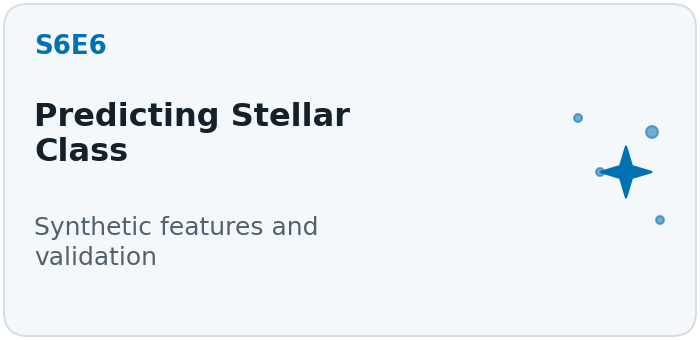</a></div>
<div style="display:inline-block;width:350px;max-width:100%;vertical-align:top;padding:4px;box-sizing:border-box;"><a href="https://www.kaggle.com/code/georgymamarin/s6e7-will-your-0-950-survive-the-private-split">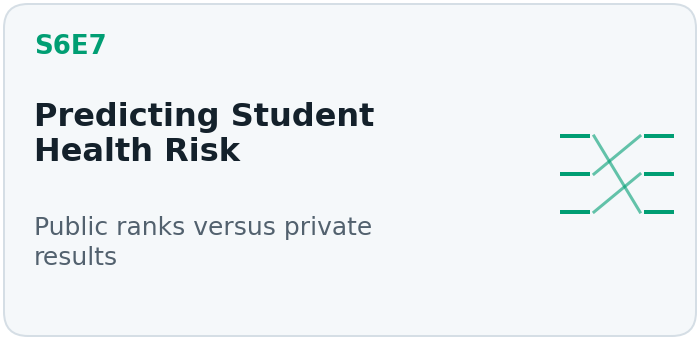</a></div>
<div style="display:inline-block;width:350px;max-width:100%;vertical-align:top;padding:4px;box-sizing:border-box;"><a href="https://www.kaggle.com/code/georgymamarin/s6e8-which-ideas-paid-and-which-ones-fooled-me">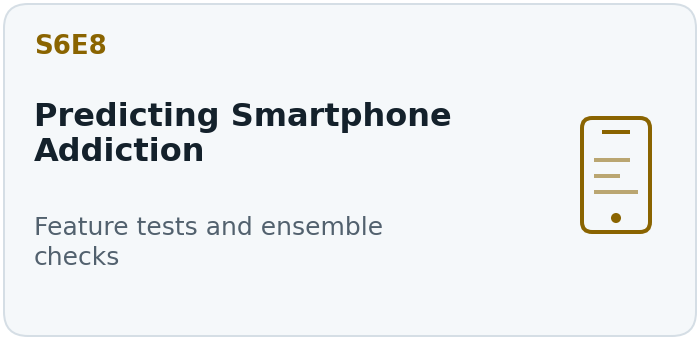</a></div>
<div style="display:inline-block;width:350px;max-width:100%;vertical-align:top;padding:4px;box-sizing:border-box;"><a href="https://www.kaggle.com/code/georgymamarin/s6e9-what-the-board-paid-for-eleven-submissions">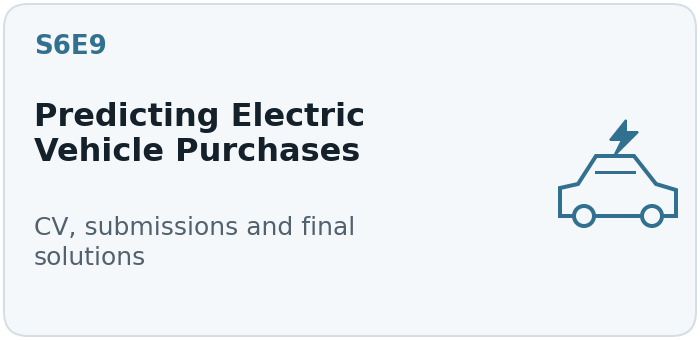</a></div>
<div style="display:inline-block;width:350px;max-width:100%;vertical-align:top;padding:4px;box-sizing:border-box;"><a href="https://www.kaggle.com/code/georgymamarin/s6e10-before-you-pick-your-final-two">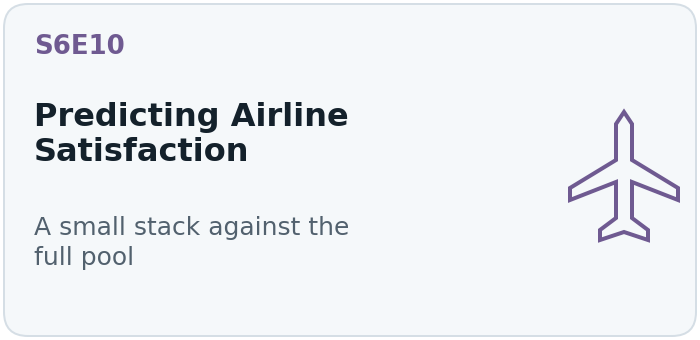</a></div>
</div>

### Sources and thanks

- [Evgeny Dvorkin's data investigation](https://www.kaggle.com/code/evgendvorkin/s6e11-deep-eda-original-data-artifacts) examines original-data fingerprints, risk interactions and all 24 predictors. It is a useful companion for readers who want to study the data before fitting a model.
- The [S6E11 competition page](https://www.kaggle.com/competitions/playground-series-s6e11) specifies the task, metric, files and source attribution.
- [Credit Card Fraud Detection 2026](https://www.kaggle.com/datasets/uditjain13/credit-card-fraud-detection-2026) provides the original CSV and the author's description of its synthetic generation.
- The [scikit-learn target-encoding guide](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.TargetEncoder.html) documents internal cross-fitting. The [XGBoost GPU guide](https://xgboost.readthedocs.io/en/stable/gpu/index.html) describes the CUDA device setting.
- The [LightGBM parameter guide](https://lightgbm.readthedocs.io/en/stable/Parameters.html) and the [scikit-learn ROC AUC documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html) describe the model and scoring behaviour.
- [goodpjw2008's value and digit study](https://www.kaggle.com/code/goodpjw2008/s6e11-part-3-digits-leak-the-label-lb-0-95113) and [Alex Chilton's shallow-tree work](https://www.kaggle.com/code/alexchilton/credit-card-fraud-lb-0-9496-shallow-tree-stack) motivated the bounded representation ablations. Our fixed budgets, encoder implementation and models differ from their published ensembles.
- Will Guesdon's [refined LightGBM recipe](https://www.kaggle.com/code/wguesdon/s6e11-refined-lightgbm) informed H5; [Aphoristic Artist's EDA](https://www.kaggle.com/code/aphoristicartist/s6e11-fraud-eda-3-gbdts-blend-lb-0-9468) motivated the flag-count test.
- The [SciPy permutation-test documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html) explains randomised-test p-value counting. Our scripts implement the specified conditional fixed-count Monte Carlo tests directly.

We thank the organisers, the source author and the library maintainers. If you try another source-transfer or category-encoding recipe, please share its held-out score, fold deltas and exact training setup. Please include results that failed to improve the baseline too.